# GEMS M8 — Physics-guided probabilistic fault discovery

**Central question.** Can physically meaningful potential-field signals, Monte Carlo stability and fault-network completion recover withheld fault systems that B0 / B1 and the M7 generator miss — at a manageable prediction density — and does that become a reproducible gain in geographically validated, official-style DTI?

Recorded M7 offline values (not leaderboard results): `disc_official` DTI B0 raw 0.104, B1 raw 0.092, fusion 0.123, + skeleton 0.128, + crest thinning 0.162, + 300 m ring 0.198. The M7 candidate pool covered ~4.2 % of withheld systems (5 / 120) and 0 of the 93 systems missed by both CNNs.

```text
 Magnetic / Gravity     Terrain / DEM        Known fault map
        |                   |                     |
 potential-field ops   surface morphology    network completion
        +-------------------+---------------------+
                            |
            HIGH-RECALL CANDIDATES (unions, provenance)
                            |
           MONTE CARLO STABILITY / UNCERTAINTY
                            |
        GEOLOGICAL FEATURES  (CNN support + physics + graph context)
                            |
                    CANDIDATE RANKING
                            |
             UNCERTAINTY-AWARE RASTERISATION
                            |
               CROSS-FITTED FUSION -> GEOTIFF
```

**Rules of this notebook**
* No CNN is retrained. B0 / B1 maps and every M7 artifact are reused read-only; M8 writes only under `outputs/m8_physics_probabilistic/`.
* One protocol for every number (official kernel / α / β, known faults masked pixel-exactly, eligible-pixel budget). Every label-dependent choice for a zone is made on the other zones. These zones were inspected before: **not an untouched test set**.
* Profiles (`PILOT` default, `VALIDATE`, `FULL`) change computational scope only — never units, masks, metric, budget, operators or gate thresholds.
* Oracle numbers read the truth: diagnostic upper bounds that decide whether ranking is worth running; they never promote a model.
* **No number exists until the cells run.** Every markdown interpretation below describes how to read possible outcomes; none reports a measurement.

| section | question | gate |
|---|---|---|
| 00 | inputs present and compatible? | stops on CRS / template mismatch |
| 01 | baseline reference under one protocol | compatibility table |
| 02 | where does geological information disappear? | (G1 after 06) |
| 03 / 03b | physics operators, multiscale worms | — |
| 04 | magnetic–gravity, surface–subsurface, context | — |
| 05 | fault-normal profiles | — |
| 06 | high-recall candidates + oracle | **G1, G2** (ranking stops on NO_GO) |
| 07 | Monte Carlo stability | G3 |
| 08 | stochastic network completion | — |
| 09 | DEM pilot increment | G4 |
| 10–13 | features, ranking, (graph), rasterisation | G5 |
| 14 | Systems A / B / C, fusion, verdicts | **G6** |
| 15 | validated GeoTIFFs (never uploaded) | — |

Code: `gems_bench/m8/` · configuration: `configs/m8/physics_probabilistic_discovery.yaml` · guide: `docs/M8_PHYSICS_PROBABILISTIC_DISCOVERY.md`.

## 00. Setup, artifact recovery and compatibility

**Research question.** Are the raw grid, template, folds, splits, B0 / B1 maps and M7 artifacts present and mutually compatible?

**Method.** Mount Drive, install the repository, open the pipeline context (cached data stages are validated and staged, never rebuilt), create `m8 = pipe.m8(M8_CONFIG)`. M8 owns a read-only M7 engine; its GEMS3 engine writes only under `outputs/m8_physics_probabilistic/gems3_engine`.

**Success / failure criterion.** A CRS or template mismatch stops the notebook. Missing optional bands only disable the operators that need them (logged in `manifests/band_availability.csv`).

### Central configuration
`M8_CONFIG` overrides the YAML; unknown keys raise an error naming the closest valid key. `shared` is the M7-schema protocol block (validated by the M7 loader). Expensive / GPU stages are off by default; the default runtime is CPU.

In [4]:
CONFIG = {                                         # master-pipeline context (data stages are only validated / staged)
    'repo': 'mybenkhadda/GEMS---drivendata',
    'ref': 'gems3-discovery-research',               # branch or commit SHA
    'drive_root': '/content/drive/MyDrive/GEMS_2',
    'local_root': '/content/gems_work',
    'run_mode': 'PREPARE_DATA',                      # data stages reuse Drive; M8 never trains CNNs
    'failure_policy': 'interactive',
    'download_missing': False,
    'run_advanced_models': False, 'train_baselines': [], 'run_full_inference': False, 'run_submission': False,
    'feature_stage': 'lazy',
    'use_gpu': False,                                # PILOT is CPU-only
    'seed': 2026,
}
DEM_CONFIG = {'enabled': False, 'mode': 'inventory_only', 'download': False}
PRIVATE_REPO = False

M8_CONFIG = {
    'profile': 'FULL',                              # PILOT | VALIDATE | FULL (computational scope only)
    'profile_overrides': {},                         # e.g. {'mc_realizations': 32}: scope keys only
    'overwrite_existing': False,                     # True recomputes M8 stages (immutable tables are kept)
    'sections': {                                    # independent switches
        's01_baseline': True,                        # baseline recovery
        's02_signal_recovery': True,                 # signal-recovery diagnostics
        's03_potential_fields': True,                # potential-field transformations
        's03b_structural_worms': True,               # multiscale worms
        's04_multimodal': True,                      # magnetic-gravity alignment, surface-subsurface, context
        's05_fault_normal_profiles': True,           # fault-normal profiles
        's06_candidates': True,                      # candidate generation + oracle gate
        's07_monte_carlo_signal': True,              # Monte Carlo signal perturbation
        's08_monte_carlo_completion': True,          # Monte Carlo network completion
        's09_dem_pilot': True,                       # DEM pilot (never blocks other sections)
        's10_candidate_features': True,              # candidate features
        's11_ranking': True,                         # LightGBM ranking
        's12_graph': False,                          # probabilistic graph experiment (optional)
        's13_rasterization': True,                   # probabilistic rasterisation
        's14_ensemble': True,                        # cross-fitted fusion + gates + report
        's15_submission': True,                     # submission generation (never uploads)
    },
    'shared': {                                      # M7-schema protocol (units, budget, PU labels, promotion rules)
        'models': ['b0_reference', 'b1_bg_weight'],
        'submission': {'source': 'oof_stitched', 'area_frac_source': 'geo'},   # 'fold_average' needs a GPU
        'dem': {'download': False},
    },
    'bands': {'verified': {}, 'units': {}},          # confirmed derivative definitions / units (else PROVISIONAL)
    'monte_carlo': {'measured_noise': {}},           # {family: sigma} -> measured uncertainty instead of heuristic
    'dem_pilot': {'reuse_m7': True, 'stream': False},
    'ranking': {'force': False},
}
SHOW_FIGURES = True                                  # figure display (saving is controlled by save_figures)

In [5]:
import base64, os, subprocess, sys
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
REPO_URL = f"https://github.com/{CONFIG['repo']}.git"

def _git_env():
    if not PRIVATE_REPO:
        return None
    from google.colab import userdata
    tok = userdata.get('GITHUB_TOKEN') or ''
    hdr = base64.b64encode(f'x-access-token:{tok}'.encode()).decode()
    return {**os.environ, 'GIT_CONFIG_COUNT': '1', 'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
            'GIT_CONFIG_VALUE_0': f'AUTHORIZATION: basic {hdr}'}

def git(*args, auth=False, check=True):
    r = subprocess.run(['git', *args], capture_output=True, text=True, env=_git_env() if auth else None)
    if check and r.returncode != 0:
        raise RuntimeError(f"git {' '.join(args[:3])} failed:\n{r.stderr.strip()[-1500:]}")
    return r

if not os.path.exists(f'{CODE}/.git'):
    git('clone', '-q', REPO_URL, CODE, auth=True)
git('-C', CODE, 'remote', 'set-url', 'origin', REPO_URL)
git('-C', CODE, 'fetch', '-q', '--tags', 'origin', auth=True)
ref = CONFIG['ref']
before = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
if git('-C', CODE, 'rev-parse', '--verify', '-q', f'refs/remotes/origin/{ref}', check=False).returncode == 0:
    git('-C', CODE, 'checkout', '-q', ref)
    git('-C', CODE, 'merge', '-q', '--ff-only', f'origin/{ref}')
else:
    git('-C', CODE, 'checkout', '-q', '--detach', ref)
HEAD = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', f'{CODE}[colab]'], check=True)
if CODE not in sys.path:
    sys.path.insert(0, CODE)
os.environ['GEMS_CODE_COMMIT'] = HEAD
print('code @', HEAD)
if 'gems_bench' in sys.modules and HEAD != before:
    raise RuntimeError('Code changed after gems_bench was imported: Runtime -> Restart session, then run from the top.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
code @ f6330eebb3a5d5cd8000c12713d84d7cdba1bde9


In [6]:
import json, pathlib
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
from gems_bench.pipeline import Pipeline

pipe = Pipeline.from_notebook(CONFIG, DEM_CONFIG)
pipe.step('bootstrap')
for s in ('raw_data', 'native_grid', 'spatial_folds', 'discovery_splits', 'feature_store'):
    pipe.step(s)                                     # validated on Drive and staged locally (never regenerated)

m8 = pipe.m8(M8_CONFIG)
OUT = m8.ws.root
print('profile:', m8.profile)
print('M8 outputs (local):', OUT)
print('M8 outputs (Drive):', m8.cfg['_drive_root'])
print('M7 artifacts (read-only):', m8.m7.ws.root)

def show(names, sub):
    if not (SHOW_FIGURES and m8.cfg.get('display_figures', True)):
        return
    for n in names:
        p = OUT / sub / f'{n}.png'
        display(Image(filename=str(p))) if p.exists() else print('not produced:', sub, n)

def tab(name, sub, n=30):
    t = m8.ws.load_table(name, sub)
    display(t.head(n)) if len(t) else print('empty / not produced:', sub, name)
    return t

[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/bootstrap.json']
[bootstrap] DONE: bootstrap: ok (3 checks)
[bootstrap] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/config_snapshot.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/environment_report.csv']
[raw_data] SKIP_CACHED: raw_data: ok (3 checks)
[raw_data] outputs: ['/content/drive/MyDrive/GEMS_2/data/raw/acquisition_manifest.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/raw_data_acquisition.csv']
[sync in] 0 copied (0.0 MiB), 1 unchanged, 0s: ['environment/pipeline/native_grid.json']
[native_grid] SKIP_CACHED: native_grid: ok (1 checks)
[native_grid] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/native_grid.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/native_band_table.csv']
[sync in] 0 copied (0.0 MiB), 3 u

In [7]:
setup = m8.s00_setup()                    # read-only; raises if CRS / template checks fail
print(json.dumps({k: v for k, v in setup['checks'].items() if k != 'bands'}, indent=1, default=str))
display(setup['bands'])
display(setup['inventory'])               # integration inventory: reused functions, files, consumers, assumptions
display(m8.m7.protocol_keys())

[pipeline] research context without segment attributes (geological_eda / segment_attributes not available yet): segment-stratified metrics are skipped
[sync out] 8 copied (0.0 MiB), 0 unchanged, 0s: ['outputs/m8_physics_probabilistic/gems3_engine/inventory']
      model   status          experiment_id profile  n_disc_maps reasons
P5_B0_gated COMPLETE b0_reference__d54e938a    FULL            3        
  P5_B1_bgw COMPLETE b1_bg_weight__7755635b    FULL            3        
[sync in] 68 copied (66.5 MiB), 0 unchanged, 23s: ['experiments/b0_reference__d54e938a/manifest.json', 'experiments/b0_reference__d54e938a/config.yaml', 'experiments/b0_reference__d54e938a/metrics', 'experiments/b0_reference__d54e938a/reports', 'experiments/b0_reference__d54e938a/predictions/oof.tif', 'experiments/b0_reference__d54e938a/predictions/disc0.tif', 'experiments/b0_reference__d54e938a/predictions/disc1.tif', 'experiments/b0_reference__d54e938a/predictions/disc2.tif', 'experiments/b1_bg_weight__7755635b/man

,band,available,description
0,cond_surf,True,Conductivity surface - electrical conductivity...
1,depth_to_base_surf,True,Depth to basement surface - thickness of sedim...
2,deq_n100a15,True,"Distance to earthquake (n=100km radius, a=15° ..."
3,det_elev,True,Detrended elevation - topography with regional...
4,det_elev_slope,True,Detrended elevation slope - gradient of elevat...
5,geod_2ndinv,True,Geodetic second invariant - measure of strain ...
6,geod_dilaterate,True,Geodetic dilatation rate - rate of volumetric ...
7,geod_shearrate,True,Geodetic shear rate - rate of angular deformat...
8,ieq_n100a15,True,Earthquake intensity or density (n=100km radiu...
9,iso_grav_anom,True,Isostatic gravity anomaly - gravity after comp...


,existing_function,original_file,m8_consumer,change,compatibility_assumption
0,NativeData.read_band / read_window / valid / l...,gems_bench/data/__init__.py,"layers, signal_recovery, profiles, montecarlo",none,"EPSG:32611, 100 m, NaN nodata (|v| > 1e30 masked)"
1,gems_eda.enhance.fill_nan / nan_gaussian,gems_eda/enhance.py,"potential_fields, multimodal",none,nearest fill before derivative filters
2,rs_features.prank,gems_bench/rs_features.py,"multimodal, completion, graph",none,label-free percentile against a fixed valid sa...
3,"M7Research (units, elig, pkey, protocol_keys, ...",gems_bench/m7/run.py,"run (composition, read-only)",none; its GEMS3 engine is re-pointed to output...,M7 stage methods that write are never called b...
4,gems3.official.Unit / FastScorer / build_units...,gems_bench/gems3/official.py,every evaluation,none,"official kernel R = 300 m, alpha 0.2, beta 0.8..."
5,m7.protocol.eligible / protocol_key / score_ro...,gems_bench/m7/protocol.py,"baseline, signal_recovery, candidates, monteca...",none,eligible budget domain = scored & template-fin...
6,m7.baseline.run / heldout_map / MemberMaps,gems_bench/m7/baseline.py,"baseline, ensemble",none,nested selection on the other zones; reused on...
7,m7.failure.run / system_attributes / case_window,gems_bench/m7/failure.py,"baseline, figures",none,system = label pixels linked within 1 km (ctx....
8,m7.generator.response / _nms / gated_crests / ...,gems_bench/m7/generator.py,"candidates, worms, signal_recovery, montecarlo",none,"1-px crest lines, provenance kept in sources /..."
9,gems3.candidates.CandidateSet / tip_paths / to...,gems_bench/gems3/candidates.py,all candidate code,none,paths in unit crop coordinates


,task,zone,unit,protocol_key,eval_px,scored_truth_px,excluded_px,eligible_px_ring0,supports_tp,budget_domain,include_template
0,geo,0,geo:0,b205c189d912f6d6,1887813,18707,0,1886771,True,eligible,True
1,geo,1,geo:1,b25ca968e42356b6,1548292,22008,0,1548011,True,eligible,True
2,geo,2,geo:2,05af38c9a21f40c3,1729747,20179,0,1729530,True,eligible,True
3,disc_official,0,disc_official:0,5320855164c2bc4a,1784107,7579,51104,1766770,False,eligible,True
4,disc_official,1,disc_official:1,2f6b1f343577d8c0,1848909,7469,52246,1833733,False,eligible,True
5,disc_official,2,disc_official:2,f83455114bf2b99f,1724912,7282,53704,1707276,False,eligible,True
6,disc_retained_fp,0,disc_retained_fp:0,7cbc11074414c2fd,1784107,7579,0,1783947,True,eligible,True
7,disc_retained_fp,1,disc_retained_fp:1,6688d52112b7f459,1848909,7469,0,1848688,True,eligible,True
8,disc_retained_fp,2,disc_retained_fp:2,582cdb094c471ed5,1724912,7282,0,1724500,True,eligible,True


## 01. Recover the baselines and establish the reference

**Research question.** Under the shared protocol, what are B0, B1, their rank fusion, crest / skeleton thinning and the 300 m ring worth — and are the M7 artifacts compatible with today's grid, folds, splits, models and metric?

**Geological rationale.** A new geological signal matters only if it beats the strongest existing model on the same evaluation; historical numbers came from several protocols.

**Hypothesis.** The M7 nested selection is reusable (protocol keys match) and System A = fusion + crest thinning remains the strongest ring-free method.

**Method.** Reuse M7's `baseline_selection.json` only when the protocol keys stored in its immutable table equal the current units' keys; otherwise recompute with M7's code. Rebuild every per-zone held-out map (`validation/maps/s01_*`), reload / recompute the per-system B0 / B1 recovery classes, run the compatibility checks (CRS, extent, transform, nodata, fold and split ids, model configuration, map fingerprints, metric constants, budget domain, score-map processing).

**Planned diagnostic.** `baseline/compatibility.csv`, `recorded_vs_this_run.csv` (the `source` column states whether values were recomputed here), `baseline_dti.png`, `baseline_manifest.json`.

**Success / failure criterion.** No compatibility row `DIFFERS`. A difference to recorded M7 values is reported, never reconciled, and never claimed as a reproduction unless `source` says recomputed.

**How to read the outcome.** If keys differ, every later comparison uses the recomputed selection and M7 numbers are context only. If the ring variant is best, remember the proxy under-represents new faults next to known traces.

[sync in] 211 copied (107.2 MiB), 0 unchanged, 43s: ['outputs/m7_discovery_first/recovered_baselines', 'outputs/m7_discovery_first/manifests', 'outputs/m7_discovery_first/failure_analysis/tables', 'outputs/m7_discovery_first/candidate_generation/oracle', 'outputs/m7_discovery_first/candidate_generation/tables', 'outputs/m7_discovery_first/candidate_generation/vectors/units', 'outputs/m7_discovery_first/map_completion/metrics', 'outputs/m7_discovery_first/map_completion/candidates', 'outputs/m7_discovery_first/dem/pilot', 'outputs/m7_discovery_first/dem/inventory']
[m8] s01_baseline: computed in 123s -> /content/gems_work/outputs/m8_physics_probabilistic
[sync out] 85 copied (37.0 MiB), 18 unchanged, 1s: ['outputs/m8_physics_probabilistic']


,task,method,dti_crossfit,fold_min,optimism,area_frac_eligible_mean,dti_zone0,dti_zone1,dti_zone2
0,geo,b0_raw,0.114916,0.103642,0.000000,NaN,0.137510,0.104690,0.103642
1,geo,b1_raw,0.117896,0.098272,0.000000,NaN,0.142860,0.098272,0.115495
2,geo,b0_binary,0.164790,0.153838,0.000609,0.058334,0.153838,0.156462,0.180040
3,geo,b1_binary,0.168196,0.163476,0.003194,0.066667,0.173754,0.163476,0.166196
4,geo,fusion_binary,0.177637,0.166628,0.001329,0.050000,0.186279,0.166628,0.179892
5,geo,fusion_crest_1px,0.182832,0.169650,0.005460,0.043334,0.194885,0.169650,0.181268
6,geo,fusion_skeleton_1px,0.179978,0.179010,0.002466,0.046451,0.179366,0.181592,0.179010
7,geo,fusion_thin,0.182832,0.169650,0.005460,0.043334,0.194885,0.169650,0.181268
8,disc_official,b0_raw,0.103920,0.062775,0.000000,NaN,0.122258,0.127436,0.062775
9,disc_official,b1_raw,0.091741,0.064188,0.000000,NaN,0.095572,0.116785,0.064188


,task,method,recorded_m7_offline,value_this_run,difference,source,note
0,disc_official,b0_raw,0.10392,0.103920,4.306522e-07,reused M7 selection (protocol keys match); hel...,"recorded = earlier M7 run (offline, not leader..."
1,disc_official,b1_raw,0.09174,0.091741,9.867662e-07,reused M7 selection (protocol keys match); hel...,"recorded = earlier M7 run (offline, not leader..."
2,disc_official,fusion_binary,0.12254,0.122537,-2.967529e-06,reused M7 selection (protocol keys match); hel...,"recorded = earlier M7 run (offline, not leader..."
3,disc_official,fusion_skeleton_1px,0.12797,0.127967,-2.675539e-06,reused M7 selection (protocol keys match); hel...,"recorded = earlier M7 run (offline, not leader..."
4,disc_official,fusion_crest_1px,0.16158,0.161576,-3.787317e-06,reused M7 selection (protocol keys match); hel...,"recorded = earlier M7 run (offline, not leader..."
5,disc_official,fusion_thin_ring300,0.19831,0.198308,-1.931632e-06,reused M7 selection (protocol keys match); hel...,"recorded = earlier M7 run (offline, not leader..."


,check,current,m7_recorded,status,note
0,crs_epsg,32611,32611,MATCH,required EPSG:32611
1,raster_shape,"[3730, 3292]","[3730, 3292]",MATCH,
2,pixel_m,"[100.0, 100.0]","[100.0, 100.0]",MATCH,
3,"template_same_grid (transform, extent, shape, ...",true,true,MATCH,
4,template_nodata,NaN,null,RECORDED,template nodata value (authority)
5,feature_nodata,-3.4028234663852886e+38,null,RECORDED,
6,valid_frac,0.420701,0.420701,MATCH,
7,template_valid_frac,0.420825,0.420825,MATCH,
8,label_px,60988,60988,MATCH,
9,fold_ids,"[0, 1, 2]","[0, 1, 2]",MATCH,


{
 "selection_source": "reused M7 selection (protocol keys match); held-out maps rebuilt here",
 "reuse_reason": "protocol keys match for ['geo', 'disc_official']",
 "system_table_source": "M7 failure analysis (read-only)",
 "models": [
  "P5_B0_gated",
  "P5_B1_bgw"
 ],
 "model_stems": [
  "b0_reference",
  "b1_bg_weight"
 ],
 "map_fingerprints": {
  "P5_B0_gated": "7056ae7ef9a5f31f",
  "P5_B1_bgw": "fbaca0822b25ee2d"
 },
 "m7_experiment_ids": {
  "s00_setup": null,
  "s01_baseline": "m7_s01_baseline_a0dc2f542f",
  "s02_failure_analysis": "m7_s02_failure_analysis_7b58d0b25f",
  "s02b_case_studies": "m7_s02b_case_studies_d0010de5a9",
  "s03_candidates": "m7_s03_candidates_41af0cf1f3",
  "s04_oracle": "m7_s04_oracle_cabff4d54a",
  "s05_dem_inventory": "m7_s05_dem_inventory_da0c4d57b5",
  "s08_network_analysis": "m7_s08_network_analysis_617534f33c",
  "s09_corruption_benchmark": "m7_s09_corruption_benchmark_909660f773",
  "s13_comparison": "m7_s13_comparison_44b0f427eb",
  "s14_decision_

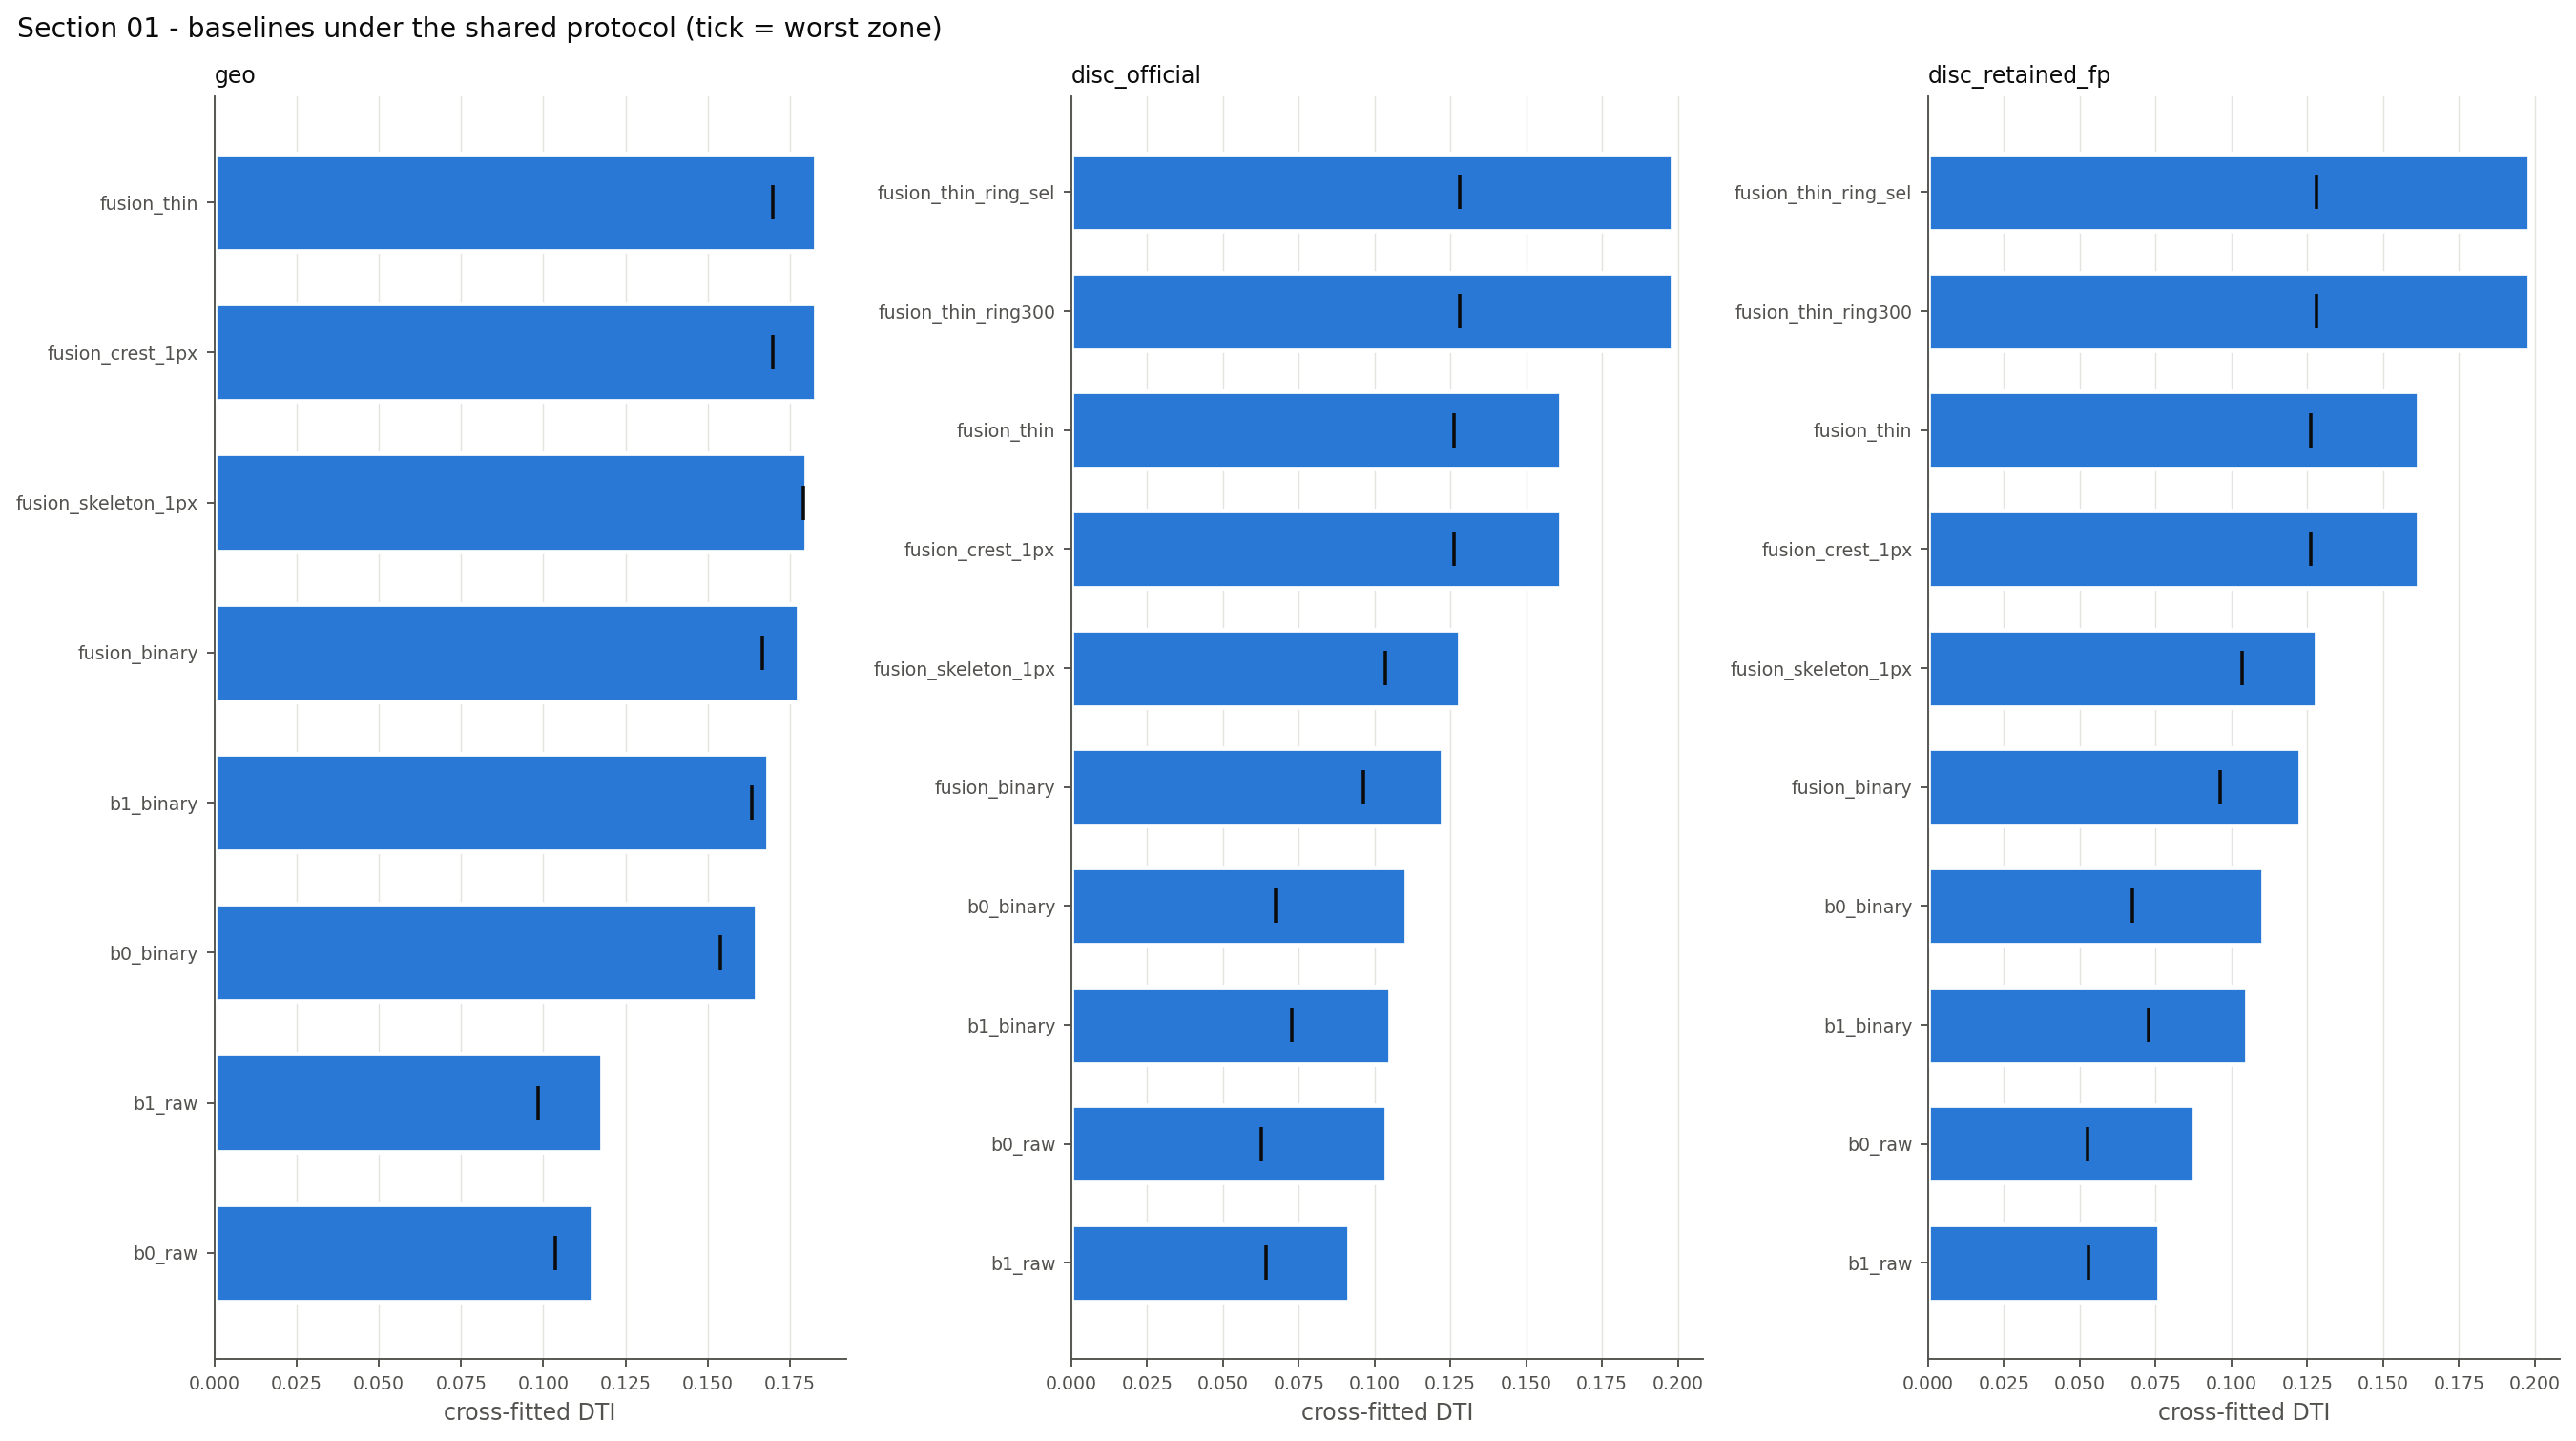

In [8]:
if m8.enabled('s01_baseline'):
    s01 = m8.s01_baseline()
    t = s01['table']
    display(t[[c for c in ('task', 'method', 'dti_crossfit', 'fold_min', 'optimism', 'area_frac_eligible_mean',
                           'dti_zone0', 'dti_zone1', 'dti_zone2') if c in t]])
    display(s01['recorded'])
    comp = s01['compatibility']
    display(comp)
    if len(comp) and (comp.status == 'DIFFERS').any():
        print('WARNING: compatibility differences:', comp[comp.status == 'DIFFERS'].check.tolist())
    print(json.dumps(m8.read_json('baseline/baseline_manifest.json'), indent=1, default=str)[:3000])
    show(['baseline_dti'], 'baseline')

## 02. Where does geological information disappear? — the first decisive experiment

**Research question.** For each withheld fault system, at which step of the extraction chain does its signal stop: raw field → structural gradient → normalised response → directional edge → crest → gated fragment → persistence filter → linked polyline → ranked candidate?

**Geological rationale.** A fault is visible in potential fields only when it juxtaposes contrasting rocks or offsets a basement surface; it can then be lost by smoothing, global thresholds, coherence gates, short-length filters or ranking. Each loss has a different remedy.

**Hypothesis.** A substantial share of systems missed by both CNNs still carries a raw response that the M7 chain discards (an extraction bottleneck), rather than no response at all.

**Method.** Per system and modality (magnetic, gravity, terrain, conductivity, basement): three raw-response definitions (cross-strike contrast, gradient percentile, local / regional variance) each tested against a **system-matched null** (the same trace rigidly translated 3–12 km to valid ground away from mapped faults); stages 2–9 as coverage within one pixel. Failure reason = first stage lost. All label use is diagnostic.

**Planned diagnostic.** `signal_recovery/stage_matrix`, `reasons` (failure_reason / failure_category), `stage_recall` (system- and length-weighted, by length, strike, region, B0/B1 class), `missed_by_both_by_stage`, `stage_density`, `stage_funnel.png`, 8-panel case studies for the eight required classes.

**Success / failure criterion.** Descriptive: the section succeeds when each system has a reason. It feeds Gate 1 (evaluated after section 06).

**How to read the outcome.** Many `raw_present -> crest_missing` / `fragment_missing` rows → fix extraction (local thresholds, operators). Many `persistent -> linked_missing` → length / linking filters. `linked -> ranked_missing` → ranking / density. `raw_response_absent` under all definitions → information limit at 100 m *for these operators* (DEM or other data may help); it is not proof of invisibility.

[m8] s02 disc_official:0: 38 systems
[m8] s02 disc_official:1: 38 systems
[m8] s02 disc_official:2: 44 systems
[m8] s02 geo:0: 158 systems
[m8] s02 geo:1: 241 systems
[m8] s02 geo:2: 217 systems


/content/GEMS/gems_bench/m8/signal_recovery.py:490: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  p["n_raw_modalities"] = p[raws].fillna(False).astype(bool).sum(axis=1) if raws else 0
/content/GEMS/gems_bench/m8/figures.py:56: RuntimeWarning: Mean of empty slice
  nn = np.nanmean(np.stack([np.asarray(x, np.float32) for x in maps]), 0)
/content/GEMS/gems_bench/m8/figures.py:56: RuntimeWarning: Mean of empty slice
  nn = np.nanmean(np.stack([np.asarray(x, np.float32) for x in maps]), 0)
/content/GEMS/gems_bench/m8/figures.py:56: RuntimeWarning: Mean of empty slice
  nn = np.nanmean(np.stack([np.asarray(x, np.float32) for x in maps]), 0)
/content/GEMS/gems_bench/m8/figures.py:56: RuntimeWarning: Mean of empty slice
  nn = np.nanmean(np.stack([np.asarray(x, np.float32) for 

[m8] s02_signal_recovery: computed in 2071s -> /content/gems_work/outputs/m8_physics_probabilistic
[sync out] 152 copied (54.5 MiB), 102 unchanged, 2s: ['outputs/m8_physics_probabilistic']


,task,failure_category,n_systems
0,disc_official,extraction_bottleneck,98
1,disc_official,information_limit_under_tested_operators,1
2,disc_official,operator_beyond_raw_definitions,21
3,geo,extraction_bottleneck,484
4,geo,information_limit_under_tested_operators,7
5,geo,operator_beyond_raw_definitions,122
6,geo,recovered,3


,task,failure_reason,n_systems
9,geo,crest_present -> fragment_missing,160
13,geo,normalized_present -> directional_missing,127
18,geo,raw_response_absent but gradient_present,96
15,geo,raw_present -> gradient_missing,86
10,geo,directional_present -> crest_missing,79
0,disc_official,crest_present -> fragment_missing,34
4,disc_official,normalized_present -> directional_missing,23
1,disc_official,directional_present -> crest_missing,21
19,geo,raw_response_absent but normalized_present,20
7,disc_official,raw_response_absent but gradient_present,19


stage                          crest  directional  fragment  gradient  \
task          modality                                                  
disc_official any           0.658333     0.583333  0.008333  0.850000   
              basement      0.000000     0.125000  0.000000  0.175000   
              conductivity  0.000000     0.033333  0.000000  0.116667   
              gravity       0.000000     0.108333  0.000000  0.208333   
              magnetic      0.041667     0.100000  0.000000  0.258333   
              terrain       0.075000     0.141667  0.008333  0.308333   
geo           any           0.662338     0.525974  0.042208  0.806818   
              basement      0.012987     0.129870  0.003247  0.207792   
              conductivity  0.009740     0.087662  0.009740  0.191558   
              gravity       0.017857     0.120130  0.003247  0.207792   
              magnetic      0.137987     0.129870  0.022727  0.321429   
              terrain       0.163961     0.120130  0.014610  0.235390   

stage                         linked  normalized  persistent    ranked  \
task          modality                                                   
disc_official any           0.000000    0.933333    0.000000  0.000000   
              basement      0.000000    0.000000    0.000000  0.000000   
              conductivity  0.000000    0.083333    0.000000  0.000000   
              gravity       0.000000    0.325000    0.000000  0.000000   
              magnetic      0.000000    0.633333    0.000000  0.000000   
              terrain       0.000000    0.350000    0.000000  0.000000   
geo           any           0.016234    0.909091    0.024351  0.016234   
              basement      0.004870    0.000000    0.003247  0.004870   
              conductivity  0.009740    0.175325    0.009740  0.009740   
              gravity       0.003247    0.336039    0.001623  0.003247   
              magnetic      0.009740    0.620130    0.012987  0.009740   
              terrain       0.008117    0.318182    0.006494  0.008117   

stage                            raw  
task          modality                
disc_official any           0.816667  
              basement      0.350000  
              conductivity  0.283333  
              gravity       0.391667  
              magnetic      0.358333  
              terrain       0.450000  
geo           any           0.790584  
              basement      0.314935  
              conductivity  0.279221  
              gravity       0.353896  
              magnetic      0.347403  
              terrain       0.392857

,task,modality,stage,n_missed_by_both,recovered_at_stage
0,disc_official,any,raw,93,74
1,disc_official,any,gradient,93,76
2,disc_official,any,normalized,93,85
3,disc_official,any,directional,93,52
4,disc_official,any,crest,93,61
5,disc_official,any,fragment,93,0
6,disc_official,any,persistent,93,0
7,disc_official,any,linked,93,0
8,disc_official,any,ranked,93,0
9,disc_official,basement,raw,93,30


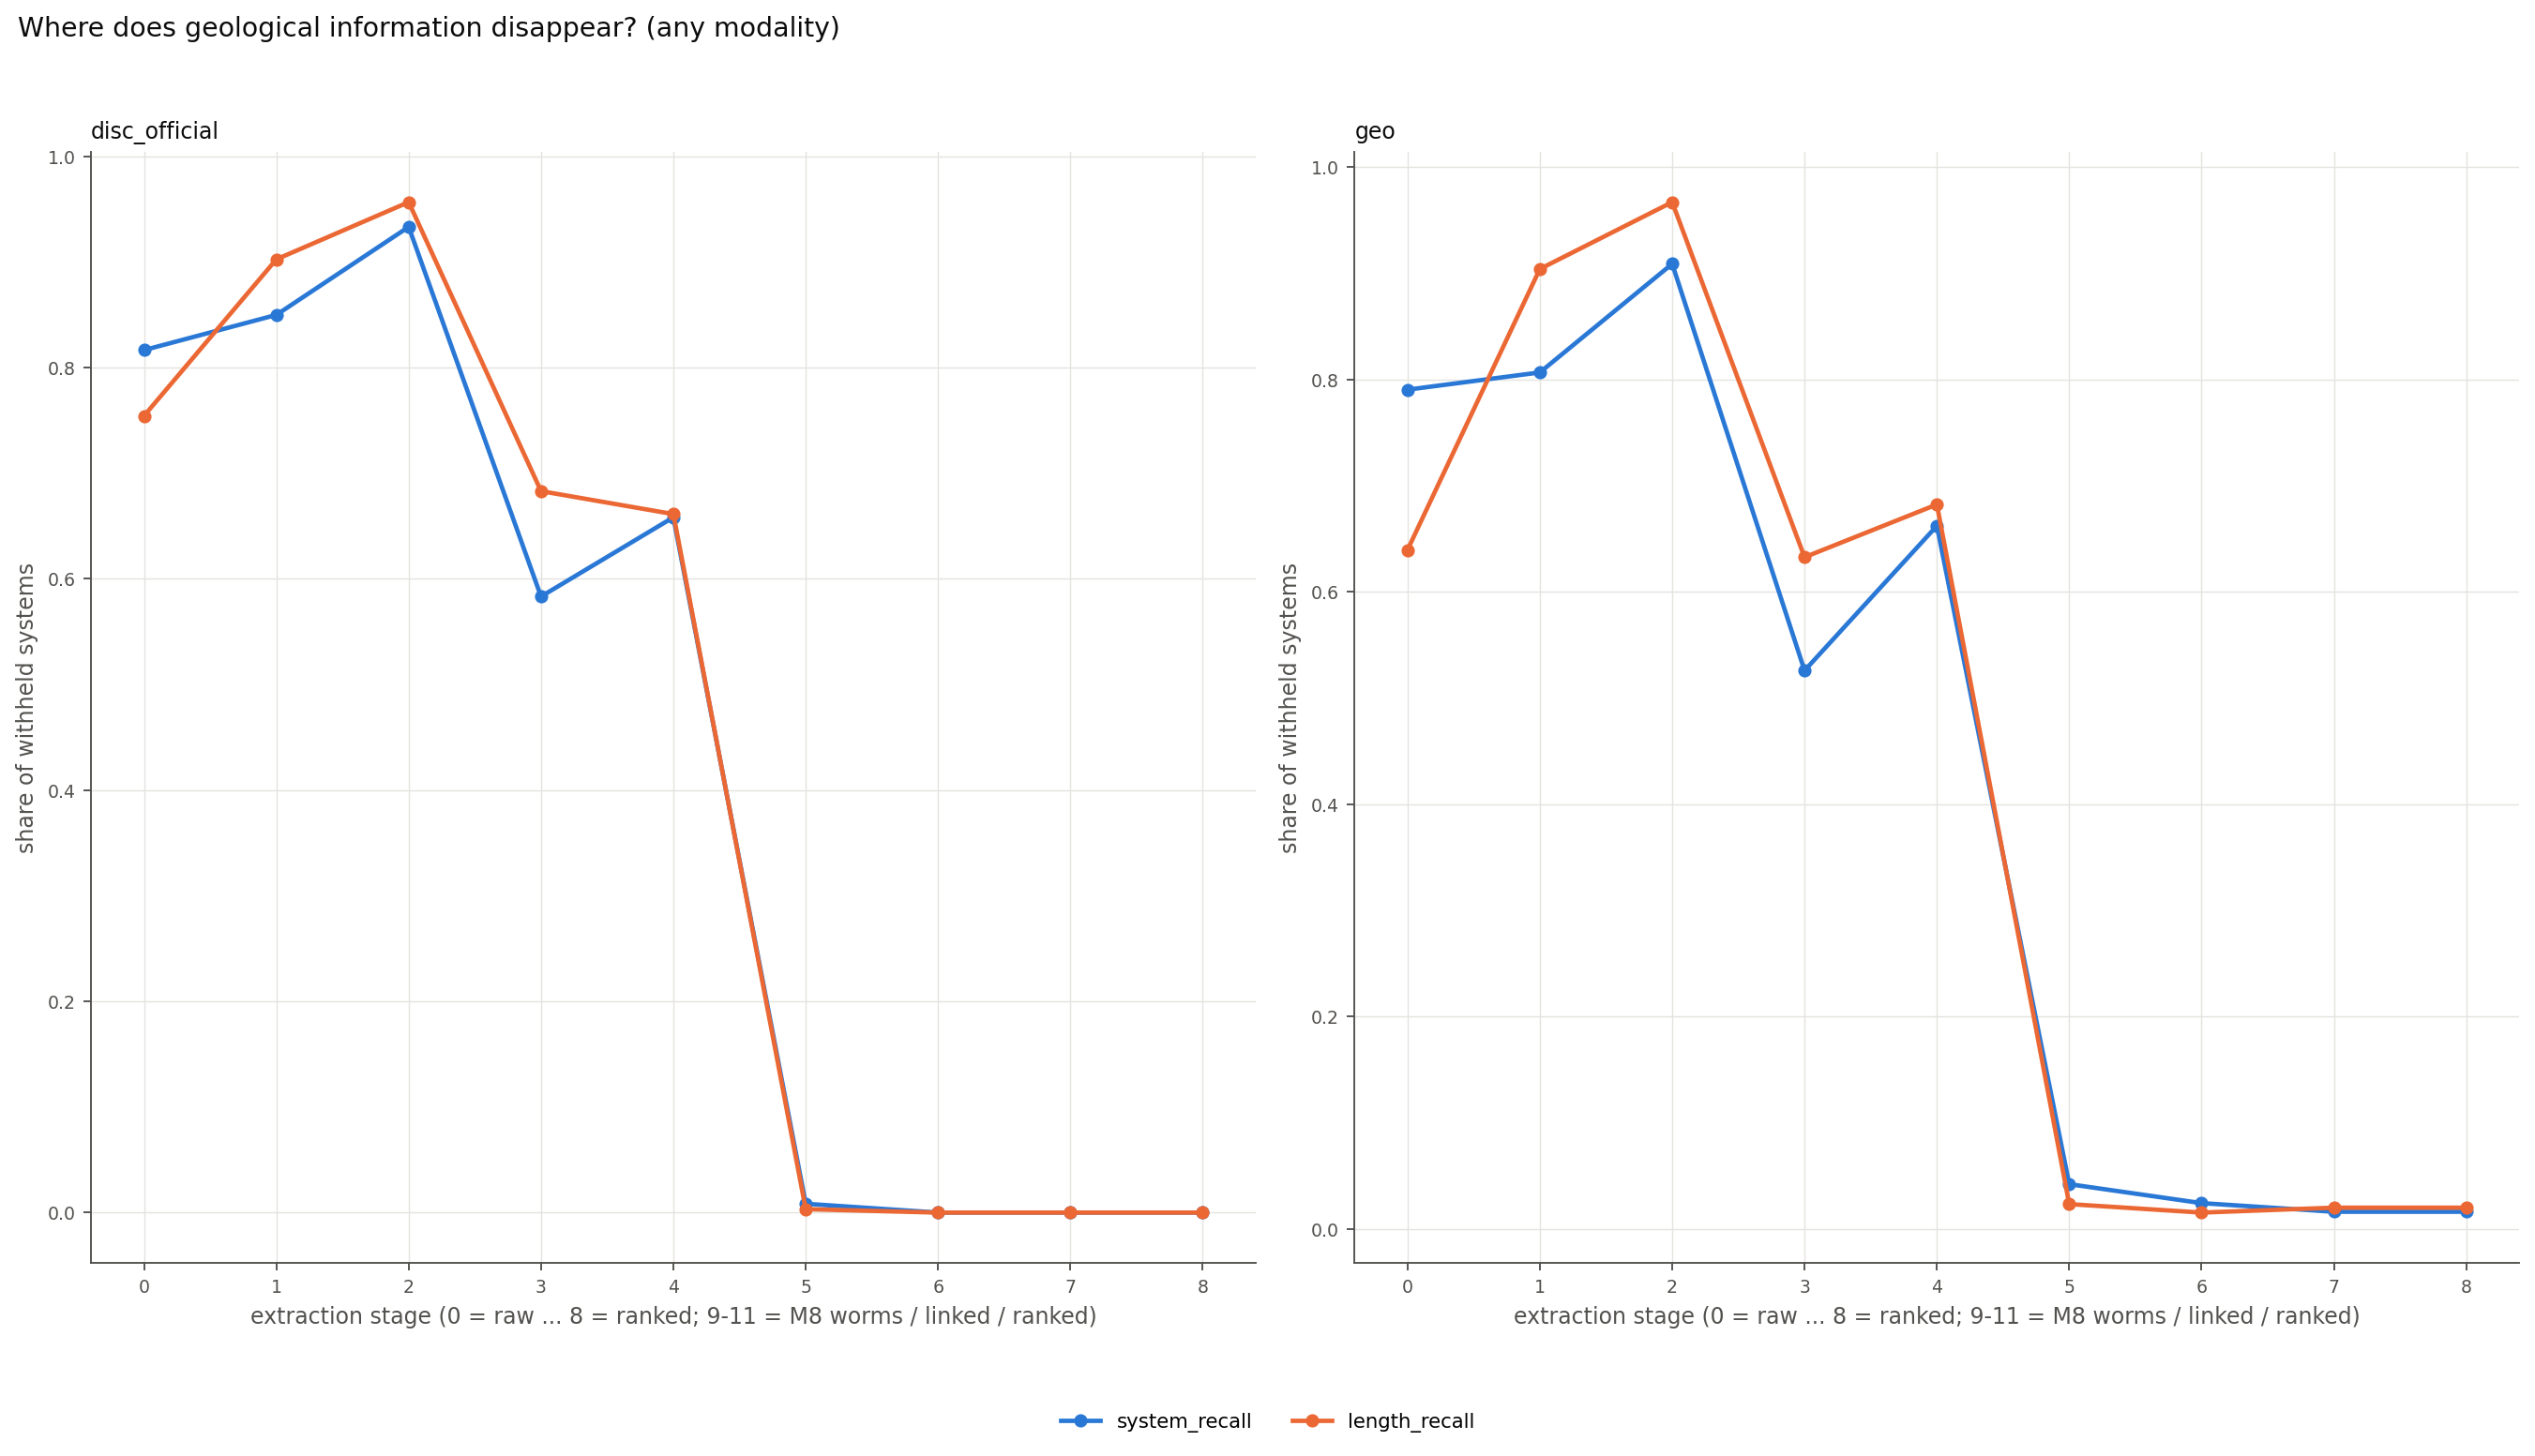

,task,zone,system_id,linked@any,linked@basement,linked@conductivity,linked@gravity,linked@magnetic,linked@terrain,raw@any,...,raw@terrain,n_raw_modalities,class,trace_km,region_name,strike_deg,regional_only,case_class,figure,arrays
0,geo,2,530,False,False,False,False,False,False,True,...,False,1,neither,11.00,CC,80.823026,False,both_miss,both_miss__geo_z2_sys530.png,both_miss__geo_z2_sys530.npz
1,geo,2,492,False,False,False,False,False,False,False,...,False,0,neither,97.46,CC,150.771100,False,both_miss,both_miss__geo_z2_sys492.png,both_miss__geo_z2_sys492.npz
2,disc_official,0,254,False,False,False,False,False,False,True,...,False,3,neither,10.67,NW,19.474156,False,both_miss,both_miss__disc_official_z0_sys254.png,both_miss__disc_official_z0_sys254.npz
3,geo,1,229,False,False,False,False,False,False,True,...,False,1,neither,5.50,NW,40.813415,False,both_miss,both_miss__geo_z1_sys229.png,both_miss__geo_z1_sys229.npz
4,geo,1,301,False,False,False,False,False,False,True,...,True,2,both,1.87,NC,29.516944,False,cnn_detects_structural_misses,cnn_detects_structural_misses__geo_z1_sys301.png,cnn_detects_structural_misses__geo_z1_sys301.npz
5,geo,2,134,False,False,False,False,False,False,True,...,True,2,b1_only,5.50,NC,173.117838,False,cnn_detects_structural_misses,cnn_detects_structural_misses__geo_z2_sys134.png,cnn_detects_structural_misses__geo_z2_sys134.npz
6,geo,2,6,False,False,False,False,False,False,True,...,False,2,b0_only,43.56,NC,168.362033,False,cnn_detects_structural_misses,cnn_detects_structural_misses__geo_z2_sys6.png,cnn_detects_structural_misses__geo_z2_sys6.npz
7,geo,0,559,False,False,False,False,False,False,True,...,True,4,both,17.27,SC,27.979528,False,cnn_detects_structural_misses,cnn_detects_structural_misses__geo_z0_sys559.png,cnn_detects_structural_misses__geo_z0_sys559.npz
8,geo,1,356,False,False,False,False,False,False,True,...,False,2,neither,5.83,CW,74.492916,False,crossmodal_response_missed_candidate,crossmodal_response_missed_candidate__geo_z1_s...,crossmodal_response_missed_candidate__geo_z1_s...
9,geo,0,572,False,False,False,False,False,False,True,...,False,2,neither,2.97,SC,5.355702,False,crossmodal_response_missed_candidate,crossmodal_response_missed_candidate__geo_z0_s...,crossmodal_response_missed_candidate__geo_z0_s...


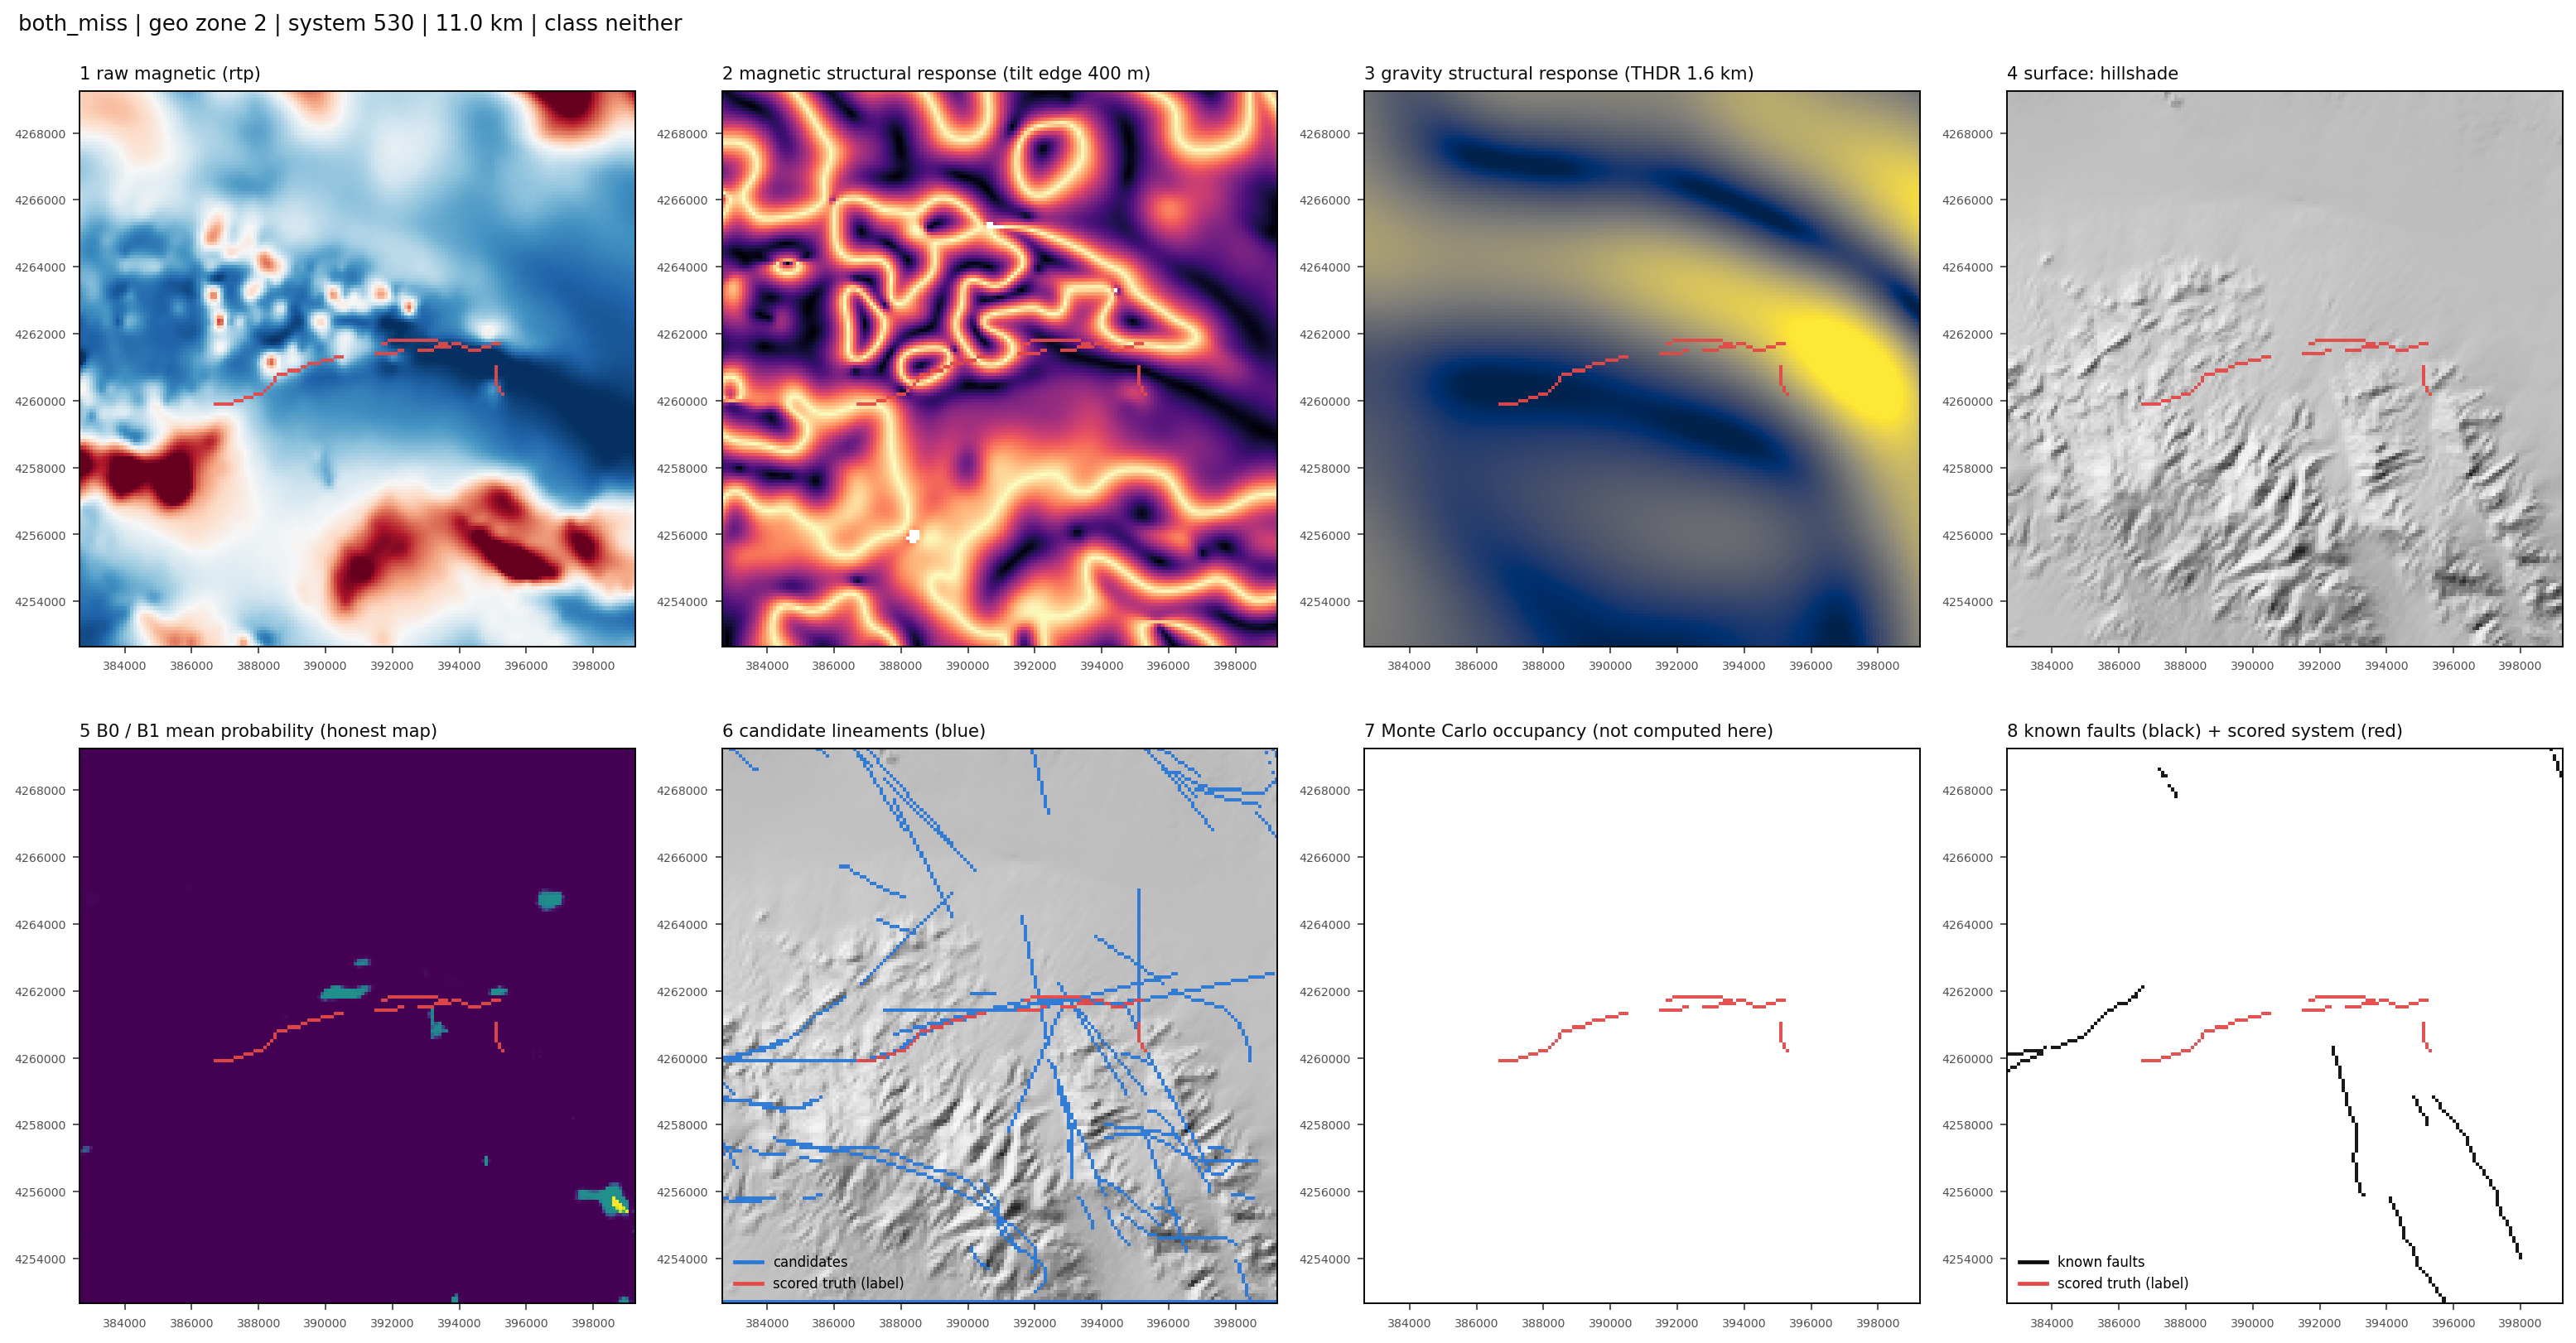

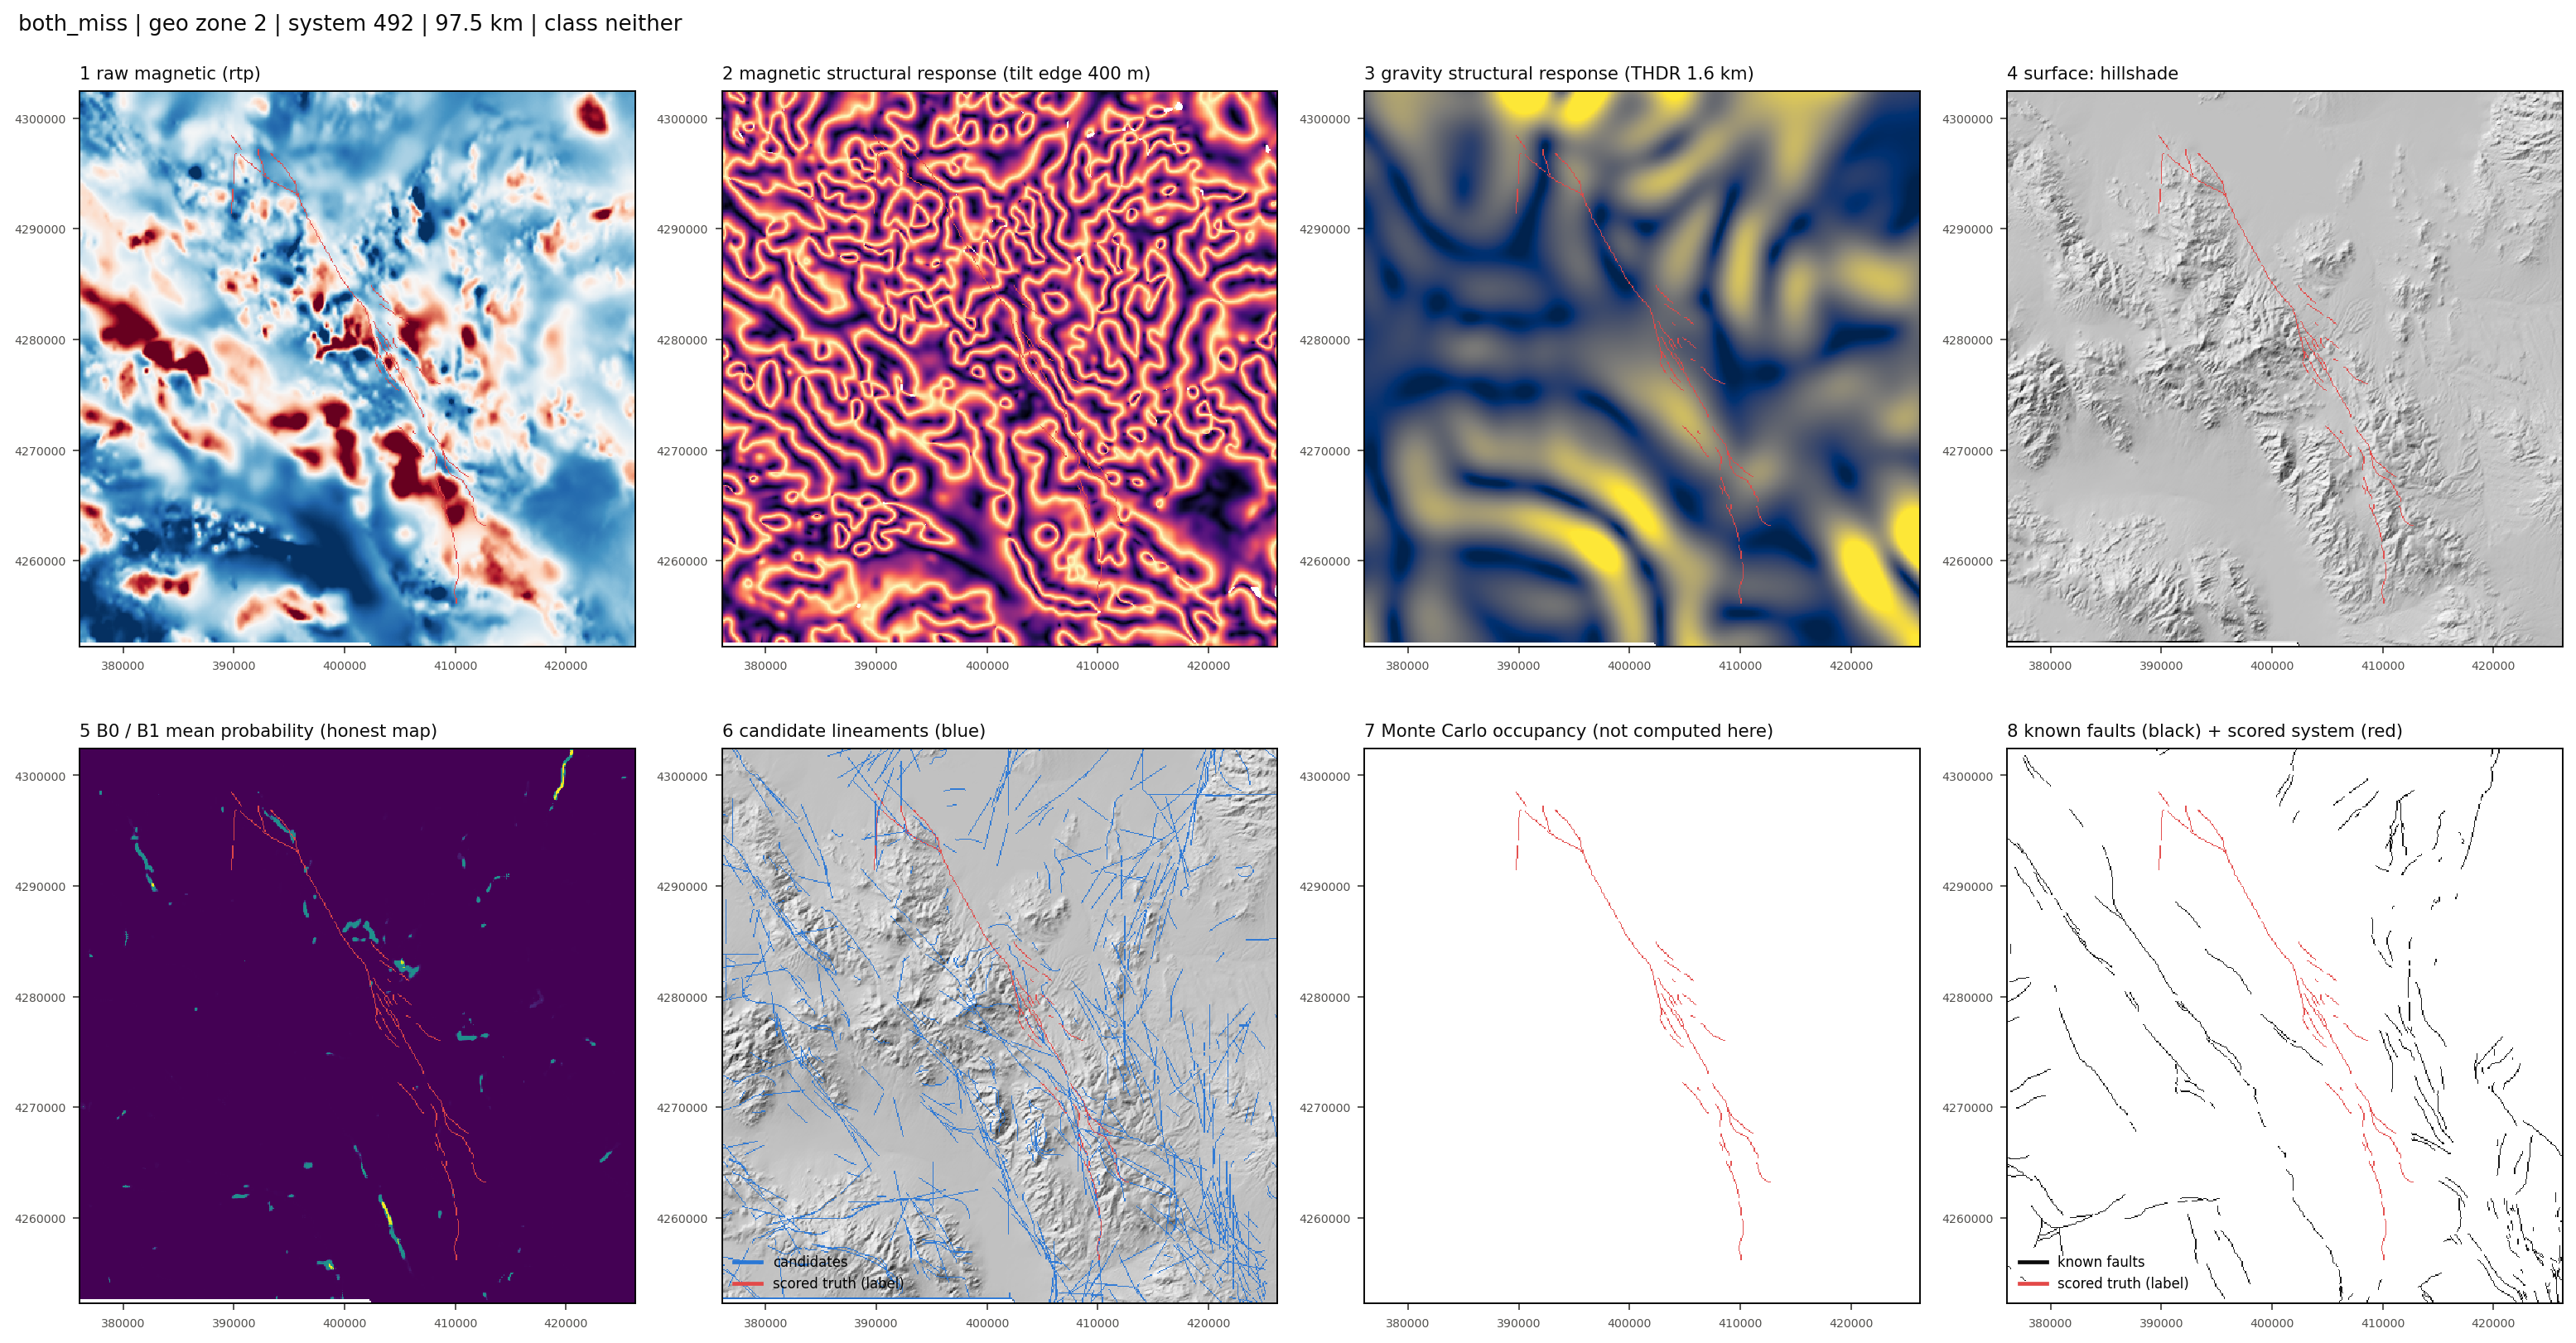

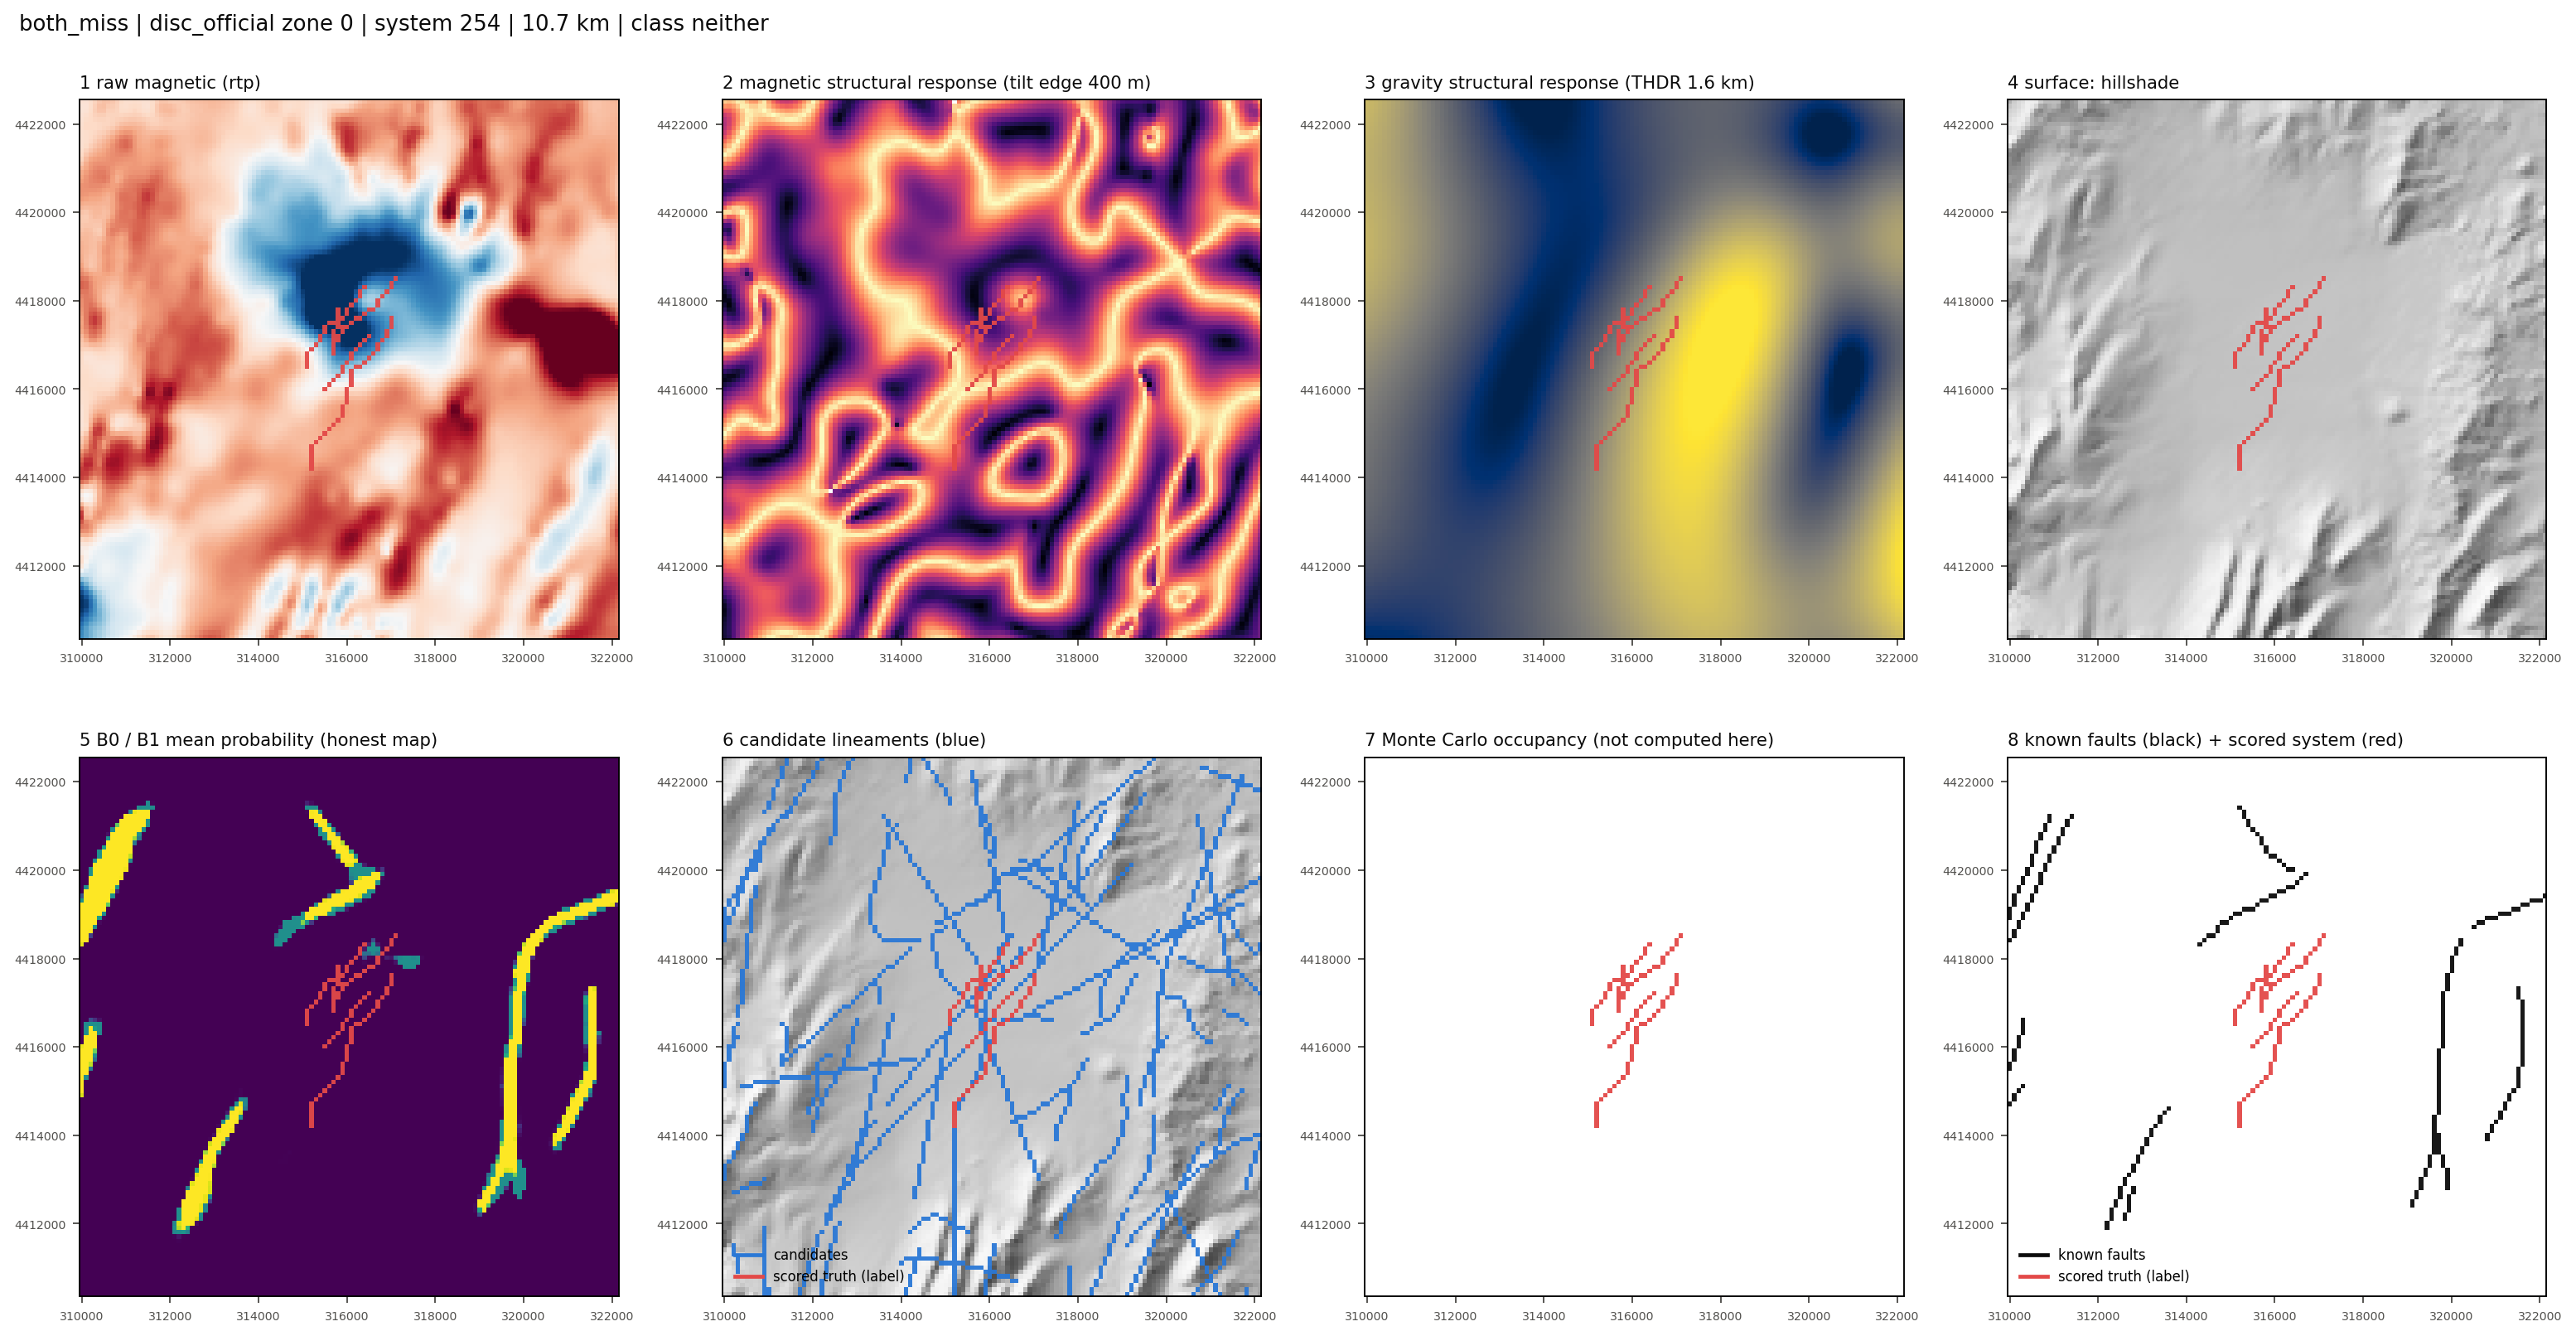

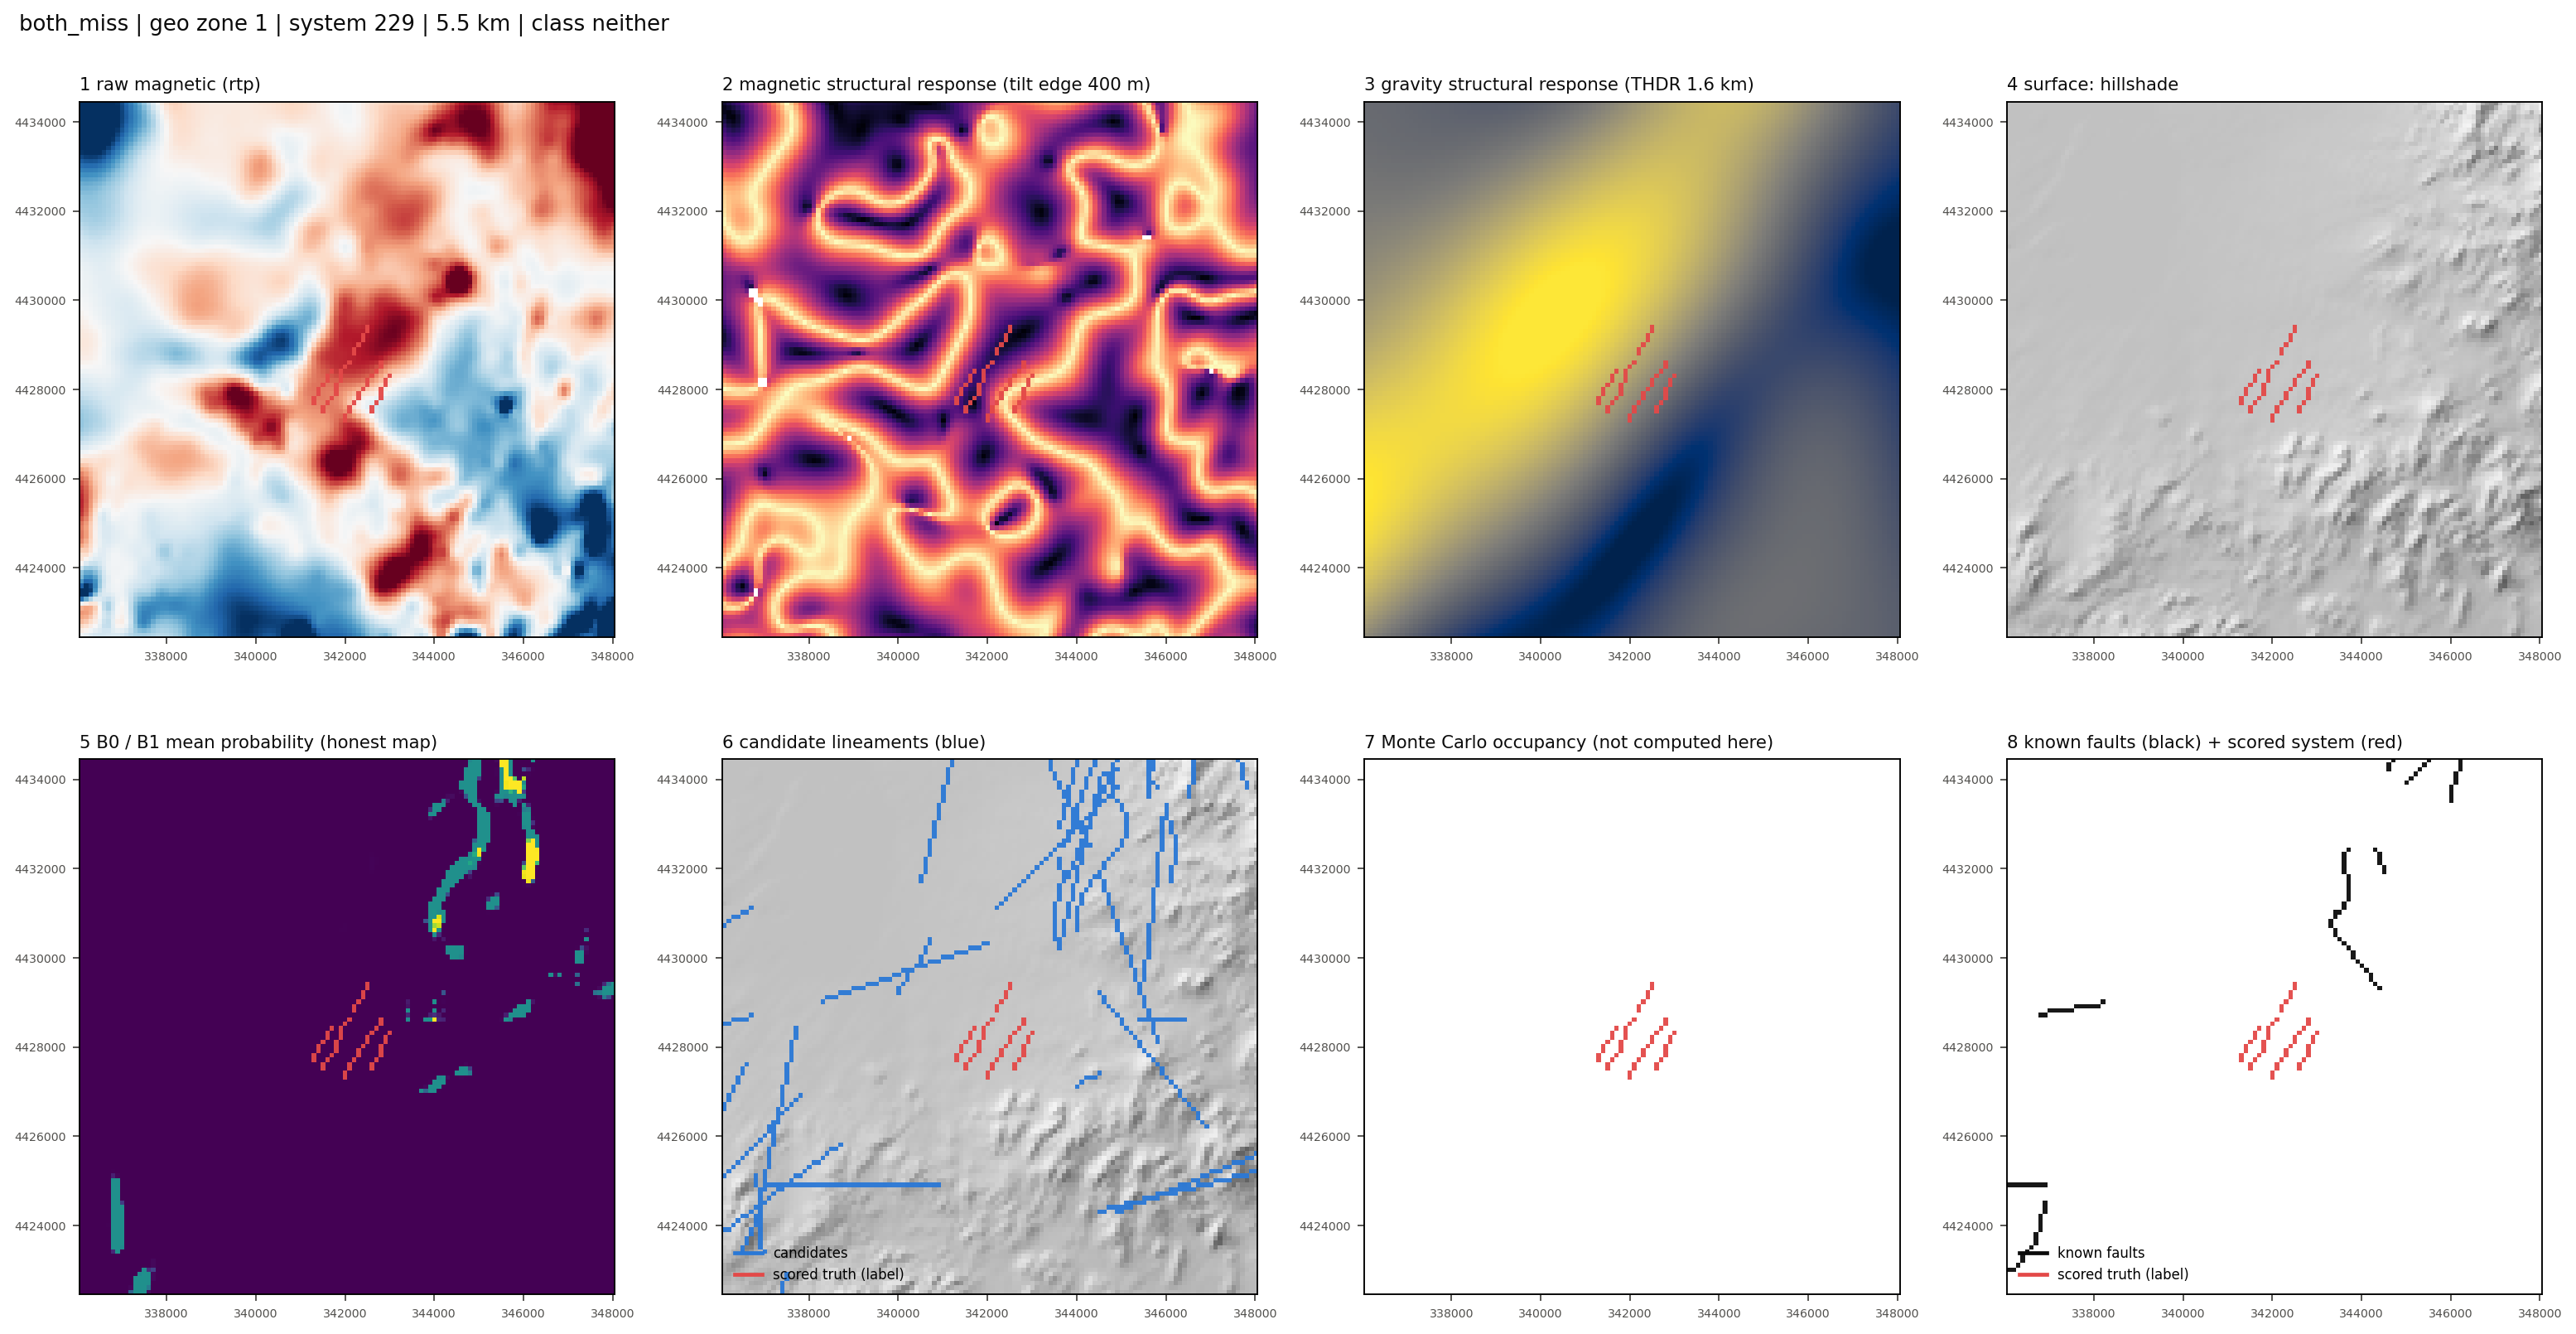

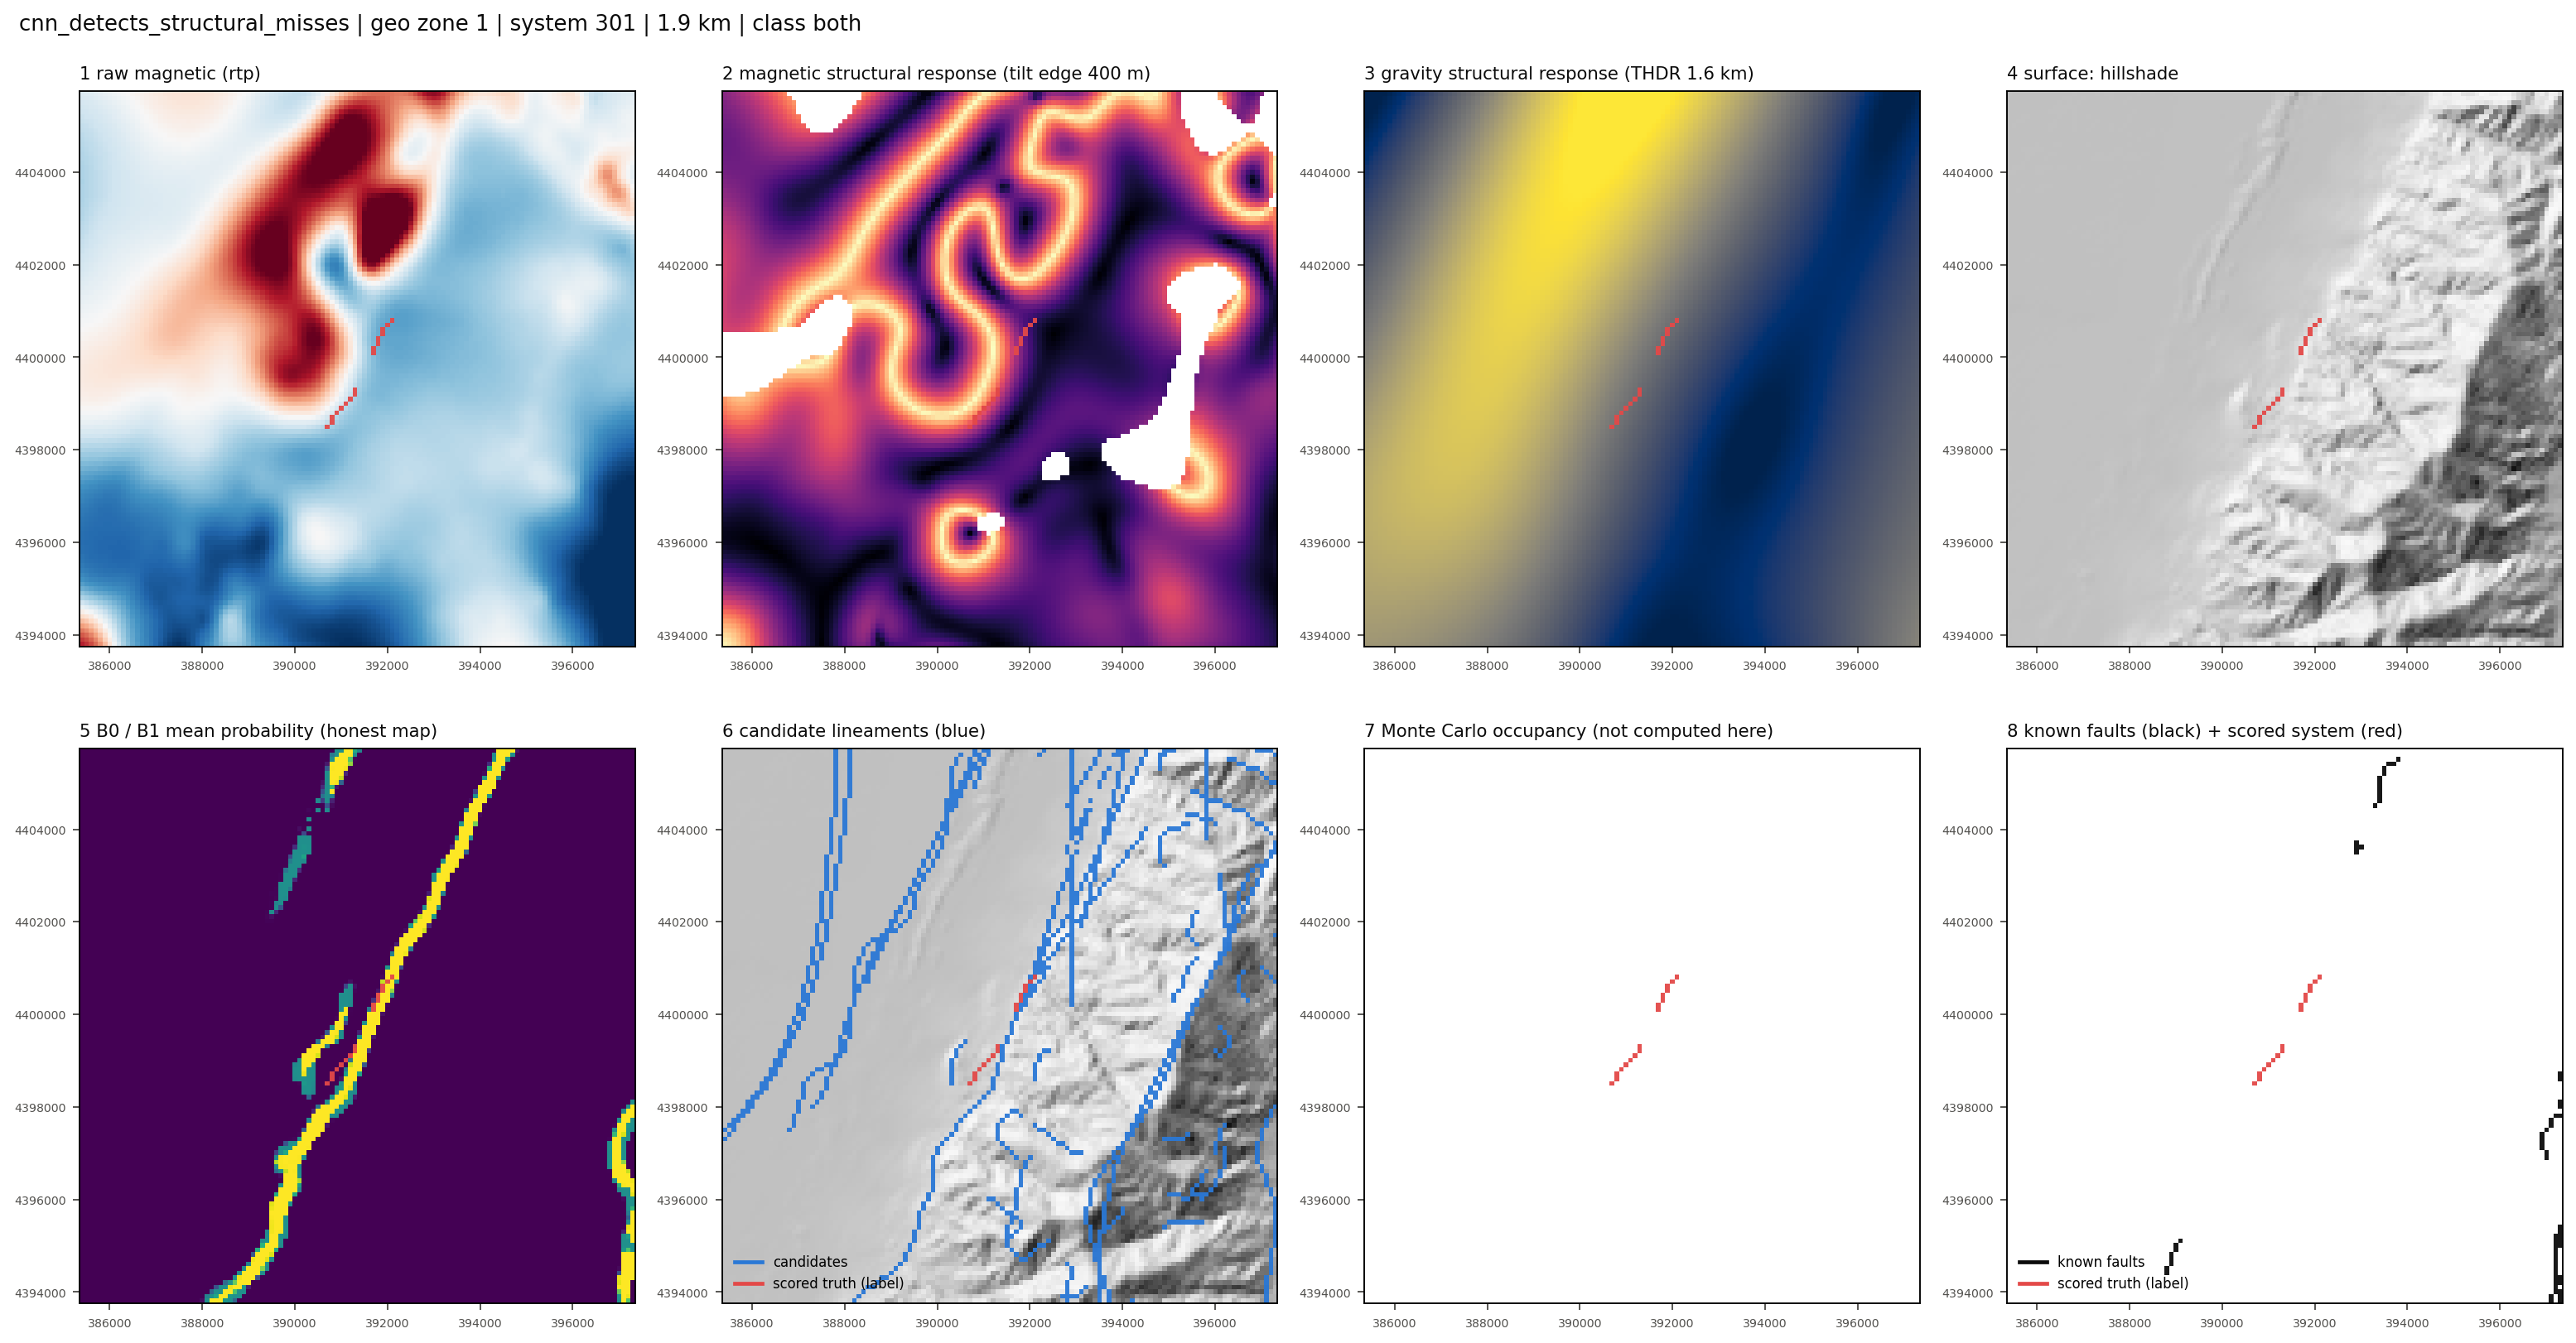

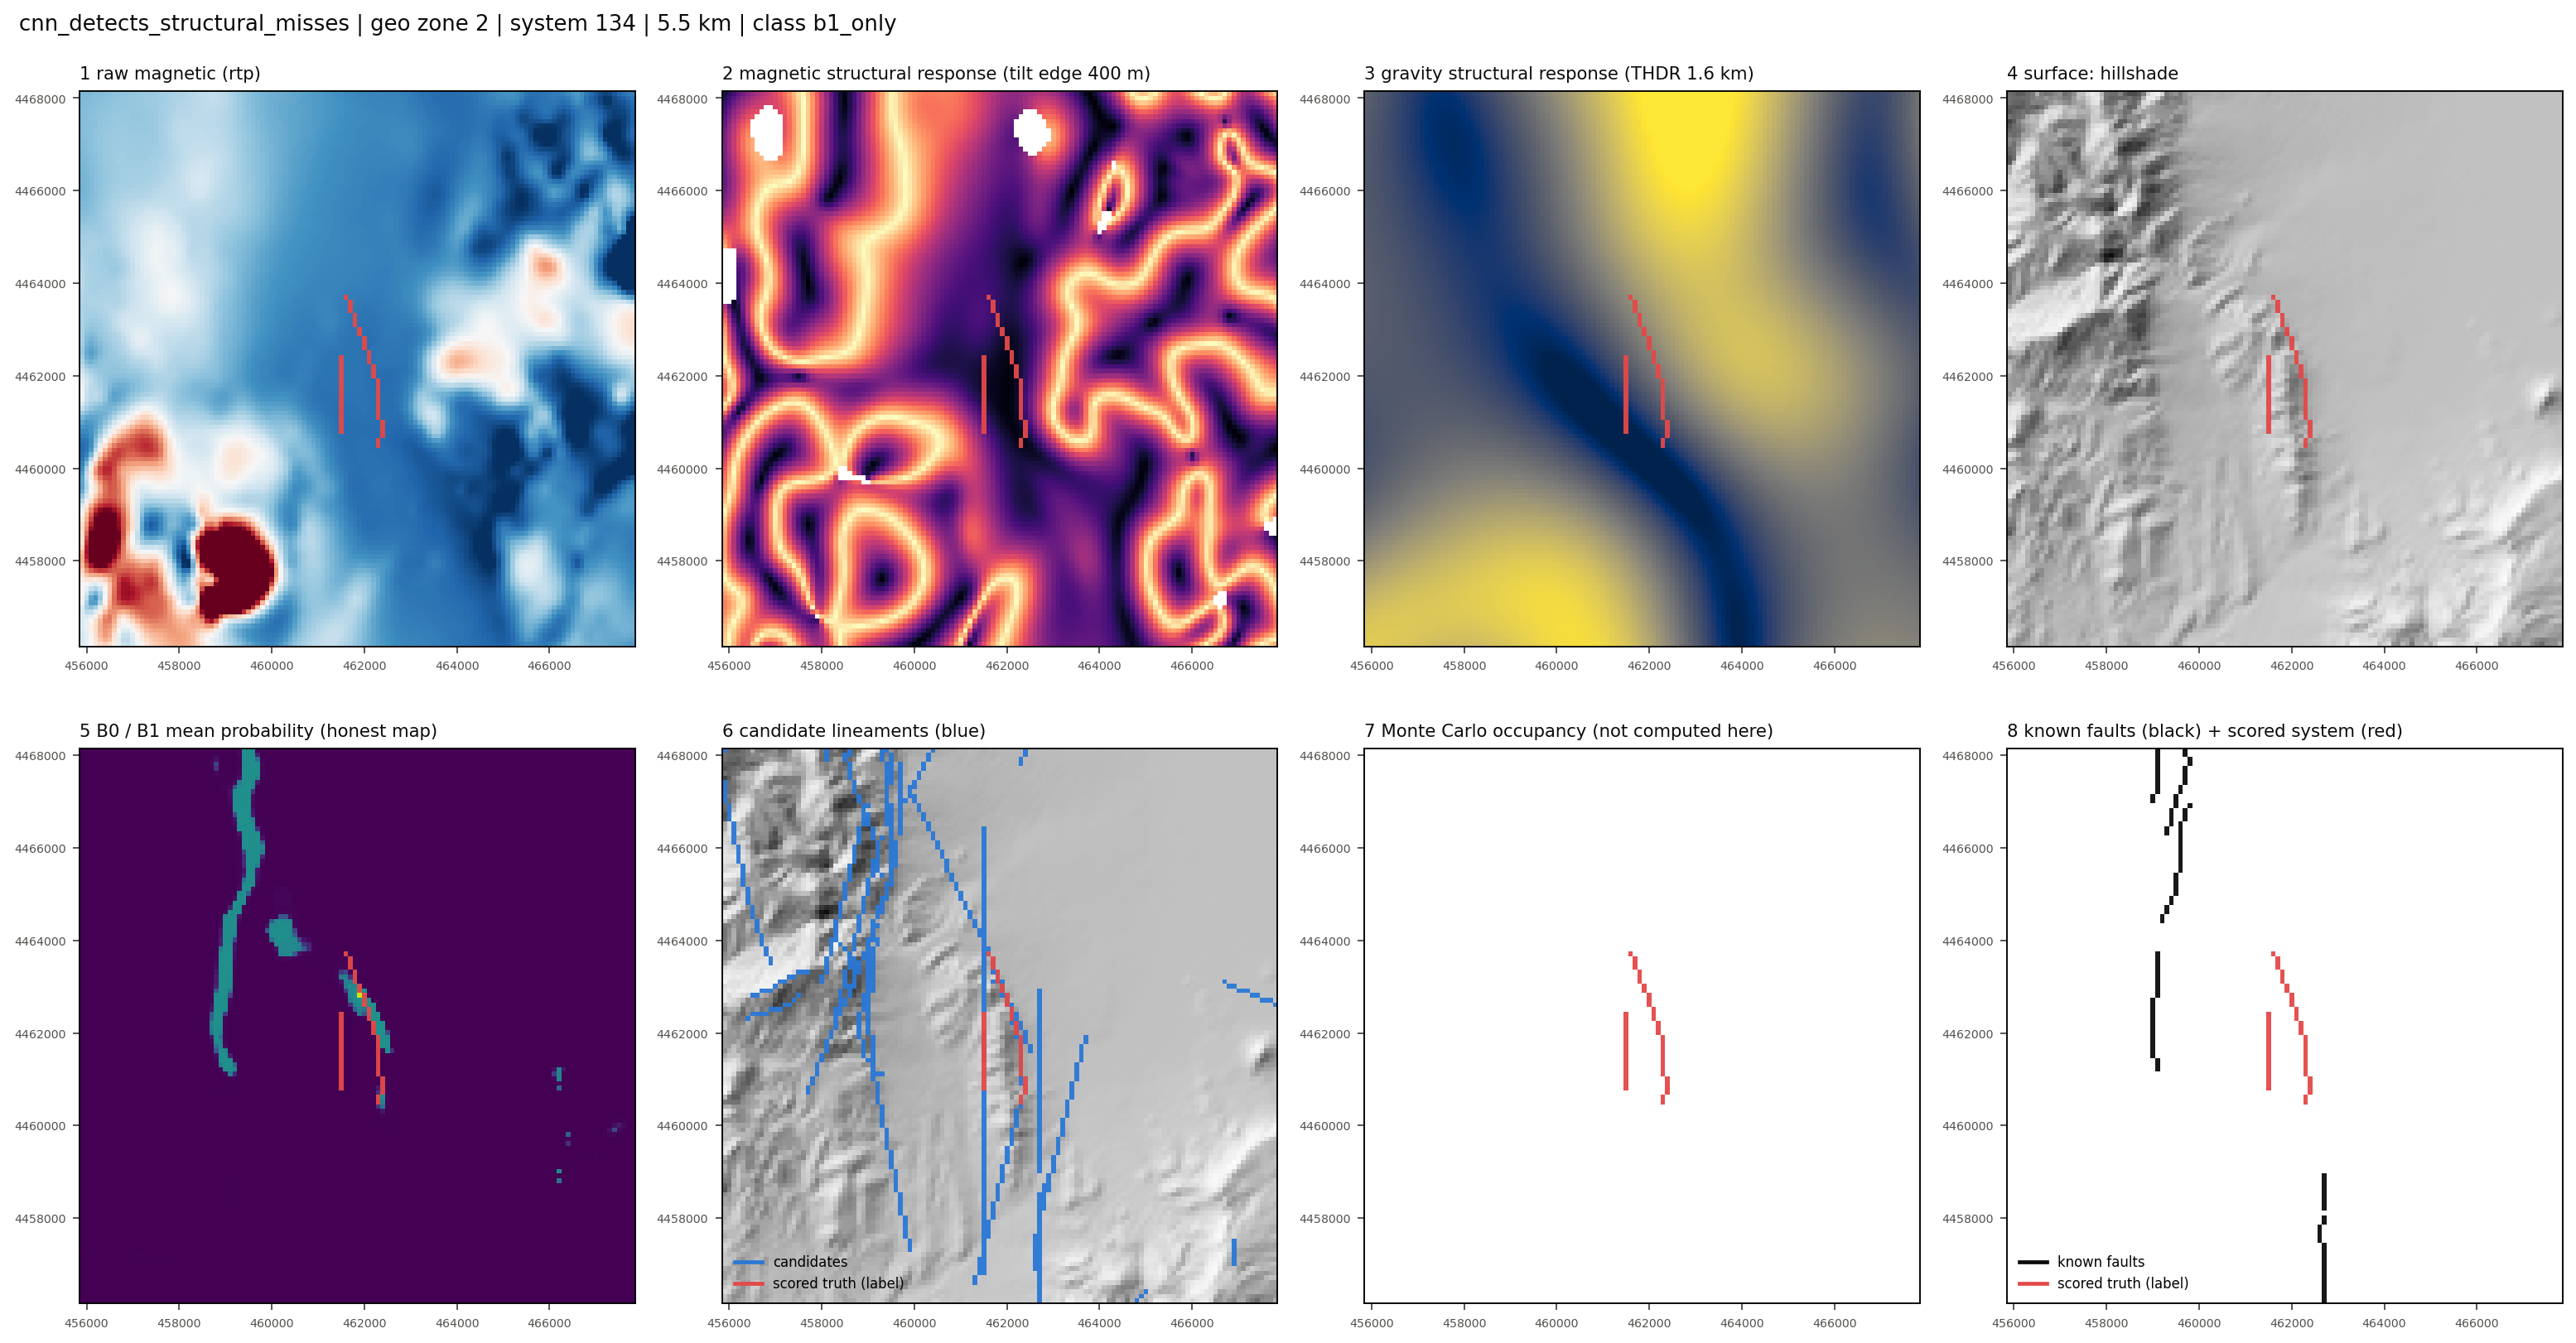

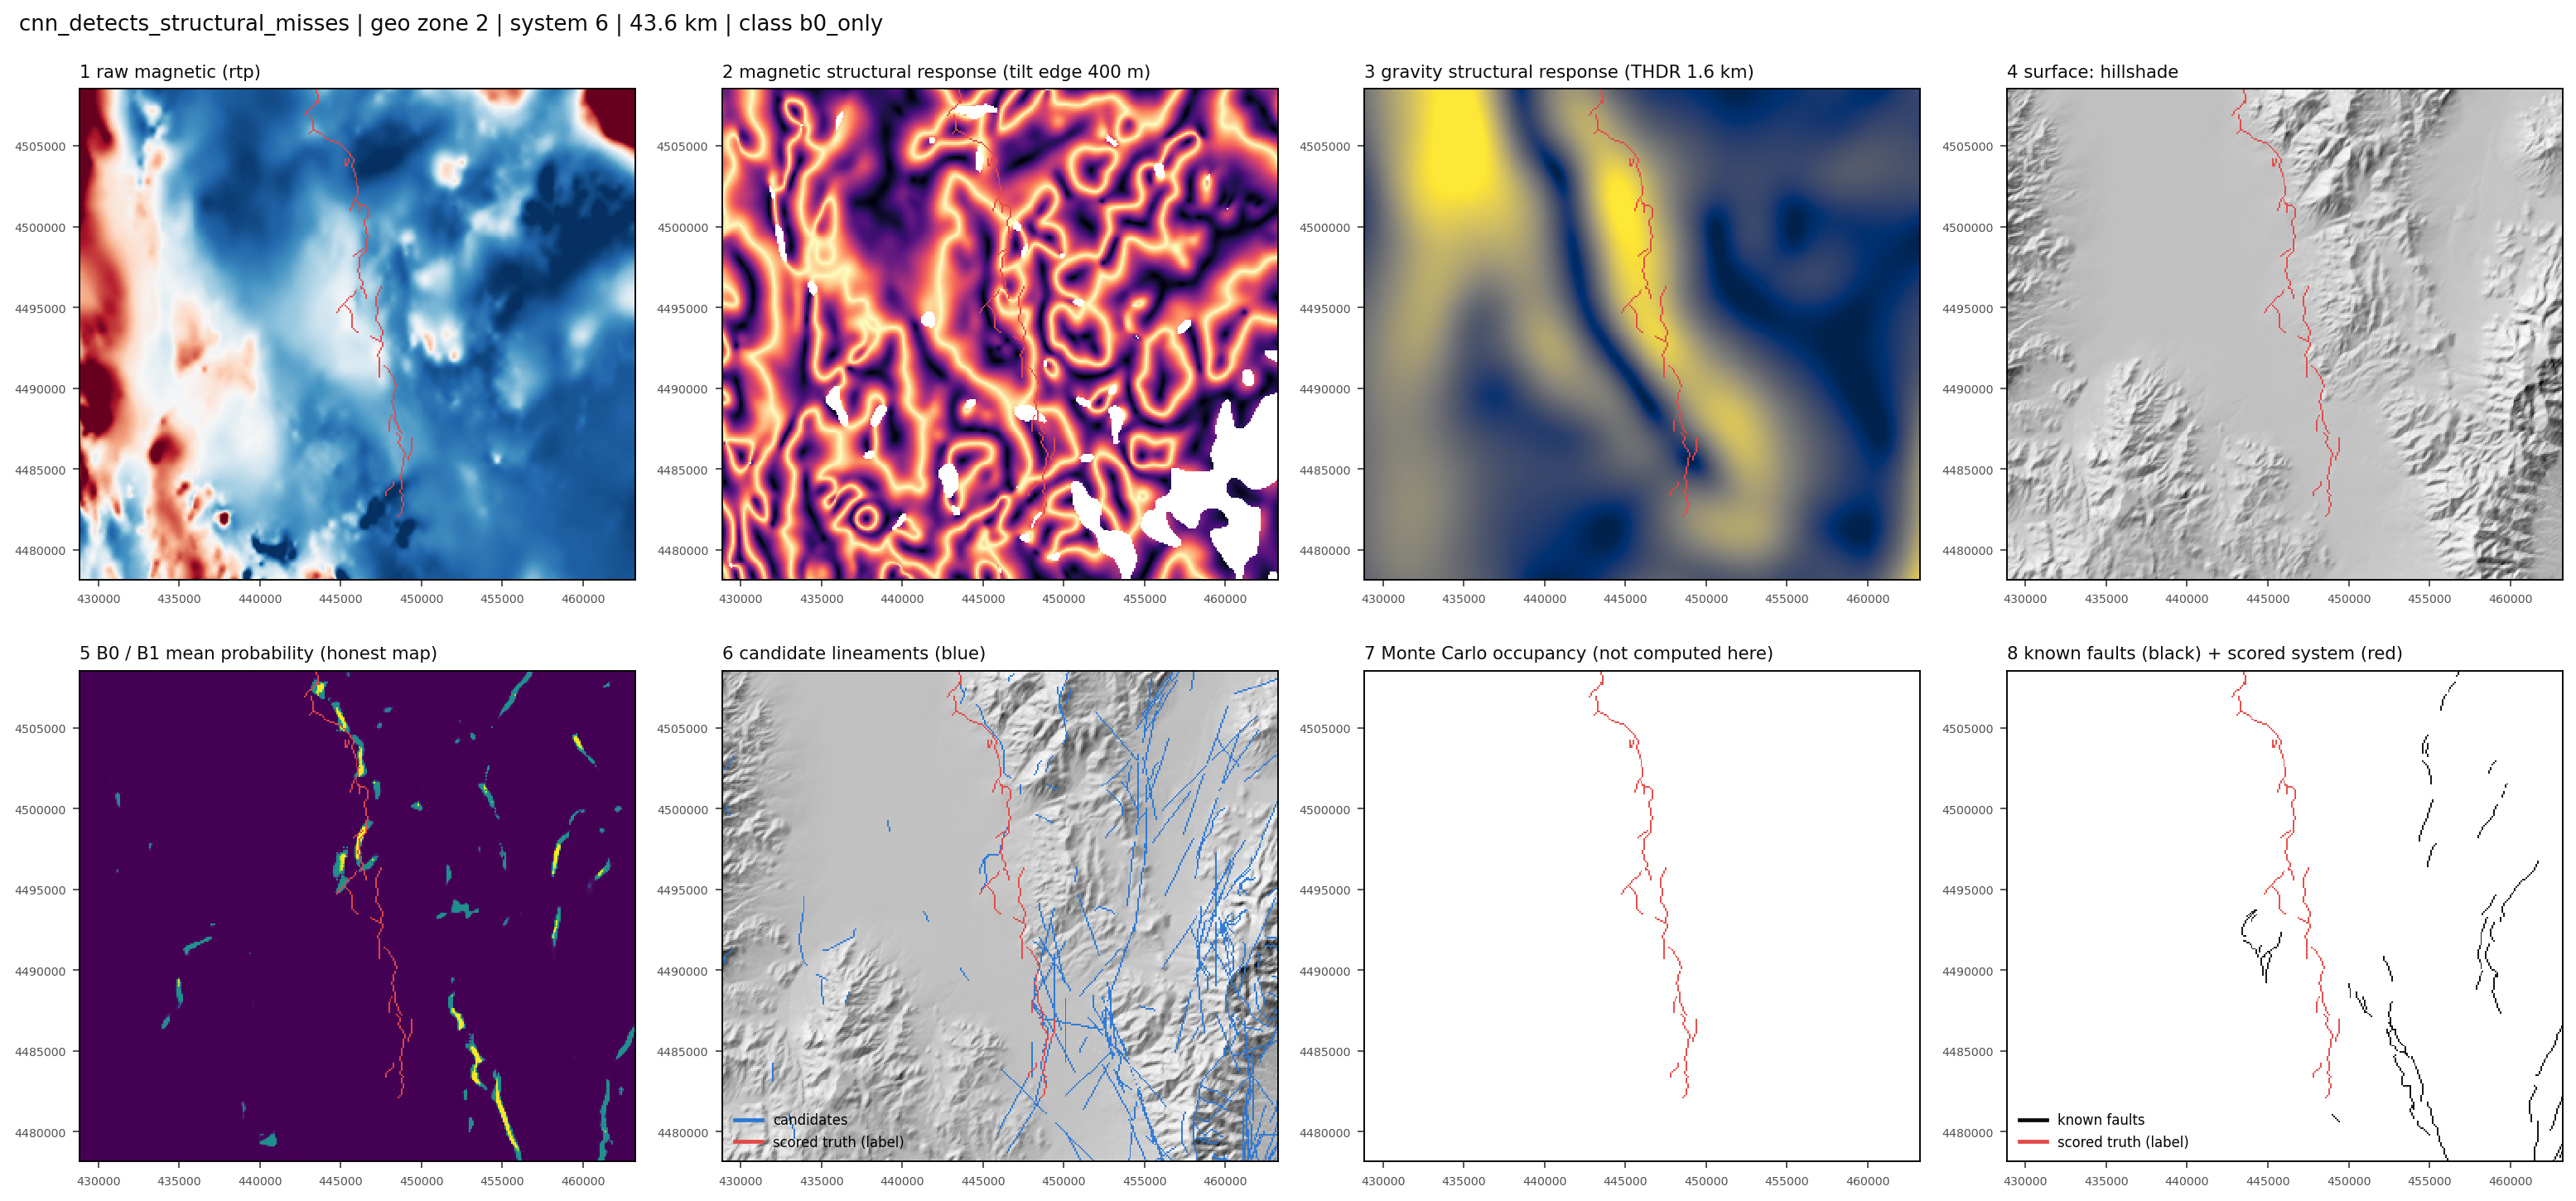

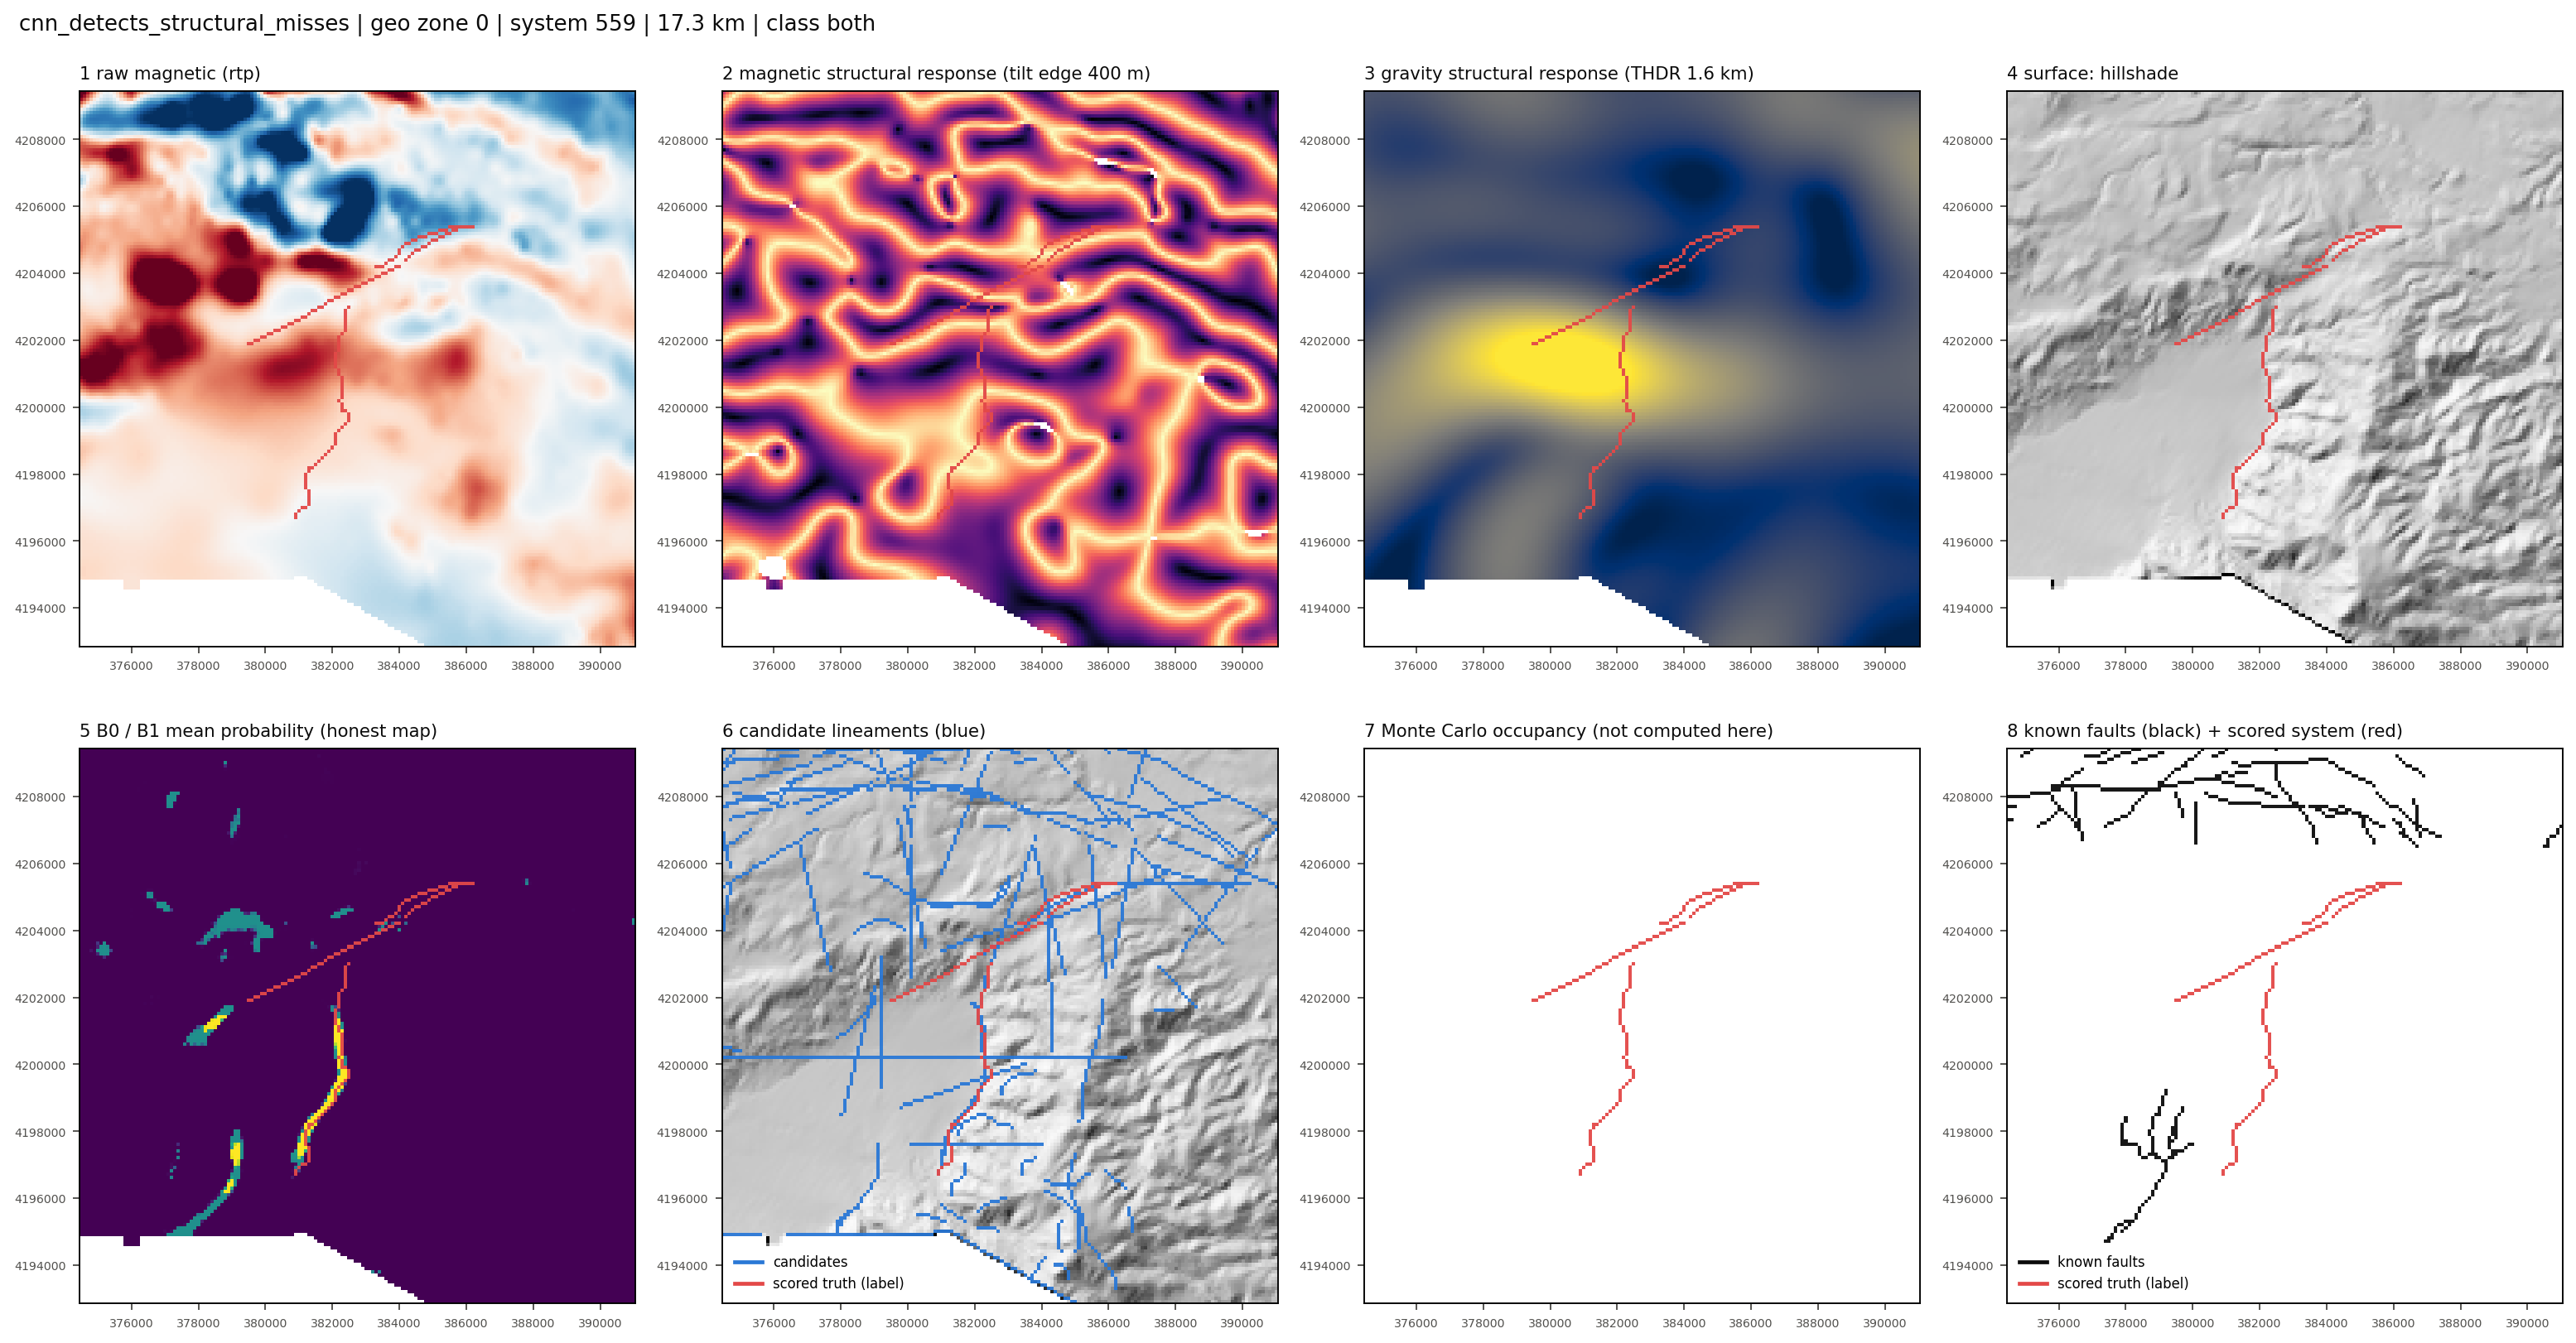

In [9]:
if m8.enabled('s02_signal_recovery'):
    s02 = m8.s02_signal_recovery()
    sub = 'signal_recovery'
    tab('summary', sub)
    r = m8.ws.load_table('reasons', sub)
    if len(r):
        display(r.groupby(['task', 'failure_reason']).size().rename('n_systems').reset_index()
                .sort_values('n_systems', ascending=False).head(20))
    st = m8.ws.load_table('stage_recall', sub)
    if len(st):
        display(st[(st.stratum == 'all')].pivot_table(index=['task', 'modality'], columns='stage', values='system_recall'))
    tab('missed_by_both_by_stage', sub, 40)
    show(['stage_funnel'], sub)
    idx = tab('case_study_index', f'{sub}/case_studies', 16)
    for f in idx.figure.head(8) if len(idx) else []:
        show([f[:-4]], f'{sub}/case_studies')

## 03. Physics-guided potential-field features

**Research question.** Which balanced potential-field operators expose fault-related edges that plain gradients bury under strong regional sources?

**Geological rationale.** Total horizontal gradient peaks over steep contacts but is dominated by strong, shallow sources. Tilt, TDX and theta normalise by the vertical derivative / analytic signal so weak and strong edges have comparable amplitude; local contrast normalisation does the same spatially. Analytic signal is depth- but not magnetisation-direction-sensitive. Gravity resolution (~2 km) limits its useful scales.

**Hypothesis.** Balanced operators (tilt edge, TDX, LCN) put crests on low-contrast faults that THDR misses, especially in quiet basins.

**Method.** Competing definitions at 100–3200 m (skipped below half the configured effective resolution): THDR, analytic signal, tilt edge, TDX, theta, LCN, and *_band variants from `tmi_hg / tmi_vg`, `iso_grav_anom_hg / _vg` only when the derivative audit marks them verified / consistent. Singularities: tilt / TDX / theta undefined where the analytic signal is below a low quantile; denominators floored; nodata never propagates.

**Planned diagnostic.** `band_provenance.csv` (VERIFIED_METADATA / CONSISTENT_EMPIRICAL / PROVISIONAL), `effective_resolution.csv` (configured vs spectral), `operator_inventory.csv` (allowed / refused + reason + units), selected GeoTIFFs.

**Success / failure criterion.** Layers are label-free inputs; their value is judged in sections 06 (coverage) and 11 (ranking ablations).

**How to read the outcome.** PROVISIONAL derivative bands are simply not used inside physical formulas. A spectral resolution much coarser than configured means the smallest scales add noise, not information.

In [10]:
if m8.enabled('s03_potential_fields'):
    s03 = m8.s03_potential_fields()
    sub = 'geophysical_features'
    tab('band_provenance', sub)
    tab('effective_resolution', sub)
    op = m8.ws.load_table('operator_inventory', sub)
    if len(op):
        display(op.groupby(['family', 'operator', 'allowed', 'reason']).size().rename('n_scales').reset_index())
    tab('saved_layers', sub)

[m8] s03_potential_fields: computed in 59s -> /content/gems_work/outputs/m8_physics_probabilistic
[sync out] 21 copied (100.5 MiB), 251 unchanged, 2s: ['outputs/m8_physics_probabilistic']


,family,band,role,parent,compared_with,spearman,best_sigma_px,scale_factor_band_over_computed,status,verified_note,description,units,combinable_family
0,magnetic,tmi_hg,hgrad,tmi,thdr,0.998701,0.7,0.203564,CONSISTENT_EMPIRICAL,NaN,Total magnetic intensity horizontal gradient -...,unknown (not verified),False
1,magnetic,tmi_vg,vgrad,tmi,vdr,0.994258,0.7,0.001023,CONSISTENT_EMPIRICAL,NaN,Total magnetic intensity vertical gradient - r...,unknown (not verified),False
2,gravity,iso_grav_anom_hg,hgrad,iso_grav_anom,thdr,0.002873,0.7,0.633089,PROVISIONAL,NaN,Isostatic gravity anomaly horizontal gradient ...,unknown (not verified),False
3,gravity,iso_grav_anom_vg,vgrad,iso_grav_anom,vdr,-0.148021,0.7,0.568313,PROVISIONAL,NaN,Isostatic gravity anomaly vertical gradient - ...,unknown (not verified),False
4,gravity,iso_grav_anom_slope,slope,iso_grav_anom,thdr,0.976506,2.0,0.056172,CONSISTENT_EMPIRICAL,NaN,Isostatic gravity anomaly slope - gradient of ...,unknown (not verified),False
5,terrain,det_elev_slope,slope,det_elev,thdr,0.971806,0.7,0.066106,CONSISTENT_EMPIRICAL,NaN,Detrended elevation slope - gradient of elevat...,unknown (not verified),False


,family,band,configured_m,effective_resolution_m,noise_floor,k_max_cycles_per_km,note,scales_used_m
0,magnetic,rtp,400.0,110.198459,2.721248e+07,4.537269,half-wavelength at the last wavenumber above s...,200;400;800;1600;3200
1,gravity,iso_grav_anom,2000.0,102.232306,2.927959e+04,4.890822,half-wavelength at the last wavenumber above s...,1600;3200
2,terrain,det_elev,100.0,143.818328,5.603887e+07,3.476608,half-wavelength at the last wavenumber above s...,100;200;400;800;1600;3200
3,conductivity,cond_surf,1000.0,89.318751,2.309208e+02,5.597929,half-wavelength at the last wavenumber above s...,800;1600;3200
4,basement,depth_to_base_surf,2000.0,99.826840,2.091142e+08,5.008673,half-wavelength at the last wavenumber above s...,1600;3200


,family,operator,allowed,reason,n_scales
0,basement,thdr,True,ok,2
1,conductivity,lcn,True,ok,3
2,conductivity,thdr,True,ok,3
3,gravity,analytic_signal,True,ok,2
4,gravity,lcn,True,ok,2
5,gravity,tdx,True,ok,2
6,gravity,thdr,True,ok,2
7,gravity,tilt_edge,True,ok,2
8,gravity,tilt_edge_band,False,tilt_edge_band: iso_grav_anom_hg/iso_grav_anom...,2
9,magnetic,analytic_signal,True,ok,5


,layer,status,defined_share_valid,p50,p99
0,magnetic:tilt_edge@400,ok,0.98,0.538098,0.990392
1,magnetic:tdx@400,ok,0.98,0.538098,0.990392
2,magnetic:analytic_signal@400,ok,1.00,77.004959,669.683472
3,magnetic:lcn@200,ok,1.00,0.572182,2.470052
4,gravity:thdr@1600,ok,1.00,1.434689,4.813863
5,gravity:tilt_edge@1600,ok,0.98,0.539556,0.990392
6,terrain:thdr@200,ok,1.00,50.414593,368.473450


## 03b. Multiscale geological worms

**Research question.** Do edges that persist through scale-space (upward continuation) recover faults that a fixed-scale lineament extractor misses?

**Geological rationale.** Upward continuation is the physical scale-space of a potential field: deeper sources dominate at greater heights. A worm that persists marks a source edge with depth extent (fault-like); its lateral migration with height indicates dip. Terrain uses Gaussian scale-space.

**Hypothesis.** Persistent worms are rarer than single-scale crests but cover a larger share of withheld systems per kilometre.

**Method.** Per level: THDR, NMS, local-percentile threshold (20 km blocks), coherence gate; base worm pixels linked to each coarser level within a tolerance and strike difference. Statistics: persistence, consecutive run, orientation stability, ridge stability, scale of maximum support, migration, continuity.

**Planned diagnostic.** `worm_summary.csv`, `worms_<family>.tif`, `coverage_vs_fixed_scale.csv` (evaluation: persistent worms vs all base-level crests, with densities).

**Success / failure criterion.** Worms are worth keeping when persistent worms reach comparable system recall at clearly lower density than base crests; final value is measured in section 06 / 11.

**How to read the outcome.** Similar recall at lower density = persistence is a useful *feature*; much lower recall = faults here are shallow / single-scale and persistence must not be a filter (M8 keeps it a feature).

[m8] s03b_structural_worms: computed in 211s -> /content/gems_work/outputs/m8_physics_probabilistic
[sync out] 15 copied (7.9 MiB), 271 unchanged, 0s: ['outputs/m8_physics_probabilistic']


,family,worm_px,share_persistent,median_orient_stability,median_scale_max_m,levels_used
0,magnetic,65799,0.754768,0.996024,200.0,200;400;800;1600;3200
1,gravity,11421,0.784958,0.999309,1600.0,1600;3200
2,terrain,136746,0.475231,1.000000,100.0,100;200;400;800;1600;3200


,family,task,zone,n_systems,recall_persistent_worms,recall_all_base_worms,worm_px_per_100km2,base_px_per_100km2
0,magnetic,disc_official,0,38,0.000000,0.000000,92.460822,123.865889
1,magnetic,disc_official,1,38,0.000000,0.000000,97.690043,127.269649
2,magnetic,disc_official,2,44,0.000000,0.000000,103.361795,136.406959
3,gravity,disc_official,0,38,0.000000,0.000000,17.885699,22.526676
4,gravity,disc_official,1,38,0.000000,0.000000,16.755827,22.342906
5,gravity,disc_official,2,44,0.000000,0.000000,18.713998,24.499801
6,terrain,disc_official,0,38,0.026316,0.052632,121.281963,250.926654
7,terrain,disc_official,1,38,0.000000,0.026316,141.840404,294.790063
8,terrain,disc_official,2,44,0.000000,0.022727,128.870342,271.671830


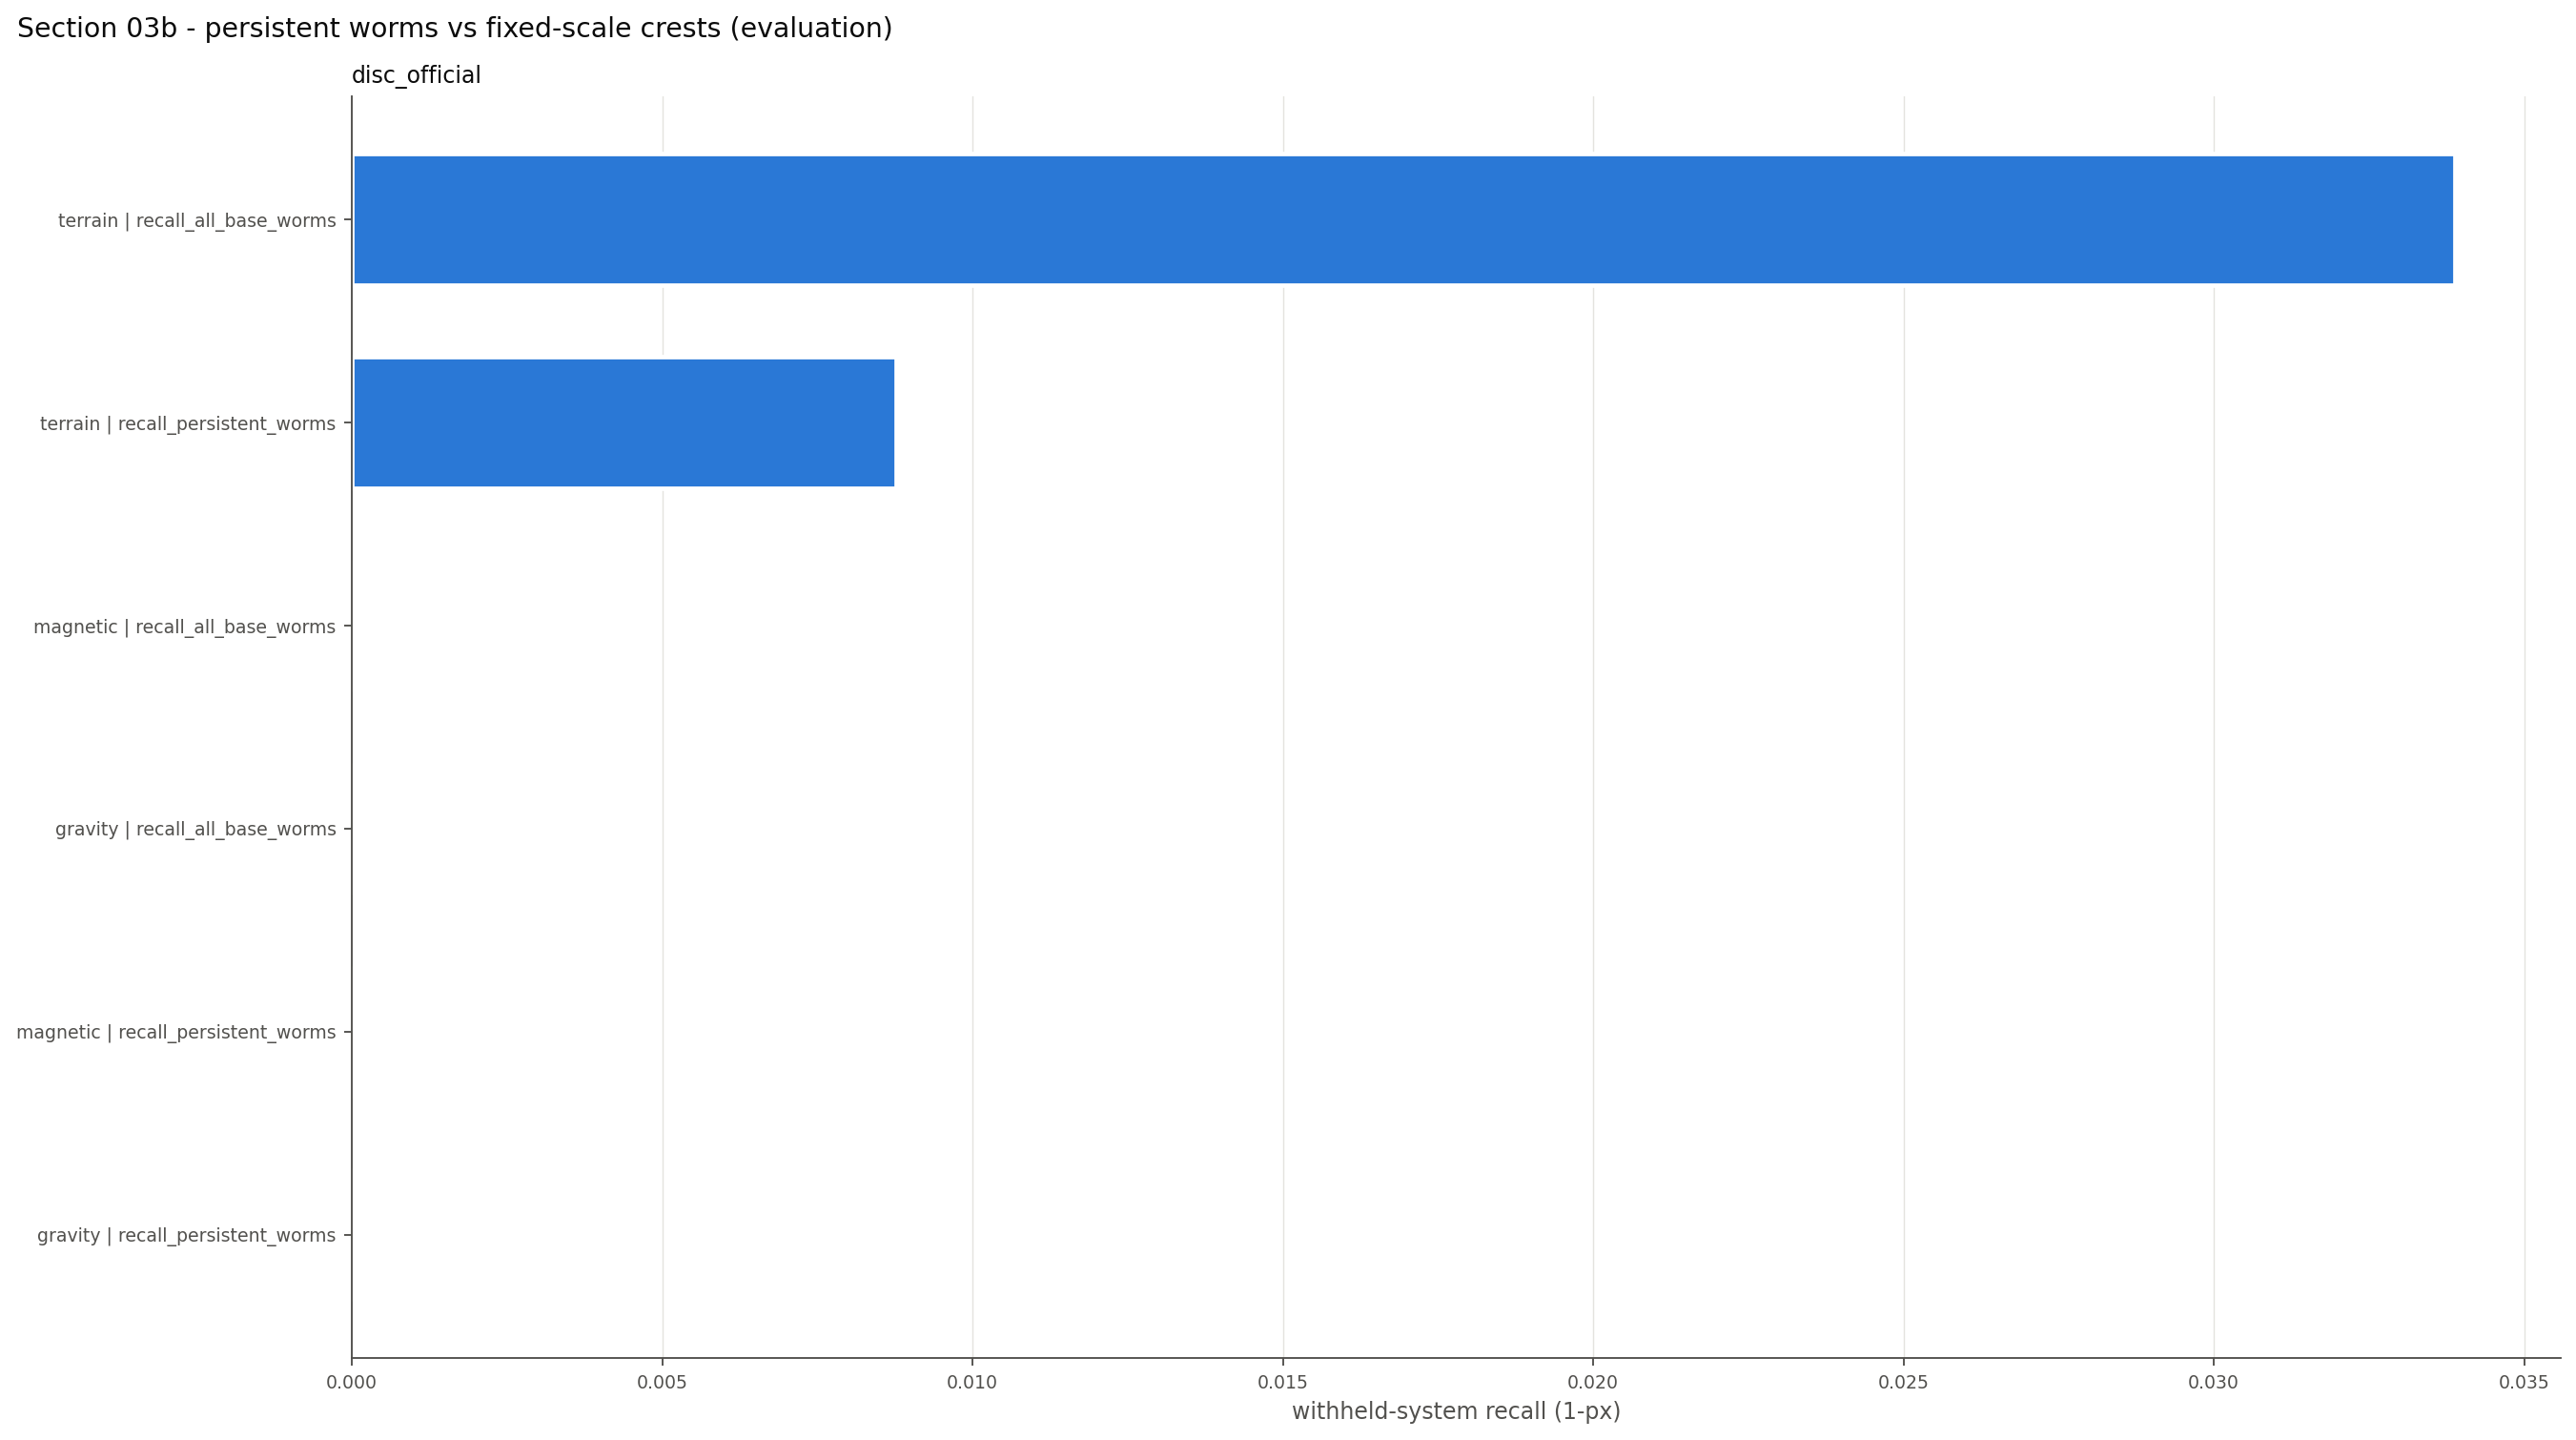

In [11]:
if m8.enabled('s03b_structural_worms'):
    s03b = m8.s03b_structural_worms()
    sub = 'geophysical_features/structural_worms'
    tab('worm_summary', sub)
    tab('coverage_vs_fixed_scale', sub)
    show(['worms_vs_fixed_scale'], sub)

## 04. Multimodal structural reasoning

**Research question.** Where do magnetic and gravity edges agree within a physically justified tolerance, and which structures are surface-expressed versus potentially buried?

**Geological rationale.** A fault juxtaposing different rocks produces both edges, but their maxima need not coincide (different source depths, dip, gravity resolution). Terrain lineaments may be faults, erosional or depositional features: never confirmations by themselves. Strain-rate and seismicity are regional descriptors; a scalar strain magnitude gives no fault orientation, and low seismicity never rejects a fault.

**Hypothesis.** Tolerant agreement (≤ 800 m) captures many more shared boundaries than exact coincidence, and agreeing edges are enriched in mapped faults.

**Method.** Nearest-worm matching with distance and strike tolerances in both directions; crest classes (magnetic only / gravity only / agreeing / discordant); surface–subsurface classes; regional percentiles of context bands.

**Planned diagnostic.** `mag_grav_agreement.csv` (agreement share, offsets, discordance by tolerance), `surface_subsurface.csv`, `classes_by_region.csv`, rasters.

**Success / failure criterion.** Label-free layers; their value is judged by the coverage of the `xmod_agree` family (06) and the agreement features (11).

**How to read the outcome.** A large discordant share near agreeing crests suggests contacts of different geometry, not one fault; strongly region-dependent agreement argues for region-aware budgets.

In [12]:
if m8.enabled('s04_multimodal'):
    s04 = m8.s04_multimodal()
    sub = 'geophysical_features/multimodal'
    tab('mag_grav_agreement', sub)
    tab('surface_subsurface', sub)
    tab('classes_by_region', sub, 40)
    tab('context_layers', 'geophysical_features/context')

[m8] s04_multimodal: computed in 252s -> /content/gems_work/outputs/m8_physics_probabilistic
[sync out] 14 copied (77.6 MiB), 285 unchanged, 1s: ['outputs/m8_physics_probabilistic']


,tolerance_m,from,crest_px,agree_share,median_offset_m_agreeing,discordant_near_share
0,300.0,magnetic,65799,0.002751,141.421356,0.006246
1,300.0,gravity,11421,0.016986,200.000000,0.038701
2,800.0,magnetic,65799,0.007584,412.310563,0.018587
3,800.0,gravity,11421,0.044655,400.000000,0.104019


,class,crest_px,crest_km
0,surface_expressed,29607,2960.7
1,potentially_buried,67581,6758.1
2,terrain_only,112289,11228.9


,layer,region,code,px
0,class:mag_grav,NW,1,14247
1,class:mag_grav,NW,2,2079
2,class:mag_grav,NW,3,352
3,class:mag_grav,NW,4,864
4,class:mag_grav,NC,1,11766
5,class:mag_grav,NC,2,2334
6,class:mag_grav,NC,3,267
7,class:mag_grav,NC,4,324
8,class:mag_grav,NE,1,9742
9,class:mag_grav,NE,2,1455


,band,status,sigma_km,note
0,geod_2ndinv,ok,10.0,regional percentile: structural-domain descrip...
1,geod_shearrate,ok,10.0,regional percentile: structural-domain descrip...
2,geod_dilaterate,ok,10.0,regional percentile: structural-domain descrip...
3,deq_n100a15,ok,10.0,regional percentile: structural-domain descrip...
4,ieq_n100a15,ok,10.0,regional percentile: structural-domain descrip...
5,cond_surf,ok,10.0,regional percentile: structural-domain descrip...
6,depth_to_base_surf,ok,10.0,regional percentile: structural-domain descrip...


## 05. Fault-normal geophysical profiles

**Research question.** Do candidate traces carry a consistent, localised step across their strike — like mapped faults — or only a broad gradient?

**Geological rationale.** A fault juxtaposing contrasting units gives a step whose sign stays constant along strike and which is localised on the trace; a lithological contact or regional gradient gives broad, sign-variable or diffuse transitions.

**Hypothesis.** Mapped faults show higher sign consistency, continuity and localisation than random controls; unlabelled geophysical boundaries are intermediate (some are unmapped faults).

**Method.** Smoothed curved paths, stations every 2 px, consistently oriented normals, bilinear samples at ±100…1200 m on magnetic, gravity, conductivity, terrain and basement fields; samples outside the unit's evaluation zone or near nodata are dropped (no transect crosses a fold / split boundary).

**Planned diagnostic.** Per-candidate summaries (`fault_normal_profiles/units/*`), raw transects for a capped number of candidates, gallery `gallery_profiles.csv` + `gallery_contrast_vs_offset.png` for mapped faults / unlabelled boundaries / random controls / candidates.

**Success / failure criterion.** Profile features enter section 11; the gallery is descriptive.

**How to read the outcome.** Unlabelled boundaries are **not** negatives. If mapped faults and controls look alike, profile contrasts will not help ranking at 100 m.

*Order note:* before section 06 has run, profiles describe the M7 pool; section 06 re-runs this section on the M8 pool automatically.

/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)


[m8] s05 geo:0: 1499 candidates profiled (m7 pool)


/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)


[m8] s05 geo:1: 1735 candidates profiled (m7 pool)


/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)


...

/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)


[m8] s05 disc_official:2: 3449 candidates profiled (m7 pool)


/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)
/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)
/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)
/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)
/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)
/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)
/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)
/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)


[m8] s05_fault_normal_profiles: computed in 2766s -> /content/gems_work/outputs/m8_physics_probabilistic
[sync out] 24 copied (64.2 MiB), 298 unchanged, 1s: ['outputs/m8_physics_probabilistic']
pool profiled per unit: {'geo:0': 'm7', 'geo:1': 'm7', 'geo:2': 'm7', 'disc_official:0': 'm7', 'disc_official:1': 'm7', 'disc_official:2': 'm7'}


,group,field,offset_m,mean,q25,q75,n
0,candidate,basement,100.0,0.035414,0.008036,0.039228,178
1,candidate,basement,200.0,0.070673,0.016075,0.078126,178
2,candidate,basement,300.0,0.105925,0.024132,0.118150,178
3,candidate,basement,500.0,0.175954,0.040147,0.199630,177
4,candidate,basement,800.0,0.282596,0.062963,0.325516,174
5,candidate,basement,1200.0,0.397748,0.088547,0.487394,167
6,candidate,conductivity,100.0,0.007313,0.000000,0.000000,178
7,candidate,conductivity,200.0,0.014161,0.000000,0.001159,178
8,candidate,conductivity,300.0,0.022142,0.000000,0.004208,178
9,candidate,conductivity,500.0,0.041290,0.000000,0.036711,177


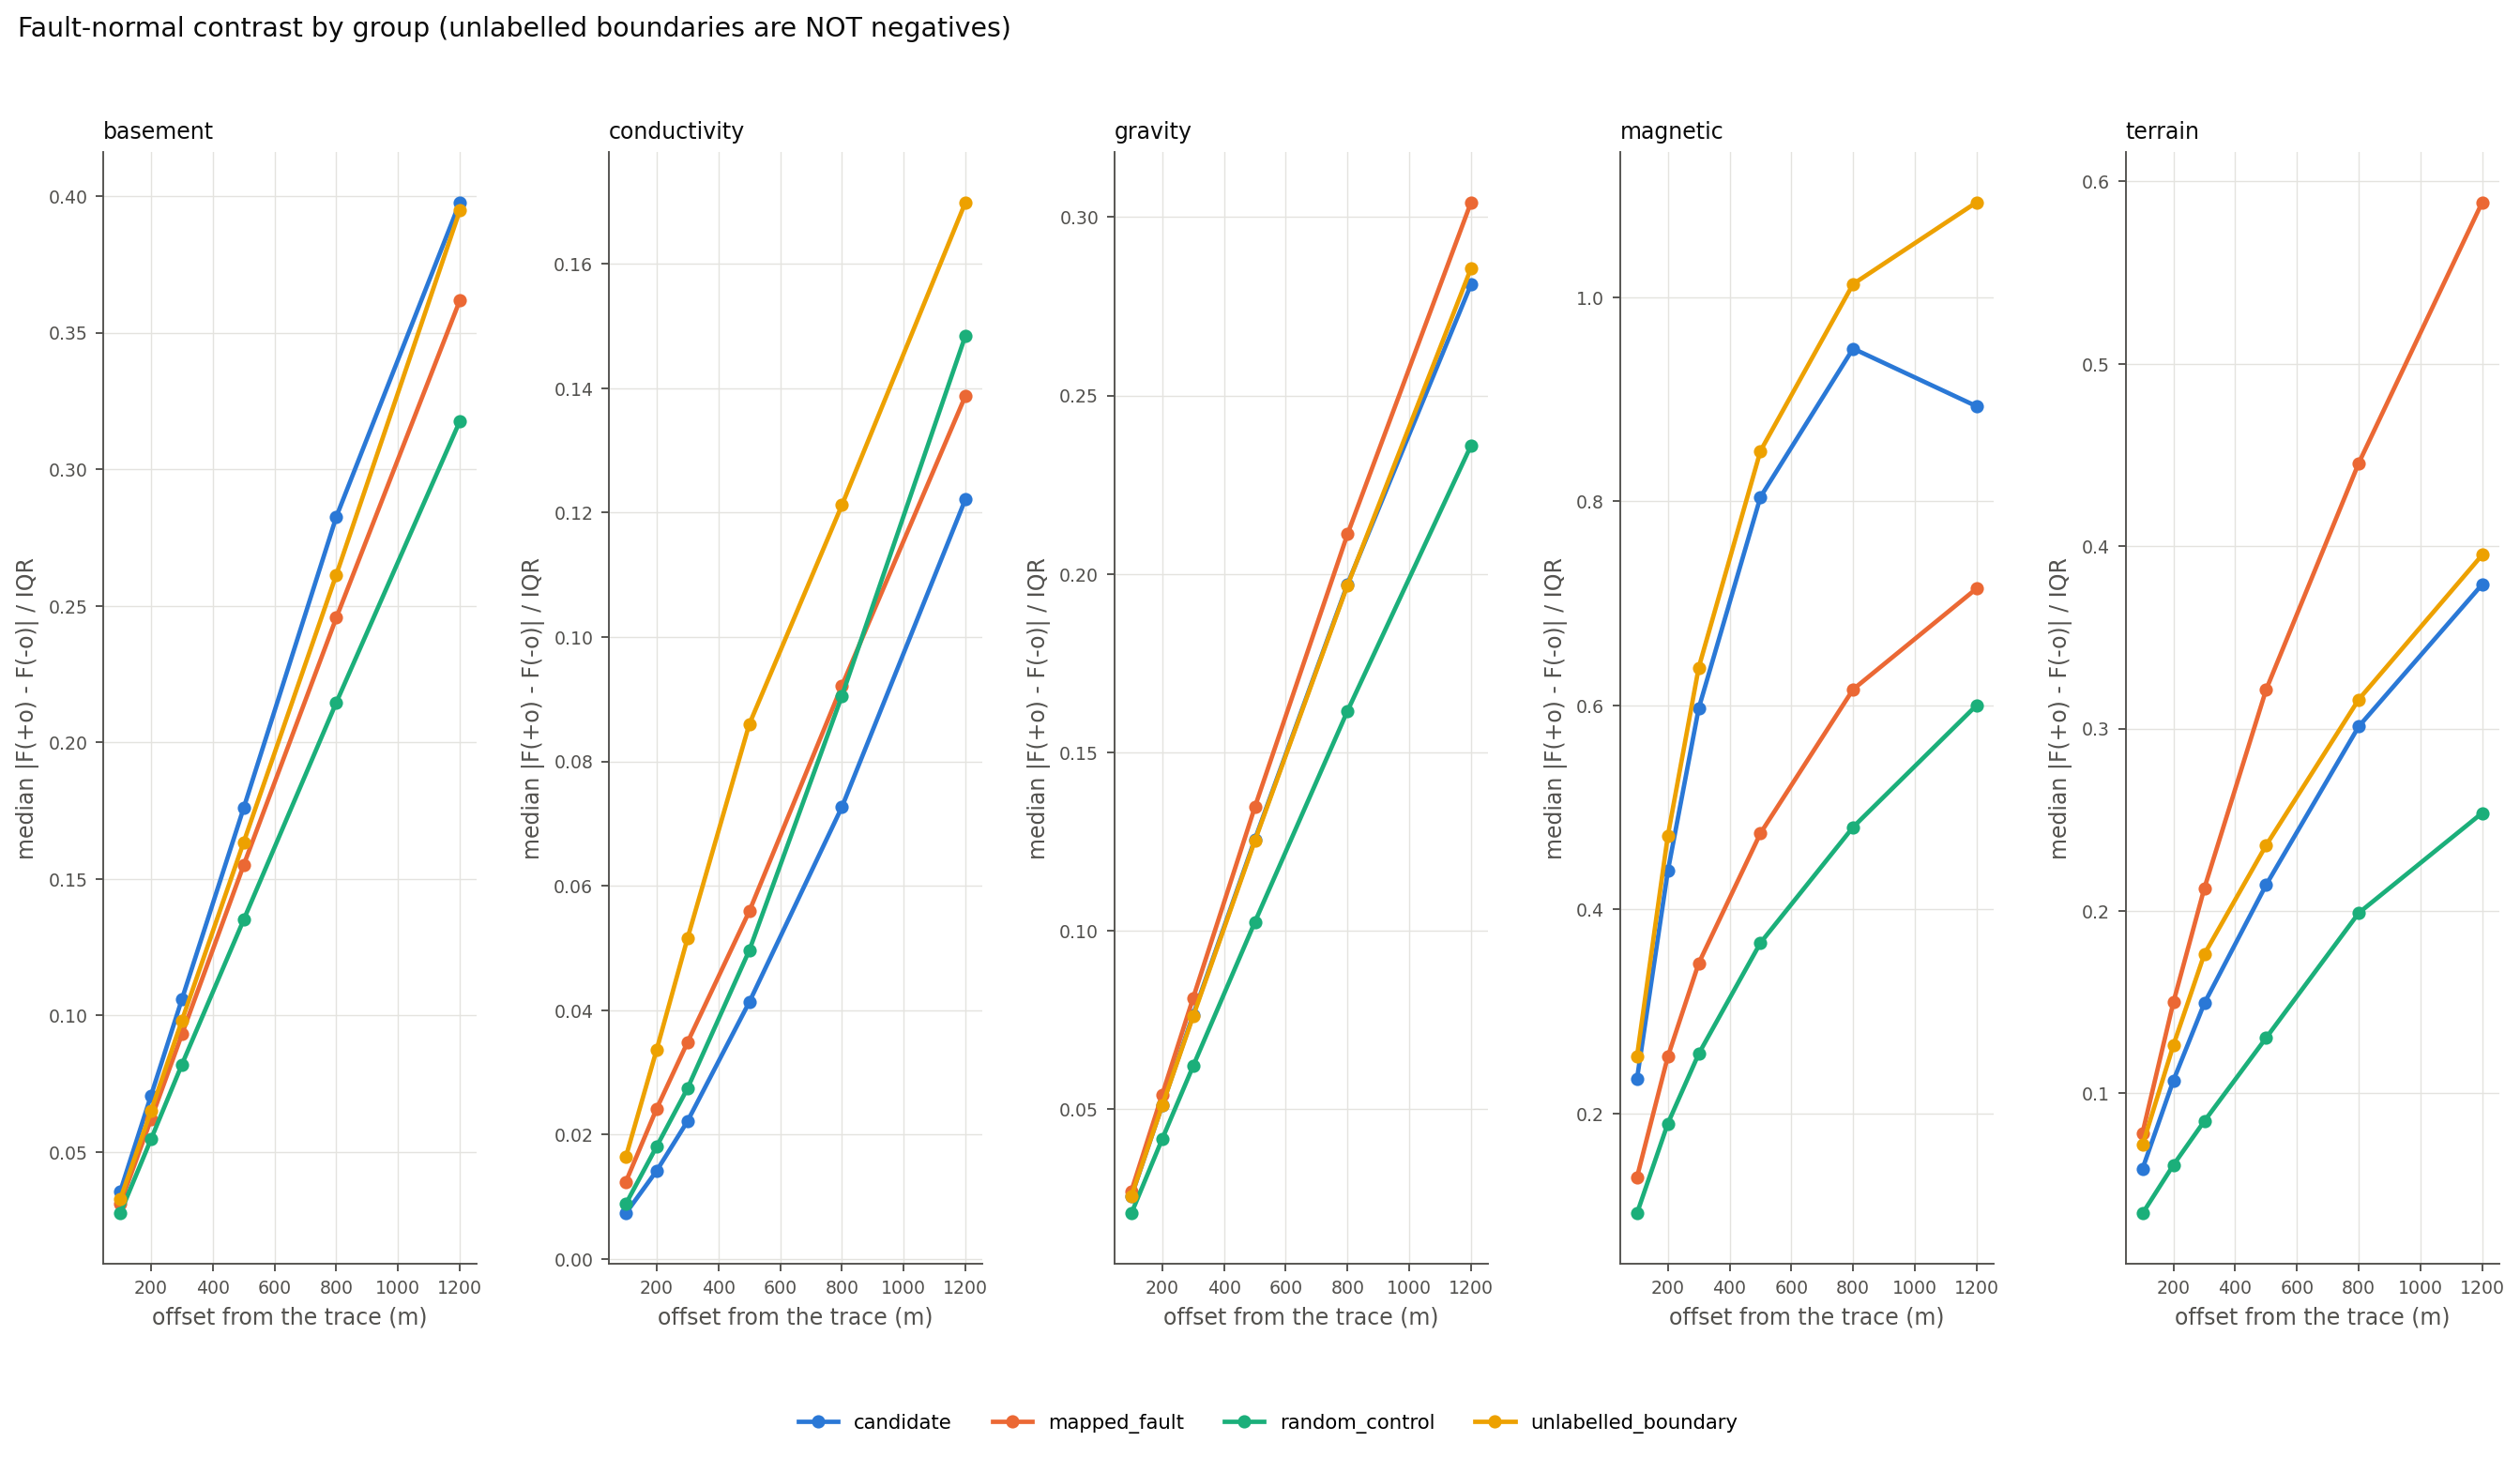

In [13]:
if m8.enabled('s05_fault_normal_profiles'):
    s05 = m8.s05_fault_normal_profiles()
    if s05 and 'pool_source' in s05:
        print('pool profiled per unit:', s05['pool_source'])
    tab('gallery_profiles', 'fault_normal_profiles/gallery', 40)
    show(['gallery_contrast_vs_offset'], 'fault_normal_profiles/gallery')

## 06. High-recall candidate generation — mandatory oracle gate (Gates 1 and 2)

**Research question.** Does a union of physics, terrain, cross-modal, CNN, CNN-disagreement, network-continuation and DEM families cover substantially more withheld systems than the M7 pool at the same candidate density?

**Geological rationale.** Faults express themselves through different modalities in different settings; requiring every modality would discard most of them. Recall comes from unions; specificity from ranking on modality agreement.

**Hypothesis.** Local thresholds, preserved short fragments, balanced operators and worms raise system recall at matched density, including systems missed by both CNNs.

**Method.** Label-free families on the full grid (cached), per-unit honest CNN / disagreement crests, known-tip extensions, section-08 completion hypotheses and DEM crests; multiple linking distances / curvature limits; union → deduplication with provenance (`sources`, `families`, `member_uids`). Oracle (reads truth): coverage at label-free density caps, regional density budget, kd subsets, recall by family, missed-by-both coverage, unique coverage of the lowest-confidence tercile, and the M7 pool at the same densities.

**Planned diagnostic.** `oracle/gate2.csv`, `pooled_curve.csv` (M8 vs M7), `pooled_groups.csv`, `incremental.csv`, `low_conf.csv`, `recall_density_m8_vs_m7.png`, `signal_recovery/gate1.csv`.

**Success / failure criterion.** Gate 2 GO: system recall at the gate density ≥ 0.30 AND (gain over M7 at the same density ≥ 0.05 OR missed-by-both coverage ≥ 0.10). Gate 1 PASS: ≥ 3 systems (≥ 5 %) covered by M8 physics and not by M7 linked candidates. On NO_GO, sections 10–13 refuse to run.

**How to read the outcome.** Oracle values are upper bounds, never scores. If Gate 1 fails with mostly raw-absent systems, the limit is the data at 100 m; with mostly raw-present systems, extraction still loses them.

[m8] s08 disc_official:0: 2629 stochastic + 25187 deterministic hypotheses
[m8] s08 disc_official:1: 2357 stochastic + 22600 deterministic hypotheses
[m8] s08 disc_official:2: 2756 stochastic + 26485 deterministic hypotheses
[m8] s08a_completion_hypotheses: computed in 1580s -> /content/gems_work/outputs/m8_physics_probabilistic
[sync out] 18 copied (22.9 MiB), 321 unchanged, 1s: ['outputs/m8_physics_probabilistic']
[m8] s06 mag_thdr: 17440 paths
[m8] s06 mag_tilt: 28862 paths
[m8] s06 mag_tdx: 28862 paths
[m8] s06 grav_thdr: 1026 paths
[m8] s06 grav_tilt: 1641 paths
[m8] s06 terr_edge: 10796 paths
[m8] s06 terr_line: 7421 paths
[m8] s06 terr_slope: 10870 paths
[m8] s06 cond_edge: 950 paths
[m8] s06 xmod_agree: 435 paths
[m8] s06 worm_mag: 13403 paths
[m8] s06 worm_grav: 3886 paths
[sync in] 4 copied (30.7 MiB), 0 unchanged, 2s: ['outputs/m7_discovery_first/gems3_engine/predictions']
[sync in] 7 copied (48.7 MiB), 0 unchanged, 3s: ['reports/gems3/predictions']
[m8] s06 geo:0: 10039 fus

/content/GEMS/gems_bench/m8/signal_recovery.py:435: RuntimeWarning: All-NaN slice encountered
  "share": hit, "localization_m": float(np.nanmedian(np.asarray(dist)[i]))})
/content/GEMS/gems_bench/m8/signal_recovery.py:435: RuntimeWarning: All-NaN slice encountered
  "share": hit, "localization_m": float(np.nanmedian(np.asarray(dist)[i]))})
/content/GEMS/gems_bench/m8/signal_recovery.py:435: RuntimeWarning: All-NaN slice encountered
  "share": hit, "localization_m": float(np.nanmedian(np.asarray(dist)[i]))})
/content/GEMS/gems_bench/m8/signal_recovery.py:435: RuntimeWarning: All-NaN slice encountered
  "share": hit, "localization_m": float(np.nanmedian(np.asarray(dist)[i]))})
/content/GEMS/gems_bench/m8/signal_recovery.py:435: RuntimeWarning: All-NaN slice encountered
  "share": hit, "localization_m": float(np.nanmedian(np.asarray(dist)[i]))})
/content/GEMS/gems_bench/m8/signal_recovery.py:435: RuntimeWarning: All-NaN slice encountered
  "share": hit, "localization_m": float(np.nanmedia

[m8] s06_candidates: computed in 1819s -> /content/gems_work/outputs/m8_physics_probabilistic
[sync out] 63 copied (170.2 MiB), 338 unchanged, 2s: ['outputs/m8_physics_probabilistic']


,task,gate,density_km_per_100km2,system_recall_m8,system_recall_m7_same_density,gain_over_m7,missed_by_both_coverage,pass_system_recall,pass_gain,pass_missed,decision,rule,profile,provisional,note
0,disc_official,G2_candidate_coverage,80.0,0.166667,0.041667,0.125000,0.021505,False,True,False,NO_GO,recall >= 0.3 AND (gain >= 0.05 OR missed-by-b...,FULL,False,oracle numbers read the truth: diagnostic uppe...
1,geo,G2_candidate_coverage,80.0,0.212662,0.058442,0.154221,0.104218,False,True,True,NO_GO,recall >= 0.3 AND (gain >= 0.05 OR missed-by-b...,FULL,False,oracle numbers read the truth: diagnostic uppe...


,task,n_systems,m7_linked_systems,m8_physics_systems,additional_systems,additional_share,missed_raw_absent,missed_raw_present,decision,diagnosis,rule,profile,provisional
0,disc_official,120,120,31,0,0.0,0,0,FAIL,mostly information-limited at 100 m (raw respo...,additional >= 3 and share >= 0.05,FULL,False
1,geo,616,616,89,0,0.0,0,0,FAIL,mostly information-limited at 100 m (raw respo...,additional >= 3 and share >= 0.05,FULL,False


pool                             m7        m8
task          density_cap                    
disc_official 2.5          0.000000  0.008333
              5.0          0.008333  0.016667
              10.0         0.008333  0.025000
              20.0         0.016667  0.033333
              40.0         0.016667  0.075000
              80.0         0.041667  0.166667
              160.0        0.041667  0.400000
geo           2.5          0.011364  0.008117
              5.0          0.032468  0.016234
              10.0         0.047078  0.027597
              20.0         0.055195  0.055195
              40.0         0.058442  0.103896
              80.0         0.058442  0.212662
              160.0        0.058442  0.230519

,task,group,value,tp_w,fp_w,fn_w,n_truth,dti,recall_w,n_systems,n_short,recall_300m,system_recall,short_system_recall,density_km_per_100km2
2,disc_official,family,cnn_disagree,4123.715123,155783.966057,18206.284877,22330,0.082730,0.184672,120,0,0.305945,0.108333,0.000000,35.446511
0,disc_official,family,cnn_b0,3524.624903,57259.788262,18805.375097,22330,0.117406,0.157843,120,0,0.250701,0.075000,0.000000,15.665379
1,disc_official,family,cnn_b1,3304.442762,57454.595218,19025.557238,22330,0.110090,0.147982,120,0,0.232458,0.075000,0.000000,15.739531
14,disc_official,family,mag_tdx,3287.899938,222662.565578,19042.100062,22330,0.052144,0.147241,120,0,0.258316,0.050000,0.000000,49.720705
16,disc_official,family,mag_tilt,3307.647484,227794.217102,19022.352516,22330,0.051614,0.148126,120,0,0.259642,0.050000,0.000000,50.960047
17,disc_official,family,terr_edge,1940.982589,86070.226092,20389.017411,22330,0.054728,0.086923,120,0,0.142529,0.041667,0.000000,19.545909
4,disc_official,family,completion_ext_evidence,1303.730326,226212.827569,21026.269674,22330,0.020574,0.058385,120,0,0.108498,0.033333,0.000000,51.732058
5,disc_official,family,completion_ext_rot+15,1319.499154,238104.475870,21010.500846,22330,0.020069,0.059091,120,0,0.106610,0.033333,0.000000,54.313307
7,disc_official,family,completion_ext_straight,1334.338656,236338.588265,20995.661344,22330,0.020403,0.059755,120,0,0.111235,0.033333,0.000000,53.923600
24,disc_official,family,worm_mag,1731.323978,102486.035218,20598.676022,22330,0.044728,0.077534,120,0,0.137059,0.025000,0.000000,22.982313


,task,pool,subset,class,n_systems,covered,coverage
0,disc_official,m7,all,b0_only,6,1,0.166667
1,disc_official,m7,all,b1_only,5,0,0.000000
2,disc_official,m7,all,both,16,4,0.250000
3,disc_official,m7,all,neither,93,0,0.000000
4,disc_official,m7,at_gate_density,b0_only,6,1,0.166667
5,disc_official,m7,at_gate_density,b1_only,5,0,0.000000
6,disc_official,m7,at_gate_density,both,16,4,0.250000
7,disc_official,m7,at_gate_density,neither,93,0,0.000000
8,disc_official,m8,all,b0_only,6,4,0.666667
9,disc_official,m8,all,b1_only,5,4,0.800000


,task,zone,n_systems,low_conf_only_systems,low_conf_candidates
0,geo,0,158,2,3347
1,geo,1,241,3,2972
2,geo,2,217,1,2938
3,disc_official,0,38,0,3848
4,disc_official,1,38,0,4009
5,disc_official,2,44,1,3843


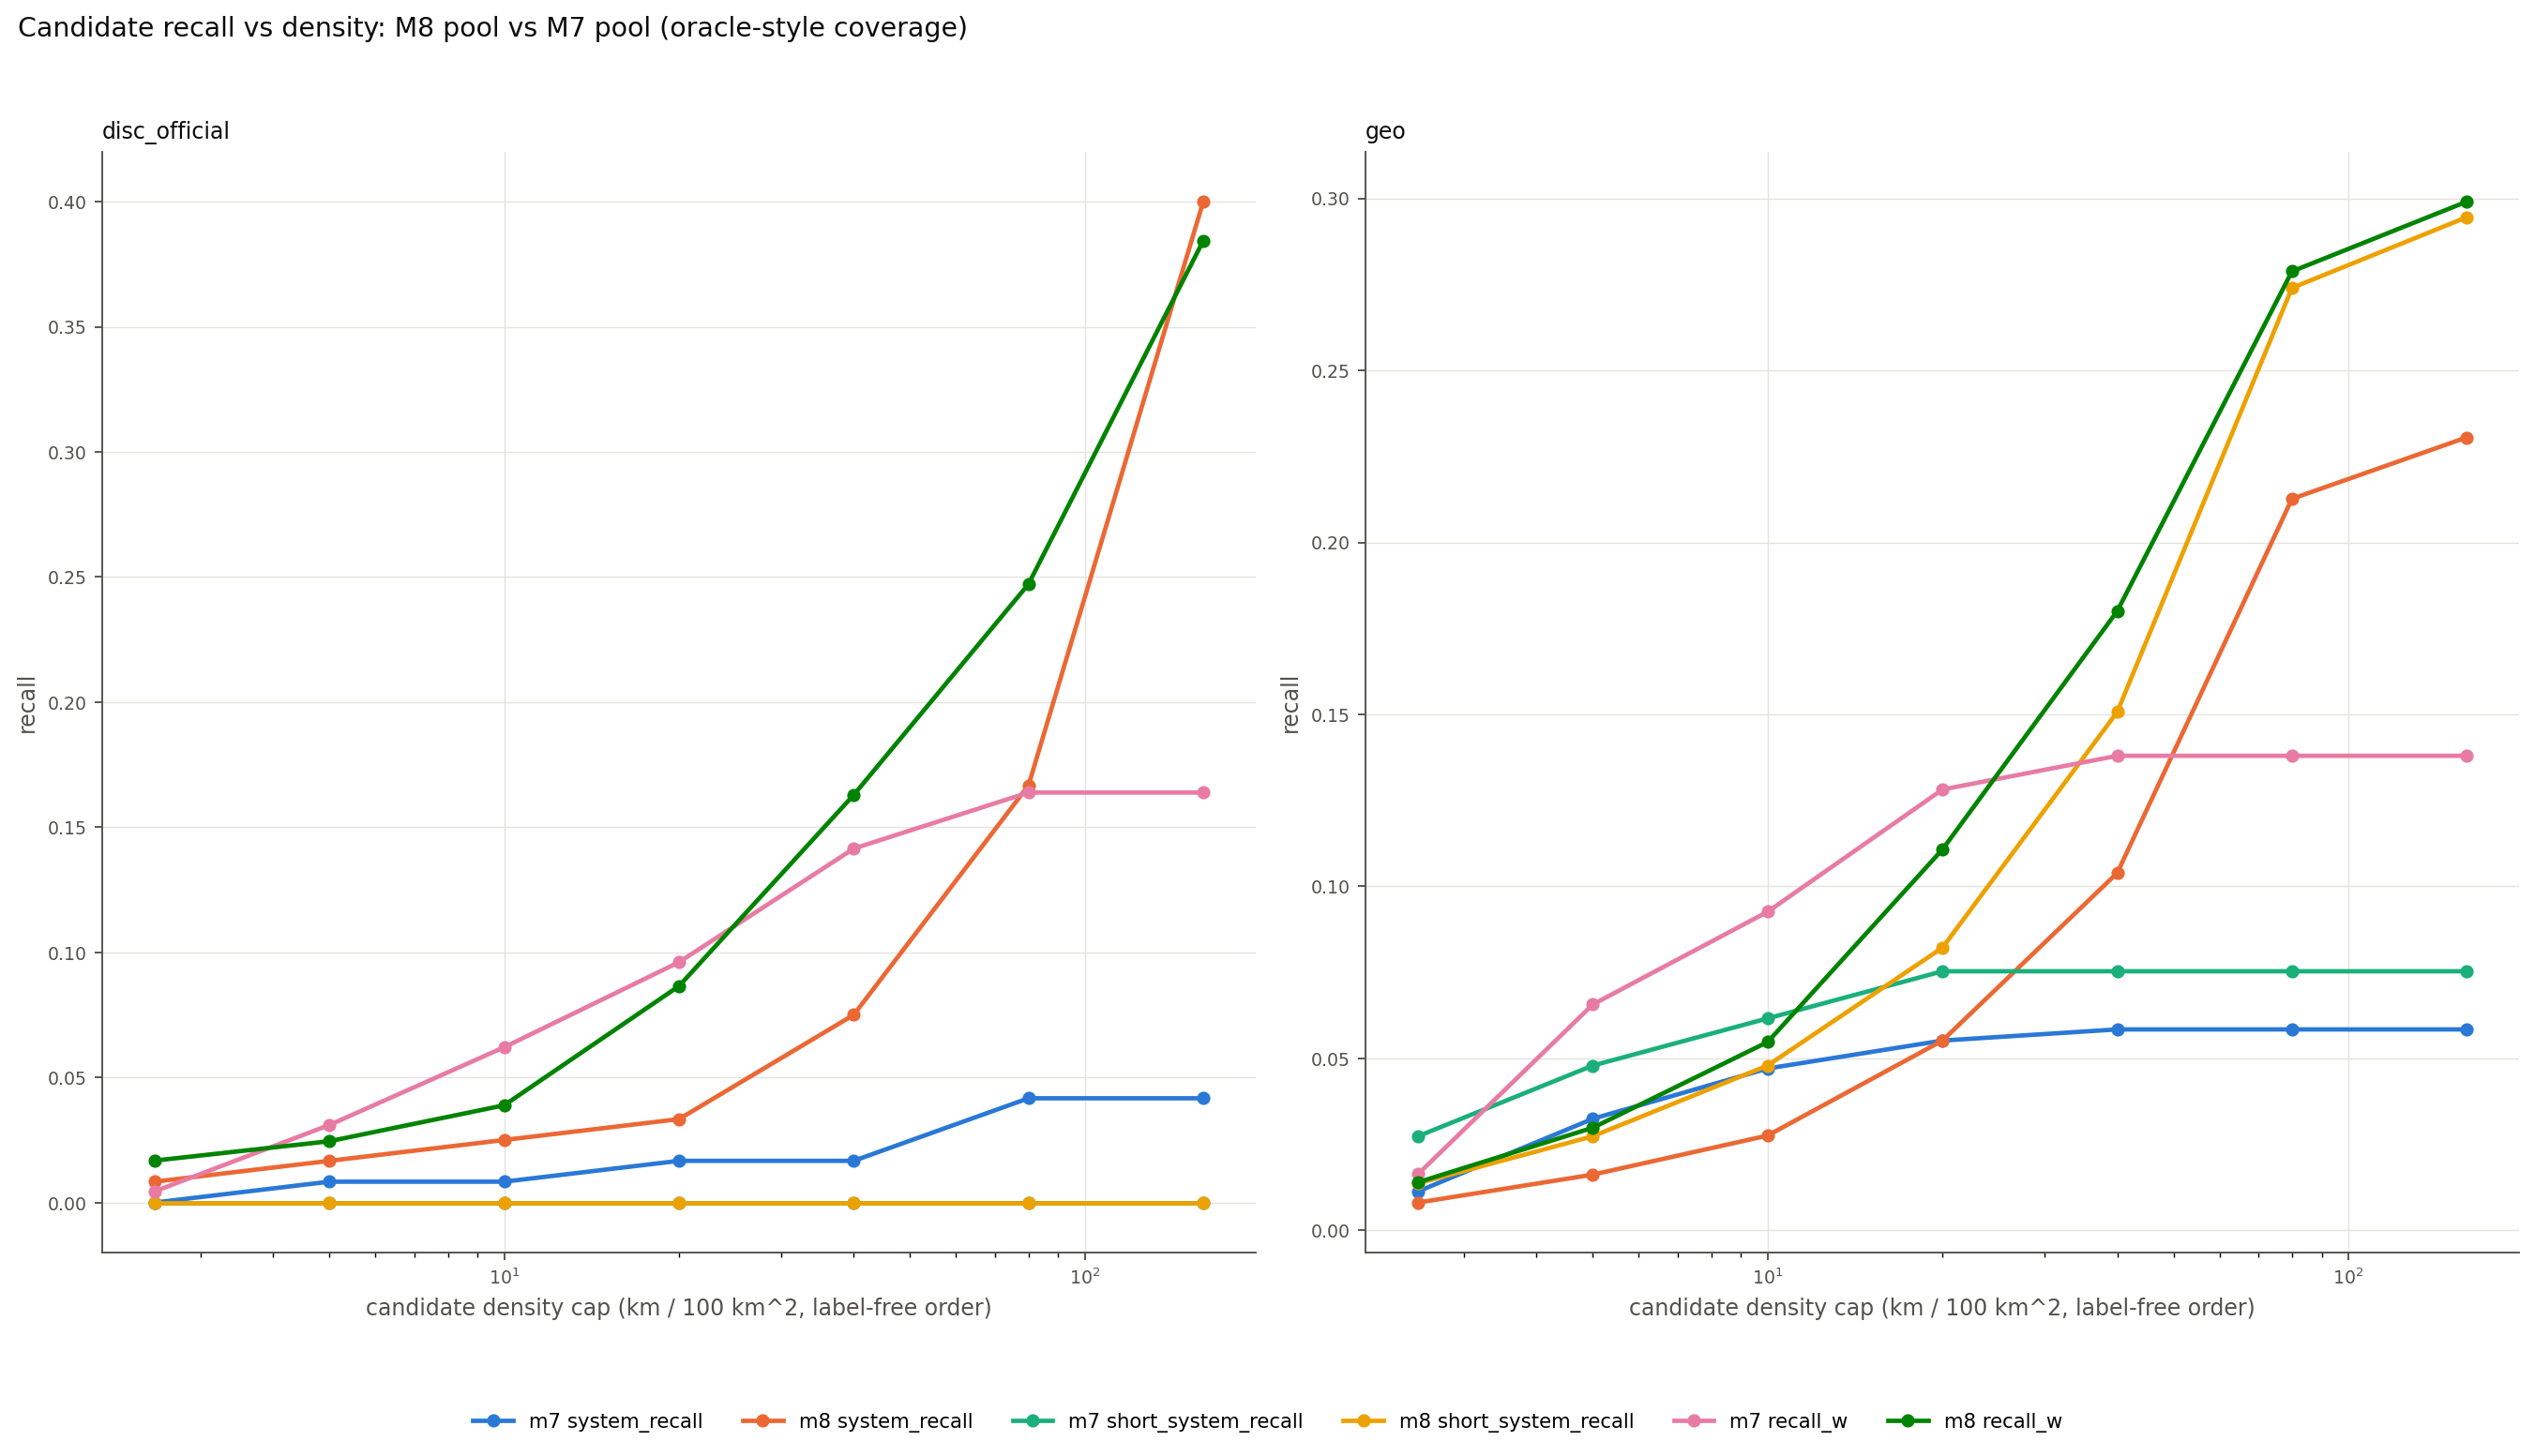

GATE 2 (primary task): NO_GO


/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)
/content/GEMS/gems_bench/m8/profiles.py:102: RuntimeWarning: All-NaN slice encountered
  out[f"{prefix}_gradient"] = float(np.nanmedian(g[:, 0]))
/content/GEMS/gems_bench/m8/profiles.py:107: RuntimeWarning: All-NaN slice encountered
  out[f"{prefix}_localization"] = float(np.nanmedian(g[:, 0] / np.maximum(gmax, 1e-12)))


[m8] s05 geo:0: 10039 candidates profiled (m8 pool)


/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)
/content/GEMS/gems_bench/m8/profiles.py:102: RuntimeWarning: All-NaN slice encountered
  out[f"{prefix}_gradient"] = float(np.nanmedian(g[:, 0]))
/content/GEMS/gems_bench/m8/profiles.py:107: RuntimeWarning: All-NaN slice encountered
  out[f"{prefix}_localization"] = float(np.nanmedian(g[:, 0] / np.maximum(gmax, 1e-12)))


[m8] s05 geo:1: 8916 candidates profiled (m8 pool)


/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)


[m8] s05 geo:2: 8813 candidates profiled (m8 pool)


/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)
/content/GEMS/gems_bench/m8/profiles.py:102: RuntimeWarning: All-NaN slice encountered
  out[f"{prefix}_gradient"] = float(np.nanmedian(g[:, 0]))
/content/GEMS/gems_bench/m8/profiles.py:107: RuntimeWarning: All-NaN slice encountered
  out[f"{prefix}_localization"] = float(np.nanmedian(g[:, 0] / np.maximum(gmax, 1e-12)))


[m8] s05 disc_official:0: 11543 candidates profiled (m8 pool)


/content/GEMS/gems_bench/m8/profiles.py:106: RuntimeWarning: All-NaN slice encountered
  gmax = np.nanmax(g, axis=1)


In [ ]:
if m8.enabled('s06_candidates'):
    s06 = m8.s06_candidates()                # builds the section-08 hypotheses first (own stage)
    sub = 'candidate_generation/oracle'
    g2 = tab('gate2', sub)
    tab('gate1', 'signal_recovery')
    pc = m8.ws.load_table('pooled_curve', sub)
    if len(pc):
        display(pc.pivot_table(index=['task', 'density_cap'], columns='pool', values='system_recall'))
    pg = m8.ws.load_table('pooled_groups', sub)
    if len(pg):
        display(pg[pg.group == 'family'].sort_values(['task', 'system_recall'], ascending=[True, False]).head(30))
    tab('incremental', sub, 30)
    tab('low_conf', sub)
    show(['recall_density_m8_vs_m7'], sub)
    print('GATE 2 (primary task):', m8.gate('gate2', sub))
    if m8.enabled('s05_fault_normal_profiles'):
        m8.s05_fault_normal_profiles()       # profiles of the M8 pool (fingerprint follows section 06)

## 07. Monte Carlo geophysical uncertainty (Gate 3)

**Research question.** Which candidates are stable under physically plausible perturbations of the fields and of the extraction choices, and does the perturbation ensemble reveal structures the deterministic pool misses?

**Geological rationale.** Edge positions depend on survey noise, registration, filter scale and thresholds; a fault-related edge should survive moderate perturbation, while noise-driven or threshold-driven crests flicker.

**Hypothesis.** Stable candidates are enriched in mapped faults; occupancy crests outside the pool add a few systems at matched density.

**Method.** Per realisation (seeded): correlated noise and one registration shift per survey family (base fields only — derived bands of one survey are never perturbed independently), scale jitter, operator choice, threshold / coherence / linking / persistence choices; the section-06 pipeline extracts lines; tolerant matching to the pool (fragments of one structure count once). Distributions are recorded in `assumptions.json`; without `measured_noise` this is a **heuristic sensitivity analysis**. Checkpointed and resumable.

**Planned diagnostic.** `stability.csv` (detection frequency, positional / orientation / length variability, fragmentation, cross-modal stability, per-family frequency), `stability_vs_truth.csv` (stable / intermediate / unstable bins: share near truth, share far, systems), `mc_only_coverage.csv`, `occupancy.tif`, `occupancy_atlas.png`.

**Success / failure criterion.** Gate 3 USE_IN_MODEL if MC-only structures add ≥ 2 systems at matched density OR (after section 11) `physics_mc` beats `physics_only` by ≥ 0.003 DTI; otherwise MC is kept for uncertainty reporting only.

**How to read the outcome.** Detection frequency is processing stability, **not** a calibrated fault probability. If stable and unstable bins have similar near-truth shares, stability will not help ranking; do not hard-filter unstable candidates without that evidence.

In [ ]:
if m8.enabled('s07_monte_carlo_signal'):
    s07 = m8.s07_monte_carlo_signal()       # PILOT: 16 realisations on one discovery unit
    sub = 'monte_carlo/stability'
    st = m8.ws.load_table('stability', sub)
    if len(st):
        display(st.describe().T)
    tab('stability_vs_truth', sub)
    tab('mc_only_coverage', sub)
    tab('gate3', sub)
    print(json.dumps(m8.read_json('monte_carlo/realizations/assumptions.json'), indent=1, default=str)[:2500])
    show(['occupancy_atlas'], 'monte_carlo/uncertainty_maps')

## 08. Monte Carlo fault-network completion

**Research question.** Can evidence-conditioned stochastic continuation, gap bridging and trace relocation recover missing mapped geometry better than the deterministic M7 completers?

**Geological rationale.** Fault traces end where mapping stopped, not where faults stop; continuations follow local strike, curvature limits and geophysical support, and branch into neighbouring traces.

**Hypothesis.** Stochastic continuations recover more truncated endpoints and gaps than straight / rotated extensions at equal false length.

**Method.** Particles from each endpoint: softmax heading choice from evidence (physics layers + optional DEM), curvature penalty, orientation-field alignment, cone limit; evidence-terminated length; joins to known traces = branching support; gap bridges with attraction; displaced-trace hypotheses. Occupancy, consensus path, diversity, displacement, continuity. Evaluated (1) on the M7 corruption benchmark (systems split by fold **before** damage; completer sees the damaged map only), per class (endpoint truncation, interior gap, lateral shift, branch, incomplete network, short fault), parameters nested; (2) on disc units as System C (eligible budget, nested frac).

**Planned diagnostic.** `benchmark/benchmark_selection.csv` (DTI, recall, distance to truth, direction agreement, added false length, delta vs best M7 completer), `system_c_summary.csv`, `coverage_audit.csv`.

**Success / failure criterion.** Stochastic completion is useful where `delta_vs_best_m7 > 0` with no increase in added false length; System C enters the section-14 fusion. Completion hypotheses are never promoted to full-region predictions automatically.

**How to read the outcome.** Pseudo-discovery withholds whole systems, so near-known extensions are under-represented here: benchmark (1) is the more relevant evidence for completion.

In [ ]:
if m8.enabled('s08_monte_carlo_completion'):
    s08 = m8.s08_monte_carlo_completion()
    tab('coverage_audit', 'fault_networks', 30)
    tab('system_c_summary', 'fault_networks')
    tab('benchmark_selection', 'fault_networks/benchmark', 40)
    show(['completion_benchmark'], 'fault_networks/benchmark')

## 09. DEM pilot and incremental value (Gate 4)

**Research question.** Does 1 m surface morphology recover withheld systems that the 100 m geophysics and the CNNs do not, at matched candidate density?

**Geological rationale.** Young normal-fault scarps are surface-expressed; buried, eroded or blind faults are not. DEM can only add the former.

**Hypothesis.** Inside the pilot footprint, DEM-including candidate sets cover a few systems that their DEM-free counterparts miss.

**Method.** Reuse M7's eight-tile pilot (~2.61 GiB estimated) and mosaic read-only; optional streaming of the pilot here (`dem_pilot.stream`, needs `shared.dem.download`). Five sets on identical DEM-covered footprints at matched density: geophysics, DEM only, geophysics ∪ DEM, CNN + geophysics, CNN + geophysics + DEM. Download volume, disk use, processing time, coverage and projected full cost are logged.

**Planned diagnostic.** `dem/candidates/results.csv`, `systems.csv`, `gate4.csv`, `dem_volume_log.csv`.

**Success / failure criterion.** Gate 4 EXPAND_TARGETED if ≥ 3 systems are in the footprint, DEM adds ≥ 2 systems and the incremental system recall is ≥ 0.05; STOP otherwise; INCONCLUSIVE if the pilot holds too few systems. A DEM failure never blocks other sections.

**How to read the outcome.** DEM-covered numbers form their own protocol and are never pooled with full-zone results.

In [ ]:
if m8.enabled('s09_dem_pilot'):
    s09 = m8.s09_dem_pilot()                 # GATE_CLOSED (logged) when no mosaic exists: other sections continue
    sub = 'dem/candidates'
    tab('gate4', sub)
    tab('results', sub, 40)
    tab('dem_volume_log', sub)
    tab('pilot_tiles', 'dem/pilot')

## 10. Candidate-level feature table *(needs Gate 2 GO)*

**Research question.** Can each candidate be described by physically interpretable, provenance-tracked evidence without hiding missing information?

**Method.** One row per candidate (section-06 pool + MC-only structures): M7 descriptors (geometry, geophysics, terrain / DEM, neural, network, PU label) + M8 physics operators along the path, worm statistics, magnetic–gravity agreement and crest classes, fault-normal profiles, Monte Carlo stability, completion occupancy, context percentiles, family provenance, explicit missingness indicators (`has_mc`, `has_dem`, `has_profile`, `has_worm_*`). Labels: 1 near scored truth, 0 far, −1 unlabelled (never a negative).

**Planned diagnostic.** `feature_tables/feature_table.parquet`, `feature_groups.csv`, `feature_provenance.csv`, `missingness.csv`, `label_balance.csv`.

**Success / failure criterion.** Every feature belongs to exactly one group used by the section-11 ablations; areas without DEM / MC are explicit, never imputed silently.

In [ ]:
if m8.enabled('s10_candidate_features'):
    s10 = m8.s10_candidate_features()        # returns None (logged) when Gate 2 is closed
    tab('label_balance', 'feature_tables')
    tab('missingness', 'feature_tables', 40)
    fg = m8.ws.load_table('feature_groups', 'feature_tables')
    if len(fg):
        display(fg.groupby('group').size())

## 11. Candidate ranking (Gate 5)

**Research question.** Can a lightweight, spatially validated ranker separate faults from unrelated structural boundaries better than label-free structure and CNN support alone?

**Geological rationale.** Lithological contacts, intrusion margins and basin edges produce edges too; combinations of agreement, profile shape, persistence and network context may discriminate fault-like edges.

**Hypothesis.** `physics_cnn` or `all` beats both controls; Monte Carlo and DEM add little on their own.

**Method.** Controls `label_free`, `cnn_only`; LightGBM `physics_only`, `physics_mc`, `physics_dem`, `physics_cnn`, `all` (optional CatBoost, PU-weight sensitivity in VALIDATE / FULL). Leave one zone out; rows near the held-out zone and every row of linked networks touching it are dropped; negatives down-weighted; scored as 1-px lines at the eligible budget with nested frac. No hyper-parameter search.

**Planned diagnostic.** `ranking/ranking_summary.csv`, `training_audit.csv`, `feature_importance.csv` (descriptive), `gate5.csv`, `ranking_dti.png`.

**Success / failure criterion.** Gate 5 PASS if the best learned ranker beats max(label_free, cnn_only) by ≥ 0.005 cross-fitted DTI; otherwise model complexity is not increased (section 13 uses the better control).

**How to read the outcome.** Ranker outputs are scores, not calibrated probabilities. Gains concentrated in one zone are not robust (see section 14).

In [ ]:
if m8.enabled('s11_ranking'):
    s11 = m8.s11_ranking()
    tab('ranking_summary', 'ranking', 40)
    tab('gate5', 'ranking')
    tab('training_audit', 'ranking', 20)
    imp = m8.ws.load_table('feature_importance', 'ranking')
    if len(imp):
        display(imp.groupby('method').head(8))
    tab('gate3', 'monte_carlo/stability')     # Gate 3 updated with the ranking gain of physics_mc
    show(['ranking_dti'], 'ranking')

## 12. Optional probabilistic fragment graph *(only after Gate 5 PASS)*

**Research question.** Do geometrically plausible connections between fragments add discovery value beyond candidate-level ranking?

**Method.** Endpoint graph (distance + tangent compatibility), edge probability (heuristic, or leave-one-zone-out LightGBM on edge features), graph-propagated scores and an optional bridges variant; connectivity, false connections between true fragments, recovered structure, cross-fitted DTI.

**Success / failure criterion.** Retained only if it beats the section-11 score by ≥ 0.005 DTI; otherwise the simpler ranker stays. No large GNN.

In [ ]:
if m8.enabled('s12_graph'):
    s12 = m8.s12_graph()
    tab('graph_summary', 'graphs')
    tab('graph_metrics', 'graphs')
    tab('graph_decision', 'graphs')

## 13. Probabilistic rasterisation

**Research question.** How should ranked candidates and their Monte Carlo geometry become a scoremap on the exact 100 m grid?

**Method.** Thin centerlines; occupancy-weighted selection (budget moves to perturbation-stable positions); uncertainty-aware spreading (width from MC positional dispersion, ≤ 2 px, decaying); confidence-dependent width; crest-based selection; regional rank blend (20 km blocks) to control density; optional 300 m ring. Eligible budget; mass and non-zero area after all masks recorded; (rep, regional β, frac, ring) nested.

**Planned diagnostic.** `rasterization_summary.csv`, `rasterization_ablation.csv`, `area_mass_ledger.csv`, `representation_ablation.png`.

**Success / failure criterion.** The best representation becomes System B (`validation/maps/m8_physics`). The 300 m scoring tolerance is **not** an instruction to draw 300 m corridors: wide representations must earn their place in the ablation.

In [ ]:
if m8.enabled('s13_rasterization'):
    s13 = m8.s13_rasterization()
    sub = 'rasterization'
    tab('rasterization_summary', sub)
    tab('rasterization_ablation', sub, 40)
    tab('area_mass_ledger', sub, 20)
    show(['representation_ablation'], sub)

## 14. Ensemble and champion selection (Gate 6)

**Research question.** Do the physics system (B), network completion (C) or their cross-fitted fusion with the CNN champion (A) improve deployable official-style DTI while staying geographically robust?

**Method.** Per-zone percentile scores of A, B, C; fusions A, B, C, A+B, A+C, A+B+C on a weight simplex; weights, representation and frac chosen on the other zones. Every saved held-out map is re-scored by M7's comparison: geographic DTI, `disc_official`, retained-FP alternative, worst zone, system / length / short-fault recall, density, regional DTI, known-fault proximity, paired zone deltas, paired spatial block bootstrap; plus candidate false-length density (unlabelled, an upper bound). Verdicts: PROMOTE / RETAIN / REJECT / INCONCLUSIVE.

**Success / failure criterion.** Gate 6 PROMOTE only when a method passes every promotion rule (pooled gain ≥ 0.01, wins ≥ 2/3 of zones, worst zone ≥ −0.01, geo drop ≤ 0.01, bootstrap P(Δ > 0) ≥ 0.8, short-fault recall drop ≤ 0.02); otherwise the B0/B1 champion is retained. Oracle values never enter.

**How to read the outcome.** With three folds and three splits, paired deltas are descriptive evidence; millions of correlated pixels do not make a difference significant.

In [ ]:
if m8.enabled('s14_ensemble'):
    s14 = m8.s14_ensemble()
    tab('fusion_summary', 'ensemble', 40)
    sub = 'validation/metrics'
    tab('method_pooled', sub, 60)
    pz = m8.ws.load_table('paired_zone_deltas', sub)
    if len(pz):
        display(pz.pivot_table(index=['task', 'method'], columns='zone', values='delta_vs_ref'))
    tab('bootstrap', sub, 40)
    tab('false_length', sub, 40)
    tab('decision_verdicts', 'reports', 40)
    gates = tab('gates', 'reports')
    ans = m8.ws.load_table('research_answers', 'reports')
    for r in ans.itertuples() if len(ans) else []:
        display(Markdown(f'**{r.question}** {r.answer}  \n_{r.evidence}_'))
    show(['method_comparison', 'system_recall_comparison', 'paired_zone_deltas', 'known_proximity_recall',
          'regional_dti'], 'validation/figures')
    print('report:', OUT / 'reports' / 'M8_PHYSICS_PROBABILISTIC_REPORT.md')

## 15. Leaderboard submission files *(off by default; never uploaded)*

**Method.** Always: the CNN champion without the ring and with the optional 300 m ring at the same number of selected pixels (isolates the ring hypothesis). Only if Gate 6 PROMOTES an M8 method: the physics champion (full-region pool → features → refitted ranker → section-13 rasterisation, or the promoted fusion). Shared, corrected GEMS3 writer: template = authority (shape, CRS, transform, bounds, nodata), NaN where the template is NaN, float32 in [0, 1], eligible budget after masks, area ledger, validation that raises on failure, manifest with provenance. Existing files are never overwritten. `leaderboard_log.csv` keeps public scores (filled manually), offline proxies and oracle diagnostics in separate columns.

**Success / failure criterion.** Every written file passes validation. Respect the competition's submission limits; never tune dozens of variants on public feedback.

In [ ]:
if m8.enabled('s15_submission'):
    s15 = m8.s15_submission()
    tab('submission_index', 'submissions')
    for f in sorted((OUT / 'submissions').glob('*.json')):
        j = json.loads(f.read_text())
        if 'area_ledger' in j:
            print(f.name)
            display(pd.DataFrame(j['area_ledger']))
    display(pd.read_csv(OUT / 'submissions' / 'leaderboard_log.csv'))

## Run log, outputs and resume

Re-running any cell reuses finished stages (fingerprints in `manifests/units/`); the Monte Carlo engine resumes from its last checkpoint. After a disconnect: run the setup cells, then any section. To scale up, set `M8_CONFIG['profile'] = 'VALIDATE'` (scope only). Baselines, physics layers, worms and multimodal layers are reused, and so is the label-free candidate cache. Section 02 re-runs because VALIDATE adds the `geo` task. Section 06 re-runs because the full-region pool is in VALIDATE's scope, so everything downstream of it (Monte Carlo, completion samples, galleries, features, ranking) is recomputed. Read first: `baseline/compatibility.csv`, `signal_recovery/reasons.csv`, `candidate_generation/oracle/gate2.csv`, `reports/gates.csv`, `reports/M8_PHYSICS_PROBABILISTIC_REPORT.md`.

In [ ]:
display(pd.DataFrame(m8.log)) if m8.log else print('no stage ran in this session')
display(m8.summary())
m8.paths()
pipe.push_all()